In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
#import pycountry
#import pycountry_convert as pc
import datetime
import scipy.stats as stt
#from collections import Counter
from wordcloud import WordCloud, STOPWORDS
import emoji
from tqdm import tqdm

import nltk
from nltk.corpus import stopwords

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_extraction.text import CountVectorizer

import re

In [3]:
nltk.download('wordnet')
nltk.download('stopwords')
nltk.download('punkt')

[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/sheffdeen/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/sheffdeen/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /Users/sheffdeen/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [5]:
s = set(STOPWORDS)
sw = stopwords.words('english')
sw += s
len(sw)

390

In [7]:
reddit = pd.read_csv ('//Users//sheffdeen//Downloads//Chapter4-Zahra//Reddit//FinalDataReddit.csv')
pd.set_option('display.max_columns', None)
reddit.head()

/var/folders/hv/1wjfjdqn1ws_kws3tmwgk9f00000gn/T/ipykernel_50128/1548702240.py:1: DtypeWarning: Columns (2,15,16,21,22,23,25,26,31,35,40,42,43,45,47,49,53,56,66,68,73,74,75,78,80,81,83) have mixed types. Specify dtype option on import or set low_memory=False.
  reddit = pd.read_csv ('//Users//sheffdeen//Downloads//Chapter4-Zahra//Reddit//FinalDataReddit.csv')


,subreddit_id,approved_at_utc,author_is_blocked,comment_type,edited,mod_reason_by,banned_by,ups,num_reports,author_flair_type,total_awards_received,subreddit,author_flair_template_id,likes,replies,user_reports,saved,id,banned_at_utc,mod_reason_title,gilded,archived,collapsed_reason_code,no_follow,author,can_mod_post,send_replies,parent_id,score,author_fullname,report_reasons,removal_reason,approved_by,all_awardings,body,awarders,top_awarded_type,downs,author_flair_css_class,author_patreon_flair,collapsed,author_flair_richtext,is_submitter,body_html,gildings,collapsed_reason,associated_award,stickied,author_premium,can_gild,link_id,unrepliable_reason,author_flair_text_color,score_hidden,permalink,subreddit_type,locked,name,created,author_flair_text,treatment_tags,created_utc,subreddit_name_prefixed,controversiality,author_flair_background_color,collapsed_because_crowd_control,mod_reports,mod_note,distinguished,date,author_created_utc,retrieved_on,retrieved_utc,quarantined,steward_reports,editable,author_cakeday,updated_utc,body_sha1,nest_level,utc_datetime_str,rte_mode,edited_on,media_metadata,CleanedText,Date,Week,Sentiment,Positive,Neutral,Negative,Emotion,Other,Anger,Disgust,Fear,Sadness,Joy,Surprise
0,t5_37mg1,NaN,False,NaN,False,NaN,NaN,1.0,NaN,text,0.0,FishingSaskatchewan,NaN,NaN,NaN,[],False,l8y2bin,NaN,NaN,0,False,NaN,True,colem5000,False,True,t3_14xpkwc,1,t2_2pn8ch5x,NaN,NaN,NaN,[],Bottom bounce at the mouth of the lake.,[],NaN,0.0,NaN,False,False,[],False,"&lt;div class=""md""&gt;&lt;p&gt;Bottom bounce a...",{},NaN,NaN,False,False,False,t3_14xpkwc,NaN,NaN,False,/r/FishingSaskatchewan/comments/14xpkwc/tobin_...,restricted,False,t1_l8y2bin,1.718591e+09,NaN,[],2024-06-17 02:18:41,r/FishingSaskatchewan,0,NaN,NaN,[],NaN,NaN,2024-06-16 22:18:41,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Bottom bounce at the mouth of the lake.,2024-06-17,2024-06-17,NEU,0.034740,0.956538,0.008721,others,0.976141,0.002050,0.005775,0.003888,0.001354,0.007159,0.003632
1,t5_37mg1,NaN,False,NaN,False,NaN,NaN,1.0,NaN,text,0.0,FishingSaskatchewan,NaN,NaN,NaN,[],False,l6x69af,NaN,NaN,0,False,NaN,True,dycker1978,False,True,t3_148izsi,1,t2_14ciqw,NaN,NaN,NaN,[],"Buffalo Pound has a provincial park on, that i...",[],NaN,0.0,NaN,False,False,[],False,"&lt;div class=""md""&gt;&lt;p&gt;Buffalo Pound h...",{},NaN,NaN,False,False,False,t3_148izsi,NaN,NaN,False,/r/FishingSaskatchewan/comments/148izsi/where_...,restricted,False,t1_l6x69af,1.717428e+09,NaN,[],2024-06-03 15:13:43,r/FishingSaskatchewan,0,NaN,NaN,[],NaN,NaN,2024-06-03 11:13:43,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"Buffalo Pound has a provincial park on, that i...",2024-06-03,2024-06-03,POS,0.725779,0.271237,0.002984,others,0.976320,0.001198,0.002544,0.002754,0.001711,0.012905,0.002568
2,t5_37mg1,NaN,False,NaN,False,NaN,NaN,1.0,NaN,text,0.0,FishingSaskatchewan,NaN,NaN,NaN,[],False,kdvyfdh,NaN,NaN,0,False,NaN,True,chihorse,False,True,t1_kdtk9p2,1,t2_axgk3t1n,NaN,NaN,NaN,[],Thanks!!,[],NaN,0.0,NaN,False,False,[],True,"&lt;div class=""md""&gt;&lt;p&gt;Thanks!!&lt;/p&...",{},NaN,NaN,False,False,False,t3_158m7cq,NaN,NaN,False,/r/FishingSaskatchewan/comments/158m7cq/fishin...,restricted,False,t1_kdvyfdh,1.702905e+09,NaN,[],2023-12-18 13:16:41,r/FishingSaskatchewan,0,NaN,NaN,[],NaN,NaN,2023-12-18 08:16:41,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Thanks!!,2023-12-18,2023-12-18,POS,0.988689,0.009532,0.001779,joy,0.076444,0.003595,0.001692,0.001114,0.001468,0.913222,0.002465
3,t5_37mg1,NaN,False,NaN,False,NaN,NaN,1.0,NaN,text,0.0,FishingSaskatchewan,NaN,NaN,NaN,[],False,kdtk9p2,NaN,NaN,0,False,NaN,True,Dull_General_6825,False,True,t3_158m7cq,1,t2_46xt0m46,NaN,NaN,NaN,[],There is definitely shore access at Zelma. I s...,[],NaN,0.0,NaN,False,False,[],False,"&lt;div class=""md""&gt;&lt;p&gt;There is defini...",{},NaN,NaN,False,False,False,t3_158m7cq,NaN,NaN,False,/r/FishingSaskatchewan/comments/158m7cq/fishin...,restricted,False,t1_kdtk9p2,1.702856e+09,NaN,[],2023-1

In [9]:
def remove_emojis(data):
    emoj = re.compile("["
        u"\U0001F600-\U0001F64F"  # emoticons
        u"\U0001F300-\U0001F5FF"  # symbols & pictographs
        u"\U0001F680-\U0001F6FF"  # transport & map symbols
        u"\U0001F1E0-\U0001F1FF"  # flags (iOS)
        u"\U00002500-\U00002BEF"  # chinese char
        u"\U00002702-\U000027B0"
        u"\U000024C2-\U0001F251"
        u"\U0001f926-\U0001f937"
        u"\U00010000-\U0010ffff"
        u"\u2640-\u2642" 
        u"\u2600-\u2B55"
        u"\u200d"
        u"\u23cf"
        u"\u23e9"
        u"\u231a"
        u"\ufe0f"  # dingbats
        u"\u3030"
                      "]+", re.UNICODE)
    return re.sub(emoj, '', data)

In [11]:
reddit = reddit[~pd.isnull(reddit['CleanedText'])]

In [13]:
reddit = reddit.reset_index (drop= True)

In [15]:
txt = [remove_emojis(x) for x in list(reddit['CleanedText'])]

In [17]:
#Remove stop words
t = []
for x in txt:
    dummy = x.split ()
    tt = [item.lower() for item in dummy if item.lower() not in sw]
    t.append (' '.join(tt))
len(t)

67875

In [18]:
# Fixing the punctuations, removing all
txt = []
for x in tqdm (t):
    dummy = x.replace('.', '')
    dummy = dummy.replace('!', '')
    dummy = dummy.replace('?', '')
    dummy = dummy.replace ('(', '')
    dummy = dummy.replace (')', '')
    dummy = dummy.replace (',', '')
    dummy = dummy.replace ('"', '')
    txt.append (dummy)

100%|█████████████████████████████████| 67875/67875 [00:00<00:00, 696481.94it/s]


In [23]:
#Necessary for lemmatization
import en_core_web_md
nlp = en_core_web_md.load()

In [25]:
def lemmatization (texts, allowed_postags=['NOUN','ADJ','VERB']):
    texts_out = []
    for text in texts:
        doc = nlp(text)
        new_text = []
        for token in doc:
            if token.pos_ in allowed_postags:
                new_text.append (token.lemma_)
        final = " ".join(new_text)
        texts_out.append (final)
    return (texts_out)

In [27]:
tt = lemmatization (txt)

In [28]:
# Tokenization
def tokenize (texts):
    tokens = [word for word in nltk.word_tokenize(texts) if len(word) > 2]
    return tokens

In [29]:
tok = [tokenize(item) for item in tqdm(tt)]

100%|██████████████████████████████████| 67875/67875 [00:03<00:00, 22445.12it/s]


In [37]:
# Vectorize
vectorizer_tfidf = TfidfVectorizer (tokenizer=tokenize, stop_words='english', max_df=0.75, min_df=50,  use_idf=True, norm=None) #max_features=10000,

In [39]:
df1 = pd.DataFrame(data={'Text':tt})
tfidf_vectors = vectorizer_tfidf.fit_transform (df1['Text'])

/opt/anaconda3/lib/python3.12/site-packages/sklearn/feature_extraction/text.py:517: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


In [41]:
import pickle
with open('C:\\Users\\sherif.s\\Fish Analysis\\vectorizer_tfidf.pk', 'wb') as f:
     pickle.dump(vectorizer_tfidf, f)

import scipy.sparse
scipy.sparse.save_npz('C:\\Users\\sherif.s\\Fish Analysis\\tfidf_vectors.npz', tfidf_vectors)

In [43]:
# Save this model with 20 topics:
import pickle
with open("C:\\Users\\sherif.s\\Fish Analysis\\vectorizer_tfidf.pk","rb") as f:
    vectorizer_tfidf = pickle.load (f)

import scipy.sparse
tfidf_vectors = scipy.sparse.load_npz('C:\\Users\\sherif.s\\Fish Analysis\\tfidf_vectors.npz')

In [ ]:
# Find Best Number of Topics

In [45]:
import tmtoolkit
from sklearn.decomposition import LatentDirichletAllocation
from tmtoolkit.topicmod.evaluate import metric_coherence_gensim
from statistics import mean
from sklearn.metrics import jaccard_score

In [73]:
# coh0 = 0
# js0 = 100
# ppx0 = 100
# num = 1
# for topic_num in range (5, 20):
#    lda = LatentDirichletAllocation (n_components=topic_num, learning_method='online', learning_offset=50, n_jobs=-1, random_state=111)
#    # n_components is the number of topics

#    w1 = lda.fit_transform (tfidf_vectors)
#    #h1 = lda.components_

#    ppx = lda.perplexity(w1,  sub_sampling=False)

#    coh = mean (metric_coherence_gensim(measure='c_v', top_n=20, topic_word_distrib=lda.components_, vocab=np.array([x for x in vectorizer_tfidf.vocabulary_.keys()]), texts=tok))

#    l = len (lda.components_)
#    n = 0
#    js = 0
#    for i in range(0, l-1):
#      topic1 = [1 if x>1 else 0 for x in lda.components_[i]]
#      for j in range(i+1, l):
#        topic2 = [1 if x>1 else 0 for x in lda.components_[j]]
#        js += jaccard_score (topic1, topic2)
#        n += 1
#    js /= n

#    if js > js0 and coh < coh0 and ppx > ppx0:
#      pass
#    else:
#      num = topic_num
#      js0 = js
#      coh0 = coh
#      ppx0 = ppx

#    print ('num_topic: ', topic_num, 'Coherence: ', coh, 'Jaccard: ', js, 'Perplexity: ', ppx)

/opt/anaconda3/lib/python3.12/site-packages/joblib/externals/loky/backend/fork_exec.py:38: DeprecationWarning: This process (pid=39162) is multi-threaded, use of fork() may lead to deadlocks in the child.
  pid = os.fork()
/opt/anaconda3/lib/python3.12/site-packages/joblib/externals/loky/backend/fork_exec.py:38: DeprecationWarning: This process (pid=39162) is multi-threaded, use of fork() may lead to deadlocks in the child.
  pid = os.fork()
/opt/anaconda3/lib/python3.12/site-packages/joblib/externals/loky/backend/fork_exec.py:38: DeprecationWarning: This process (pid=39162) is multi-threaded, use of fork() may lead to deadlocks in the child.
  pid = os.fork()
/opt/anaconda3/lib/python3.12/site-packages/joblib/externals/loky/backend/fork_exec.py:38: DeprecationWarning: This process (pid=39162) is multi-threaded, use of fork() may lead to deadlocks in the child.
  pid = os.fork()
/opt/anaconda3/lib/python3.12/site-packages/joblib/externals/loky/backend/fork_exec.py:38: DeprecationWarnin

num_topic:  5 Coherence:  0.43371622695591683 Jaccard:  0.18011302852875047 Perplexity:  13165.735673516605
num_topic:  6 Coherence:  0.4477792645986563 Jaccard:  0.14518893687343878 Perplexity:  18006.24115778905
num_topic:  7 Coherence:  0.4459618537832779 Jaccard:  0.12504130289967022 Perplexity:  25062.362411872145
num_topic:  8 Coherence:  0.43527243273204363 Jaccard:  0.10707282035589319 Perplexity:  29686.132844373777
num_topic:  9 Coherence:  0.4543478186500698 Jaccard:  0.08916687583342284 Perplexity:  28772.00389415768
num_topic:  10 Coherence:  0.440014192379853 Jaccard:  0.07756484411250936 Perplexity:  49947.474517378025
num_topic:  11 Coherence:  0.4292139382336478 Jaccard:  0.06775663012939569 Perplexity:  51983.11604712152
num_topic:  12 Coherence:  0.4100862330469847 Jaccard:  0.060271932148040594 Perplexity:  56728.4685153089
num_topic:  13 Coherence:  0.4205499241884803 Jaccard:  0.05492434955536083 Perplexity:  115379.19393315462
num_topic:  14 Coherence:  0.4165840

In [47]:
js0 = 100
ppx0 = 100
num = 1

best_score = -float('inf')  # initialize best score
best_metrics = (None, None, None)

for topic_num in range(5, 20):
    lda = LatentDirichletAllocation(n_components=topic_num, learning_method='online', learning_offset=50, n_jobs=-1, random_state=111)
    w1 = lda.fit_transform(tfidf_vectors)

    ppx = lda.perplexity(tfidf_vectors)  # use tfidf_vectors here
    coh = mean(metric_coherence_gensim(
        measure='c_v',
        top_n=20,
        topic_word_distrib=lda.components_,
        vocab=np.array([x for x in vectorizer_tfidf.vocabulary_.keys()]),
        texts=tok
    ))

    l = len(lda.components_)
    n = 0
    js = 0
    for i in range(0, l-1):
        topic1 = [1 if x > 1 else 0 for x in lda.components_[i]]
        for j in range(i+1, l):
            topic2 = [1 if x > 1 else 0 for x in lda.components_[j]]
            js += jaccard_score(topic1, topic2)
            n += 1
    js /= n

    # ---- Weighted scoring logic ----
    alpha = 5     # weight for coherence (more important)
    beta = 3      # weight for jaccard (moderate)
    gamma = 0.01  # weight for perplexity (least important)

    score = alpha * coh - beta * js - gamma * ppx

    if score > best_score:
        best_score = score
        num = topic_num
        js0 = js
        coh0 = coh
        ppx0 = ppx
        best_metrics = (coh, js, ppx)

    print('num_topic:', topic_num, 'Coherence:', coh, 'Jaccard:', js, 'Perplexity:', ppx, 'Score:', score)

# ---- Final Output ----
print('\nBest Result Based on Weighted Score:')
print('Best num_topic:', num)
print('Coherence:', best_metrics[0])
print('Jaccard:', best_metrics[1])
print('Perplexity:', best_metrics[2])
print('Score:', best_score)

num_topic: 5 Coherence: 0.43371622695591683 Jaccard: 0.18011302852875047 Perplexity: 720.1013991829849 Score: -5.572771942636516
num_topic: 6 Coherence: 0.4477792645986563 Jaccard: 0.14518893687343878 Perplexity: 718.3218683443221 Score: -5.379889171070256
num_topic: 7 Coherence: 0.4459618537832779 Jaccard: 0.12504130289967022 Perplexity: 711.4381341075157 Score: -5.259695980857778
num_topic: 8 Coherence: 0.43527243273204363 Jaccard: 0.10707282035589319 Perplexity: 690.2699271918927 Score: -5.04755556932639


/opt/anaconda3/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:752: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


num_topic: 9 Coherence: 0.4543478186500698 Jaccard: 0.08916687583342284 Perplexity: 673.1771499506591 Score: -4.727533033756511
num_topic: 10 Coherence: 0.440014192379853 Jaccard: 0.07756484411250936 Perplexity: 658.2994606154157 Score: -4.61561817659242
num_topic: 11 Coherence: 0.4292139382336478 Jaccard: 0.06775663012939569 Perplexity: 650.5124070505246 Score: -4.5623242697251944
num_topic: 12 Coherence: 0.4100862330469847 Jaccard: 0.060271932148040594 Perplexity: 639.2253340059161 Score: -4.5226379712683595
num_topic: 13 Coherence: 0.4205499241884803 Jaccard: 0.05492434955536083 Perplexity: 625.3394013129904 Score: -4.315417440853585
num_topic: 14 Coherence: 0.4165840668629217 Jaccard: 0.05540584520246529 Perplexity: 617.259460725563 Score: -4.255891808548418
num_topic: 15 Coherence: 0.41097308944239225 Jaccard: 0.04735147163431757 Perplexity: 605.7970818692501 Score: -4.145159786383492
num_topic: 16 Coherence: 0.41019861250830186 Jaccard: 0.04500002360124871 Perplexity: 589.4929994

In [ ]:
# Topic Modeling

In [49]:
import pyLDAvis
import pyLDAvis.sklearn

In [51]:
lda = LatentDirichletAllocation (n_components=18, learning_method='online', learning_offset=50, n_jobs=-1, random_state=111)
# n_components is the number of topics

w1 = lda.fit_transform (tfidf_vectors)
h1 = lda.components_

In [53]:
import pickle
with open('C:\\Users\\sherif.s\\Fish Analysis\\lda.pk',"wb") as f1:
    pickle.dump (lda, f1)

import pickle
lda = LatentDirichletAllocation (n_components=8, learning_method='online', learning_offset=50, n_jobs=-1, random_state=111)
with open('C:\\Users\\sherif.s\\Fish Analysis\\lda.pk',"rb") as f1:
    lda = pickle.load (f1)

In [55]:
# Patch the method to make pyLDAvis work with TfidfVectorizer
vectorizer_tfidf.get_feature_names = vectorizer_tfidf.get_feature_names_out

# Now this works
pyLDAvis.enable_notebook()
pyLDAvis.sklearn.prepare(lda, tfidf_vectors, vectorizer_tfidf)

/opt/anaconda3/lib/python3.12/site-packages/pyLDAvis/_prepare.py:247: FutureWarning: In a future version of pandas all arguments of DataFrame.drop except for the argument 'labels' will be keyword-only.
  by='saliency', ascending=False).head(R).drop('saliency', 1)
/opt/anaconda3/lib/python3.12/site-packages/pandas/core/dtypes/cast.py:1641: DeprecationWarning: np.find_common_type is deprecated.  Please use `np.result_type` or `np.promote_types`.
See https://numpy.org/devdocs/release/1.25.0-notes.html and the docs for more information.  (Deprecated NumPy 1.25)
  return np.find_common_type(types, [])
/opt/anaconda3/lib/python3.12/site-packages/pandas/core/computation/expr.py:558: DeprecationWarning: Attribute n is deprecated and will be removed in Python 3.14; use value instead
  return self.const_type(node.n, self.env)


PreparedData(topic_coordinates=              x         y  topics  cluster       Freq
topic                                                
5     -0.238011  0.008042       1        1  12.050369
15    -0.059085 -0.073357       2        1   7.788052
14    -0.250515  0.016242       3        1   7.081413
0     -0.162325  0.051781       4        1   5.939143
13    -0.150662 -0.035845       5        1   5.841919
4      0.176046  0.043036       6        1   5.249649
1      0.139625 -0.026296       7        1   5.204252
6      0.098548 -0.149354       8        1   5.127710
10     0.122047  0.251443       9        1   5.000032
2      0.131894  0.001837      10        1   4.985893
17     0.028318  0.064324      11        1   4.904644
12    -0.140857 -0.037553      12        1   4.868010
11     0.031522  0.270666      13        1   4.630429
9      0.114381 -0.266792      14        1   4.404930
8      0.129411 -0.044616      15        1   4.346917
7      0.012931 -0.052816      16        1   4.230487
3     -0.077328 -0.045612      17        1   4.188881
16     0.094061  0.024871      18        1   4.157272, topic_info=           Term          Freq         Total Category  logprob  loglift
226       catch  28045.000000  28045.000000  Default  30.0000  30.0000
871        look  17954.000000  17954.000000  Default  29.0000  29.0000
1543      thank  16561.000000  16561.000000  Default  28.0000  28.0000
1546      think  16782.000000  16782.000000  Default  27.0000  27.0000
374         day  14672.000000  14672.000000  Default  26.0000  26.0000
...         ...           ...           ...      ...      ...      ...
358     curious   1622.813296   1623.807924  Topic18  -4.4813   3.1797
409   difficult   1462.216115   1463.210743  Topic18  -4.5855   3.1796
599      freeze   1391.903397   1392.898025  Topic18  -4.6348   3.1796
1610        try   6346.388308  15261.963159  Topic18  -3.1175   2.3028
892        make   5808.680192  16684.187072  Topic18  -3.2061   2.1252

[689 rows x 6 columns], token_table=      Topic      Freq       Term
term                            
4        11  0.999816       able
7         1  0.000817     access
7         3  0.000545     access
7         5  0.997862     access
7         8  0.000545     access
...     ...       ...        ...
1722     13  0.003286       year
1723     10  0.999668     yellow
1724     16  0.999233  yesterday
1726     17  0.999756    youtube
1727      7  0.999861       zone

[914 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[6, 16, 15, 1, 14, 5, 2, 7, 11, 3, 18, 13, 12, 10, 9, 8, 4, 17])

In [57]:
w1 = lda.transform (tfidf_vectors)

In [59]:
w1.shape

(67875, 18)

In [61]:
# Print the topics with their terms
terms = vectorizer_tfidf.get_feature_names_out() #[x for x in vectorizer_tf.vocabulary_.keys()]
lda_components = lda.components_
for index, component in enumerate(lda_components):
    zipped = zip(terms, component)
    top_terms_key=sorted(zipped, key = lambda t: t[1], reverse=True)[:10]
    top_terms_list=list(dict(top_terms_key).keys())
    print("Topic "+str(index)+ ": ",top_terms_list)

Topic 0:  ['know', 'lol', 'great', 'right', 'specie', 'live', 'say', 'tell', 'different', 'love']
Topic 1:  ['fly', 'post', 'new', 'zone', 'action', 'plan', 'low', 'add', 'net', 'lose']
Topic 2:  ['work', 'jig', 'head', 'use', 'believe', 'lur', 'kayak', 'walk', 'kid', 'tail']
Topic 3:  ['carp', 'limit', 'read', 'guide', 'video', 'info', 'experience', 'angler', 'pick', 'population']
Topic 4:  ['large', 'remove', 'carbon', 'tax', 'pay', 'high', 'issue', 'idea', 'sound', 'number']
Topic 5:  ['catch', 'fish', 'pike', 'nice', 'small', 'good', 'spot', 'bass', 'walleye', 'big']
Topic 6:  ['thing', 'buy', 'hold', 'cost', 'understand', 'reg', 'free', 'wind', 'road', 'fuel']
Topic 7:  ['look', 'thank', 'boat', 'regulation', 'gear', 'awesome', 'advice', 'matter', 'sit', 'crazy']
Topic 8:  ['fall', 'spring', 'deep', 'white', 'wrong', 'shallow', 'today', 'cause', 'include', 'bunch']
Topic 9:  ['area', 'want', 'place', 'park', 'fine', 'body', 'early', 'option', 'follow', 'country']
Topic 10:  ['peop

In [63]:
import pandas as pd
import numpy as np

# Get topic distribution for each post
topic_assignments = []
for i, doc in enumerate(lda.transform(tfidf_vectors)):  # Transform the dataset to get topic probabilities
    dominant_topic = np.argmax(doc)  # Get the topic with the highest probability
    topic_assignments.append((i, dominant_topic, max(doc)))  # Store the index, topic, and confidence score

# Convert to DataFrame
df_topics = pd.DataFrame(topic_assignments, columns=['Post_Index', 'Topic', 'Confidence'])

# Merge with the original dataset to view sample posts
df_sampled = pd.merge(df_topics, reddit[['CleanedText']], left_on='Post_Index', right_index=True)

# Print 3 sample posts for each topic
for topic_num in range(len(lda.components_)):  # Loop through all topics
    print(f"\n🔹 Sample posts for Topic {topic_num}:")
    print(df_sampled[df_sampled['Topic'] == topic_num].sample(60, random_state=42)['CleanedText'].tolist())  # Randomly sample 3 posts per topic


/opt/anaconda3/lib/python3.12/site-packages/joblib/externals/loky/backend/fork_exec.py:38: DeprecationWarning: This process (pid=50128) is multi-threaded, use of fork() may lead to deadlocks in the child.
  pid = os.fork()
/opt/anaconda3/lib/python3.12/site-packages/joblib/externals/loky/backend/fork_exec.py:38: DeprecationWarning: This process (pid=50128) is multi-threaded, use of fork() may lead to deadlocks in the child.
  pid = os.fork()
/opt/anaconda3/lib/python3.12/site-packages/joblib/externals/loky/backend/fork_exec.py:38: DeprecationWarning: This process (pid=50128) is multi-threaded, use of fork() may lead to deadlocks in the child.
  pid = os.fork()
/opt/anaconda3/lib/python3.12/site-packages/joblib/externals/loky/backend/fork_exec.py:38: DeprecationWarning: This process (pid=50128) is multi-threaded, use of fork() may lead to deadlocks in the child.
  pid = os.fork()
/opt/anaconda3/lib/python3.12/site-packages/joblib/externals/loky/backend/fork_exec.py:38: DeprecationWarnin


🔹 Sample posts for Topic 0:
['My fishing career is complete. Thank you.', "Just don't go there. Go elsewhere.", 'Bro - hang in there. Good days and bad days. At least you didnt just pay for an expensive charter out into the ocean and saw multiple big fish on sonar circling bait balls and yet didnt catchonesinglefish.', 'Me neither🤷🏻\u200d♀️.', 'Ive grown up fishing Desert and Birch lakes so Frontenac is mine. Not from Canada though.', 'The closet bass we have is windemere lake in BC.', 'Beautiful fish!', 'Why research when itll be gone in a few years? Maybe scoop some up and put it in a museum for. well there also might not be a future generation so scrap that idea too 😔.', 'Cool thx.', 'Weather looks good for Jan 4th!! -4 here in the hammer right now lol.', 'What is your Thom Kha recipe?', "I said I don't know many I didn't say there isn't any good place.", 'Second ones a great story. Aggro smallmouths, youve gotta love them.', 'Of course you can. Its just a lot harder when you cant 

In [ ]:
# Import required libraries
from pysentimiento import create_analyzer

# Step 1: Create the sentiment analyzer
analyzer = create_analyzer(task="sentiment", lang="en")

# Step 2: Define the function again (to avoid errors)
def get_sentiment_probability(text):
    sentiment_result = analyzer.predict(text)
    print(sentiment_result)  # Inspect the result structure
    return sentiment_result.output  # Return the sentiment class (e.g., POS, NEU, NEG)

# Step 3: Apply the function
df_sampled['Sentiment_Probabilities'] = df_sampled['CleanedText'].apply(get_sentiment_probability)

AnalyzerOutput(output=NEU, probas={NEU: 0.957, POS: 0.035, NEG: 0.009})
AnalyzerOutput(output=POS, probas={POS: 0.726, NEU: 0.271, NEG: 0.003})
AnalyzerOutput(output=POS, probas={POS: 0.989, NEU: 0.010, NEG: 0.002})
AnalyzerOutput(output=NEU, probas={NEU: 0.711, POS: 0.287, NEG: 0.002})
AnalyzerOutput(output=POS, probas={POS: 0.896, NEU: 0.102, NEG: 0.002})
AnalyzerOutput(output=NEU, probas={NEU: 0.413, NEG: 0.313, POS: 0.274})
AnalyzerOutput(output=NEU, probas={NEU: 0.901, NEG: 0.072, POS: 0.027})
AnalyzerOutput(output=NEU, probas={NEU: 0.912, POS: 0.082, NEG: 0.006})
AnalyzerOutput(output=NEU, probas={NEU: 0.943, POS: 0.054, NEG: 0.003})
AnalyzerOutput(output=NEU, probas={NEU: 0.480, POS: 0.461, NEG: 0.060})
AnalyzerOutput(output=NEU, probas={NEU: 0.542, POS: 0.442, NEG: 0.015})
AnalyzerOutput(output=NEU, probas={NEU: 0.902, POS: 0.089, NEG: 0.008})
AnalyzerOutput(output=POS, probas={POS: 0.983, NEU: 0.016, NEG: 0.001})
AnalyzerOutput(output=NEU, probas={NEU: 0.846, POS: 0.150, NEG: 

AnalyzerOutput(output=POS, probas={POS: 0.542, NEU: 0.453, NEG: 0.005})
AnalyzerOutput(output=NEU, probas={NEU: 0.828, NEG: 0.119, POS: 0.053})
AnalyzerOutput(output=POS, probas={POS: 0.978, NEU: 0.021, NEG: 0.002})
AnalyzerOutput(output=NEU, probas={NEU: 0.432, POS: 0.405, NEG: 0.163})
AnalyzerOutput(output=POS, probas={POS: 0.824, NEU: 0.169, NEG: 0.006})
AnalyzerOutput(output=NEU, probas={NEU: 0.823, POS: 0.173, NEG: 0.003})
AnalyzerOutput(output=NEU, probas={NEU: 0.877, POS: 0.100, NEG: 0.023})
AnalyzerOutput(output=POS, probas={POS: 0.993, NEU: 0.006, NEG: 0.002})
AnalyzerOutput(output=NEG, probas={NEG: 0.615, NEU: 0.374, POS: 0.011})
AnalyzerOutput(output=NEG, probas={NEG: 0.956, NEU: 0.040, POS: 0.004})
AnalyzerOutput(output=NEU, probas={NEU: 0.914, NEG: 0.051, POS: 0.035})
AnalyzerOutput(output=NEU, probas={NEU: 0.913, POS: 0.062, NEG: 0.026})
AnalyzerOutput(output=NEG, probas={NEG: 0.615, NEU: 0.374, POS: 0.011})
AnalyzerOutput(output=NEU, probas={NEU: 0.948, POS: 0.040, NEG: 

AnalyzerOutput(output=NEU, probas={NEU: 0.965, POS: 0.031, NEG: 0.004})
AnalyzerOutput(output=NEU, probas={NEU: 0.949, POS: 0.041, NEG: 0.009})
AnalyzerOutput(output=NEU, probas={NEU: 0.809, NEG: 0.128, POS: 0.064})
AnalyzerOutput(output=NEG, probas={NEG: 0.860, NEU: 0.135, POS: 0.005})
AnalyzerOutput(output=POS, probas={POS: 0.863, NEU: 0.125, NEG: 0.011})
AnalyzerOutput(output=NEG, probas={NEG: 0.615, NEU: 0.374, POS: 0.011})
AnalyzerOutput(output=NEG, probas={NEG: 0.615, NEU: 0.374, POS: 0.011})
AnalyzerOutput(output=POS, probas={POS: 0.982, NEU: 0.017, NEG: 0.001})
AnalyzerOutput(output=NEU, probas={NEU: 0.910, POS: 0.085, NEG: 0.005})
AnalyzerOutput(output=NEU, probas={NEU: 0.958, NEG: 0.035, POS: 0.007})
AnalyzerOutput(output=POS, probas={POS: 0.856, NEU: 0.142, NEG: 0.003})
AnalyzerOutput(output=NEU, probas={NEU: 0.922, POS: 0.075, NEG: 0.003})
AnalyzerOutput(output=NEU, probas={NEU: 0.831, POS: 0.166, NEG: 0.003})
AnalyzerOutput(output=POS, probas={POS: 0.821, NEU: 0.178, NEG: 

AnalyzerOutput(output=NEU, probas={NEU: 0.962, POS: 0.029, NEG: 0.009})
AnalyzerOutput(output=NEU, probas={NEU: 0.861, POS: 0.136, NEG: 0.003})
AnalyzerOutput(output=POS, probas={POS: 0.954, NEU: 0.044, NEG: 0.001})
AnalyzerOutput(output=POS, probas={POS: 0.982, NEU: 0.016, NEG: 0.002})
AnalyzerOutput(output=POS, probas={POS: 0.992, NEU: 0.006, NEG: 0.002})
AnalyzerOutput(output=NEU, probas={NEU: 0.749, POS: 0.248, NEG: 0.003})
AnalyzerOutput(output=POS, probas={POS: 0.960, NEU: 0.039, NEG: 0.001})
AnalyzerOutput(output=NEU, probas={NEU: 0.761, POS: 0.235, NEG: 0.004})
AnalyzerOutput(output=NEG, probas={NEG: 0.509, NEU: 0.480, POS: 0.011})
AnalyzerOutput(output=POS, probas={POS: 0.966, NEU: 0.033, NEG: 0.001})
AnalyzerOutput(output=POS, probas={POS: 0.954, NEU: 0.043, NEG: 0.003})
AnalyzerOutput(output=POS, probas={POS: 0.702, NEU: 0.203, NEG: 0.094})
AnalyzerOutput(output=POS, probas={POS: 0.989, NEU: 0.009, NEG: 0.001})
AnalyzerOutput(output=POS, probas={POS: 0.988, NEU: 0.011, NEG: 

AnalyzerOutput(output=NEU, probas={NEU: 0.966, POS: 0.030, NEG: 0.004})
AnalyzerOutput(output=NEU, probas={NEU: 0.794, POS: 0.183, NEG: 0.022})
AnalyzerOutput(output=NEU, probas={NEU: 0.886, POS: 0.103, NEG: 0.011})
AnalyzerOutput(output=POS, probas={POS: 0.980, NEU: 0.019, NEG: 0.001})
AnalyzerOutput(output=NEG, probas={NEG: 0.798, NEU: 0.193, POS: 0.009})
AnalyzerOutput(output=NEU, probas={NEU: 0.811, NEG: 0.133, POS: 0.056})
AnalyzerOutput(output=NEU, probas={NEU: 0.911, POS: 0.063, NEG: 0.026})
AnalyzerOutput(output=NEU, probas={NEU: 0.918, POS: 0.076, NEG: 0.006})
AnalyzerOutput(output=NEU, probas={NEU: 0.664, NEG: 0.329, POS: 0.007})
AnalyzerOutput(output=NEU, probas={NEU: 0.821, NEG: 0.126, POS: 0.054})
AnalyzerOutput(output=POS, probas={POS: 0.983, NEU: 0.015, NEG: 0.001})
AnalyzerOutput(output=NEG, probas={NEG: 0.965, NEU: 0.031, POS: 0.004})
AnalyzerOutput(output=NEU, probas={NEU: 0.948, POS: 0.035, NEG: 0.017})
AnalyzerOutput(output=POS, probas={POS: 0.988, NEU: 0.011, NEG: 

...

AnalyzerOutput(output=NEU, probas={NEU: 0.584, POS: 0.402, NEG: 0.015})
AnalyzerOutput(output=POS, probas={POS: 0.991, NEU: 0.007, NEG: 0.002})
AnalyzerOutput(output=POS, probas={POS: 0.918, NEU: 0.081, NEG: 0.001})
AnalyzerOutput(output=POS, probas={POS: 0.992, NEU: 0.006, NEG: 0.002})
AnalyzerOutput(output=POS, probas={POS: 0.904, NEU: 0.092, NEG: 0.004})
AnalyzerOutput(output=POS, probas={POS: 0.993, NEU: 0.006, NEG: 0.002})
AnalyzerOutput(output=POS, probas={POS: 0.894, NEU: 0.104, NEG: 0.002})
AnalyzerOutput(output=NEU, probas={NEU: 0.975, POS: 0.015, NEG: 0.010})
AnalyzerOutput(output=NEG, probas={NEG: 0.870, NEU: 0.124, POS: 0.006})
AnalyzerOutput(output=POS, probas={POS: 0.979, NEU: 0.020, NEG: 0.001})
AnalyzerOutput(output=NEG, probas={NEG: 0.906, NEU: 0.089, POS: 0.005})
AnalyzerOutput(output=POS, probas={POS: 0.979, NEU: 0.020, NEG: 0.001})
AnalyzerOutput(output=POS, probas={POS: 0.957, NEU: 0.042, NEG: 0.001})
AnalyzerOutput(output=POS, probas={POS: 0.872, NEU: 0.126, NEG: 

AnalyzerOutput(output=NEU, probas={NEU: 0.936, NEG: 0.053, POS: 0.012})
AnalyzerOutput(output=NEU, probas={NEU: 0.705, POS: 0.195, NEG: 0.100})
AnalyzerOutput(output=NEU, probas={NEU: 0.711, NEG: 0.281, POS: 0.009})
AnalyzerOutput(output=NEU, probas={NEU: 0.961, POS: 0.029, NEG: 0.010})
AnalyzerOutput(output=NEU, probas={NEU: 0.965, POS: 0.027, NEG: 0.008})
AnalyzerOutput(output=POS, probas={POS: 0.993, NEU: 0.004, NEG: 0.003})
AnalyzerOutput(output=POS, probas={POS: 0.982, NEU: 0.017, NEG: 0.001})
AnalyzerOutput(output=NEG, probas={NEG: 0.615, NEU: 0.374, POS: 0.011})
AnalyzerOutput(output=POS, probas={POS: 0.990, NEU: 0.009, NEG: 0.001})
AnalyzerOutput(output=POS, probas={POS: 0.991, NEU: 0.008, NEG: 0.002})
AnalyzerOutput(output=NEG, probas={NEG: 0.626, NEU: 0.352, POS: 0.022})
AnalyzerOutput(output=POS, probas={POS: 0.635, NEU: 0.336, NEG: 0.028})
AnalyzerOutput(output=NEU, probas={NEU: 0.551, NEG: 0.420, POS: 0.029})
AnalyzerOutput(output=NEU, probas={NEU: 0.927, POS: 0.055, NEG: 

AnalyzerOutput(output=POS, probas={POS: 0.988, NEU: 0.010, NEG: 0.002})
AnalyzerOutput(output=NEU, probas={NEU: 0.788, POS: 0.193, NEG: 0.019})
AnalyzerOutput(output=NEU, probas={NEU: 0.958, NEG: 0.029, POS: 0.013})
AnalyzerOutput(output=NEU, probas={NEU: 0.945, POS: 0.041, NEG: 0.014})
AnalyzerOutput(output=POS, probas={POS: 0.908, NEU: 0.090, NEG: 0.001})
AnalyzerOutput(output=NEU, probas={NEU: 0.960, POS: 0.034, NEG: 0.006})
AnalyzerOutput(output=NEU, probas={NEU: 0.858, POS: 0.085, NEG: 0.057})
AnalyzerOutput(output=NEU, probas={NEU: 0.964, POS: 0.025, NEG: 0.011})
AnalyzerOutput(output=POS, probas={POS: 0.919, NEU: 0.080, NEG: 0.001})
AnalyzerOutput(output=POS, probas={POS: 0.604, NEU: 0.393, NEG: 0.002})
AnalyzerOutput(output=POS, probas={POS: 0.734, NEU: 0.263, NEG: 0.002})
AnalyzerOutput(output=POS, probas={POS: 0.717, NEU: 0.265, NEG: 0.019})
AnalyzerOutput(output=POS, probas={POS: 0.989, NEU: 0.008, NEG: 0.003})
AnalyzerOutput(output=NEU, probas={NEU: 0.799, POS: 0.142, NEG: 

AnalyzerOutput(output=NEG, probas={NEG: 0.799, NEU: 0.195, POS: 0.006})
AnalyzerOutput(output=NEU, probas={NEU: 0.765, POS: 0.230, NEG: 0.005})
AnalyzerOutput(output=NEG, probas={NEG: 0.949, NEU: 0.047, POS: 0.004})
AnalyzerOutput(output=NEU, probas={NEU: 0.699, POS: 0.273, NEG: 0.028})
AnalyzerOutput(output=POS, probas={POS: 0.740, NEU: 0.257, NEG: 0.003})
AnalyzerOutput(output=NEU, probas={NEU: 0.950, POS: 0.031, NEG: 0.019})
AnalyzerOutput(output=NEU, probas={NEU: 0.604, NEG: 0.365, POS: 0.030})
AnalyzerOutput(output=POS, probas={POS: 0.936, NEU: 0.063, NEG: 0.002})
AnalyzerOutput(output=POS, probas={POS: 0.993, NEU: 0.005, NEG: 0.002})
AnalyzerOutput(output=NEU, probas={NEU: 0.872, NEG: 0.098, POS: 0.031})
AnalyzerOutput(output=NEU, probas={NEU: 0.597, NEG: 0.238, POS: 0.165})
AnalyzerOutput(output=POS, probas={POS: 0.966, NEU: 0.033, NEG: 0.001})
AnalyzerOutput(output=POS, probas={POS: 0.990, NEU: 0.009, NEG: 0.001})
AnalyzerOutput(output=NEU, probas={NEU: 0.920, POS: 0.050, NEG: 

AnalyzerOutput(output=NEU, probas={NEU: 0.860, NEG: 0.127, POS: 0.013})
AnalyzerOutput(output=NEU, probas={NEU: 0.966, POS: 0.027, NEG: 0.006})
AnalyzerOutput(output=NEU, probas={NEU: 0.929, NEG: 0.045, POS: 0.026})
AnalyzerOutput(output=NEU, probas={NEU: 0.885, NEG: 0.087, POS: 0.028})
AnalyzerOutput(output=NEU, probas={NEU: 0.960, POS: 0.034, NEG: 0.006})
AnalyzerOutput(output=POS, probas={POS: 0.707, NEU: 0.290, NEG: 0.003})
AnalyzerOutput(output=POS, probas={POS: 0.986, NEU: 0.012, NEG: 0.001})
AnalyzerOutput(output=POS, probas={POS: 0.832, NEU: 0.166, NEG: 0.002})
AnalyzerOutput(output=POS, probas={POS: 0.557, NEU: 0.438, NEG: 0.005})
AnalyzerOutput(output=NEU, probas={NEU: 0.915, NEG: 0.072, POS: 0.014})
AnalyzerOutput(output=POS, probas={POS: 0.992, NEU: 0.007, NEG: 0.002})
AnalyzerOutput(output=NEG, probas={NEG: 0.897, NEU: 0.097, POS: 0.006})
AnalyzerOutput(output=POS, probas={POS: 0.563, NEU: 0.435, NEG: 0.002})
AnalyzerOutput(output=NEU, probas={NEU: 0.972, POS: 0.019, NEG: 

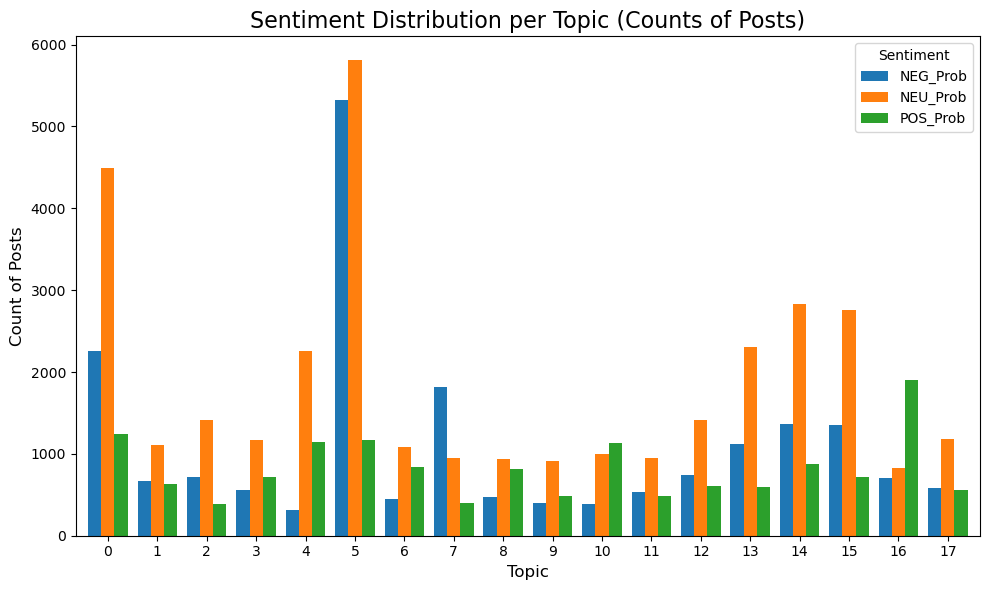

In [68]:
analyzer = create_analyzer(task="sentiment", lang="en")
# Modify the get_sentiment function to return the probabilities correctly
def get_sentiment_probability(text):
    sentiment_result = analyzer.predict(text)
    # Extract the probabilities directly from the 'probas' attribute
    return sentiment_result.probas  # This contains the probabilities for each sentiment

# Apply sentiment analysis to each post and store probabilities
df_sampled['Sentiment_Probabilities'] = df_sampled['CleanedText'].apply(get_sentiment_probability)

# You may want to expand this to separate columns for each sentiment
df_sampled[['POS_Prob', 'NEU_Prob', 'NEG_Prob']] = pd.DataFrame(df_sampled['Sentiment_Probabilities'].tolist(), index=df_sampled.index)

# Assign sentiment labels based on maximum probability
df_sampled['Sentiment_Label'] = df_sampled[['POS_Prob', 'NEU_Prob', 'NEG_Prob']].idxmax(axis=1)

# Group by Topic and Sentiment Label, then count the number of posts for each combination
sentiment_count = df_sampled.groupby(['Topic', 'Sentiment_Label']).size().unstack(fill_value=0)

# Visualize the sentiment counts per topic
sentiment_count.plot(kind='bar', stacked=False, width=0.8, figsize=(10, 6))

# Add title and labels to the plot
plt.title('Sentiment Distribution per Topic (Counts of Posts)', fontsize=16)
plt.xlabel('Topic', fontsize=12)
plt.ylabel('Count of Posts', fontsize=12)
plt.xticks(rotation=0)
plt.legend(title="Sentiment", fontsize=10)

# Show the plot
plt.tight_layout()
plt.show()

/opt/anaconda3/lib/python3.12/site-packages/pandas/core/algorithms.py:522: DeprecationWarning: np.find_common_type is deprecated.  Please use `np.result_type` or `np.promote_types`.
See https://numpy.org/devdocs/release/1.25.0-notes.html and the docs for more information.  (Deprecated NumPy 1.25)
  common = np.find_common_type([values.dtype, comps_array.dtype], [])


<Figure size 1000x600 with 0 Axes>

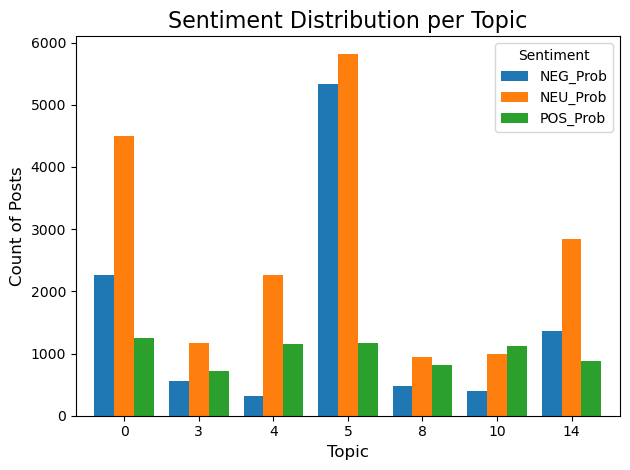

In [70]:
# 1) Create the sentiment analyzer
analyzer = create_analyzer(task="sentiment", lang="en")

# 2) Helper to extract the probability vector
def get_sentiment_probability(text):
    sentiment_result = analyzer.predict(text)
    return sentiment_result.probas

# 3) Compute probabilities for each post
df_sampled['Sentiment_Probabilities'] = df_sampled['CleanedText'].apply(get_sentiment_probability)

# 4) Expand into separate columns
df_sampled[['POS_Prob', 'NEU_Prob', 'NEG_Prob']] = pd.DataFrame(
    df_sampled['Sentiment_Probabilities'].tolist(),
    index=df_sampled.index
)

# 5) Assign the winning label
df_sampled['Sentiment_Label'] = df_sampled[['POS_Prob','NEU_Prob','NEG_Prob']].idxmax(axis=1)

# 6) Now filter to only the topics of interest
valid_topics = [0, 3, 4, 5, 8, 10, 14]
df_filtered = df_sampled[df_sampled['Topic'].isin(valid_topics)]

# 7) Group by Topic + Sentiment and count
sentiment_count = (
    df_filtered
      .groupby(['Topic','Sentiment_Label'])
      .size()
      .unstack(fill_value=0)
      .loc[valid_topics]   # ensures the bars show in numerical topic order
)

# 8) Plot
plt.figure(figsize=(10,6))
sentiment_count.plot(kind='bar', stacked=False, width=0.8)
plt.title('Sentiment Distribution per Topic', fontsize=16)
plt.xlabel('Topic', fontsize=12)
plt.ylabel('Count of Posts', fontsize=12)
plt.xticks(rotation=0)
plt.legend(title='Sentiment', fontsize=10)
plt.tight_layout()
plt.show()


/opt/anaconda3/lib/python3.12/site-packages/IPython/core/pylabtools.py:77: DeprecationWarning: backend2gui is deprecated since IPython 8.24, backends are managed in matplotlib and can be externally registered.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/IPython/core/pylabtools.py:77: DeprecationWarning: backend2gui is deprecated since IPython 8.24, backends are managed in matplotlib and can be externally registered.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/IPython/core/pylabtools.py:77: DeprecationWarning: backend2gui is deprecated since IPython 8.24, backends are managed in matplotlib and can be externally registered.
  warnings.warn(


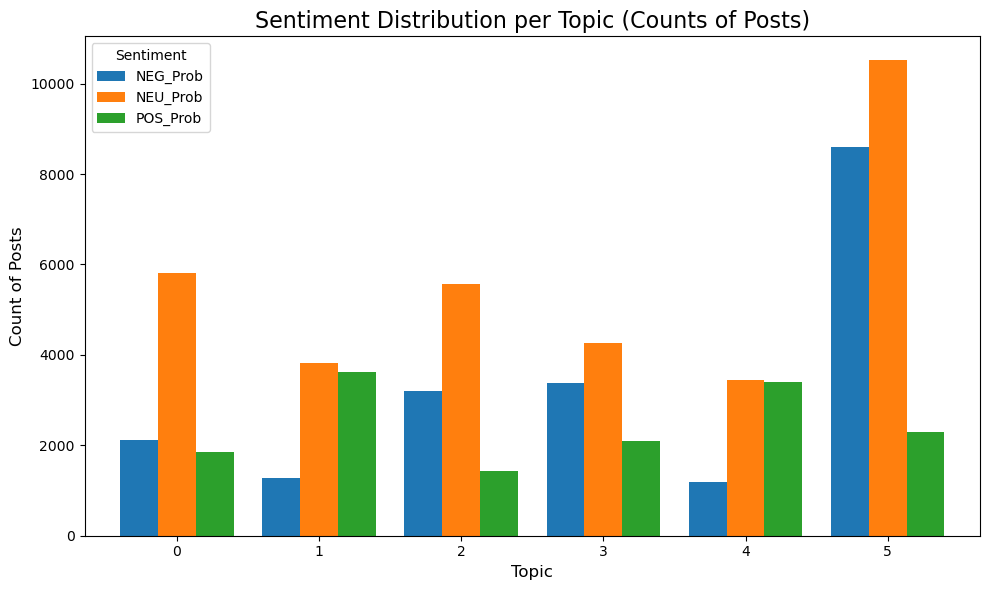

In [72]:
# analyzer = create_analyzer(task="sentiment", lang="en")
# # Modify the get_sentiment function to return the probabilities correctly
# def get_sentiment_probability(text):
#     sentiment_result = analyzer.predict(text)
#     # Extract the probabilities directly from the 'probas' attribute
#     return sentiment_result.probas  # This contains the probabilities for each sentiment

# # Apply sentiment analysis to each post and store probabilities
# df_sampled['Sentiment_Probabilities'] = df_sampled['CleanedText'].apply(get_sentiment_probability)

# # You may want to expand this to separate columns for each sentiment
# df_sampled[['POS_Prob', 'NEU_Prob', 'NEG_Prob']] = pd.DataFrame(df_sampled['Sentiment_Probabilities'].tolist(), index=df_sampled.index)

# # Assign sentiment labels based on maximum probability
# df_sampled['Sentiment_Label'] = df_sampled[['POS_Prob', 'NEU_Prob', 'NEG_Prob']].idxmax(axis=1)

# # Group by Topic and Sentiment Label, then count the number of posts for each combination
# sentiment_count = df_sampled.groupby(['Topic', 'Sentiment_Label']).size().unstack(fill_value=0)

# # Visualize the sentiment counts per topic
# sentiment_count.plot(kind='bar', stacked=False, width=0.8, figsize=(10, 6))

# # Add title and labels to the plot
# plt.title('Sentiment Distribution per Topic (Counts of Posts)', fontsize=16)
# plt.xlabel('Topic', fontsize=12)
# plt.ylabel('Count of Posts', fontsize=12)
# plt.xticks(rotation=0)
# plt.legend(title="Sentiment", fontsize=10)

# # Show the plot
# plt.tight_layout()
# plt.show()

In [84]:
print(df_sampled.columns)

Index(['Post_Index', 'Topic', 'Confidence', 'CleanedText',
       'Sentiment_Probabilities', 'POS_Prob', 'NEU_Prob', 'NEG_Prob',
       'Sentiment_Label', 'Date', 'Sentiment'],
      dtype='object')


In [86]:
# Print the columns in reddit to check for 'Post_Index'
print(reddit.columns)

Index(['subreddit_id', 'approved_at_utc', 'author_is_blocked', 'comment_type',
       'edited', 'mod_reason_by', 'banned_by', 'ups', 'num_reports',
       'author_flair_type', 'total_awards_received', 'subreddit',
       'author_flair_template_id', 'likes', 'replies', 'user_reports', 'saved',
       'id', 'banned_at_utc', 'mod_reason_title', 'gilded', 'archived',
       'collapsed_reason_code', 'no_follow', 'author', 'can_mod_post',
       'send_replies', 'parent_id', 'score', 'author_fullname',
       'report_reasons', 'removal_reason', 'approved_by', 'all_awardings',
       'body', 'awarders', 'top_awarded_type', 'downs',
       'author_flair_css_class', 'author_patreon_flair', 'collapsed',
       'author_flair_richtext', 'is_submitter', 'body_html', 'gildings',
       'collapsed_reason', 'associated_award', 'stickied', 'author_premium',
       'can_gild', 'link_id', 'unrepliable_reason', 'author_flair_text_color',
       'score_hidden', 'permalink', 'subreddit_type', 'locked', 'name

In [88]:
print(df_sampled.columns)

Index(['Post_Index', 'Topic', 'Confidence', 'CleanedText',
       'Sentiment_Probabilities', 'POS_Prob', 'NEU_Prob', 'NEG_Prob',
       'Sentiment_Label', 'Date', 'Sentiment'],
      dtype='object')


In [90]:
# Convert 'id' in reddit to int64, handling errors if any
reddit['id'] = pd.to_numeric(reddit['id'], errors='coerce')

# Check again to confirm data types
print(df_sampled['Post_Index'].dtype)  # Should be int64
print(reddit['id'].dtype)  # Should now be int64

object
float64


In [94]:
print("Sample Post_Index values from df_sampled:")
print(df_sampled['Post_Index'].head(10))

print("Sample id values from reddit:")
print(reddit['id'].head(10))

Sample Post_Index values from df_sampled:
0    0
1    1
2    2
3    3
4    4
5    5
6    6
7    7
8    8
9    9
Name: Post_Index, dtype: object
Sample id values from reddit:
0    nan
1    nan
2    nan
3    nan
4    nan
5    nan
6    nan
7    nan
8    nan
9    nan
Name: id, dtype: object


In [162]:
import pandas as pd
import scipy.stats as stats

# Create contingency table: counts of sentiment per topic
contingency_table = pd.crosstab(df_sampled['Topic'], df_sampled['Sentiment_Label'])

# Display the table
print(contingency_table)

Sentiment_Label  NEG_Prob  NEU_Prob  POS_Prob
Topic                                        
0                    2255      4490      1243
1                     671      1106       627
2                     721      1410       392
3                     556      1164       717
4                     316      2255      1147
5                    5328      5810      1165
6                     452      1079       843
7                    1818       944       401
8                     471       938       809
9                     403       909       488
10                    390      1000      1127
11                    528       954       488
12                    745      1414       610
13                   1115      2302       594
14                   1362      2836       877
15                   1358      2762       715
16                    704       830      1907
17                    580      1187       562


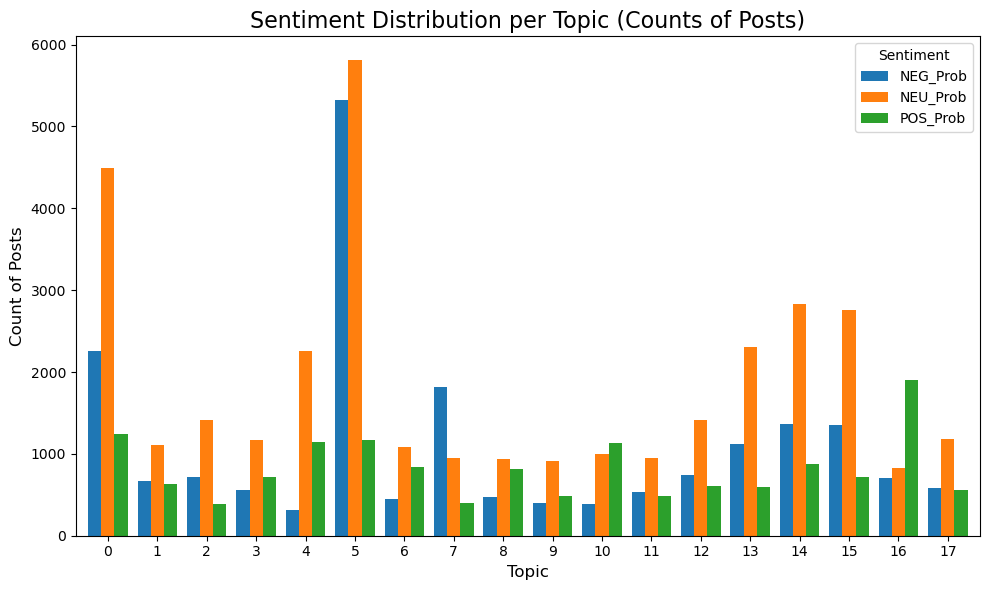

In [96]:
 analyzer = create_analyzer(task="sentiment", lang="en")
# # Modify the get_sentiment function to return the probabilities correctly
 def get_sentiment_probability(text):
     sentiment_result = analyzer.predict(text)
     # Extract the probabilities directly from the 'probas' attribute
     return sentiment_result.probas  # This contains the probabilities for each sentiment

# # Apply sentiment analysis to each post and store probabilities
 df_sampled['Sentiment_Probabilities'] = df_sampled['CleanedText'].apply(get_sentiment_probability)

# # You may want to expand this to separate columns for each sentiment
 df_sampled[['POS_Prob', 'NEU_Prob', 'NEG_Prob']] = pd.DataFrame(df_sampled['Sentiment_Probabilities'].tolist(), index=df_sampled.index)

# # Assign sentiment labels based on maximum probability
 df_sampled['Sentiment_Label'] = df_sampled[['POS_Prob', 'NEU_Prob', 'NEG_Prob']].idxmax(axis=1)

# # Group by Topic and Sentiment Label, then count the number of posts for each combination
 sentiment_count = df_sampled.groupby(['Topic', 'Sentiment_Label']).size().unstack(fill_value=0)

# # Visualize the sentiment counts per topic
 sentiment_count.plot(kind='bar', stacked=False, width=0.8, figsize=(10, 6))

# # Add title and labels to the plot
 plt.title('Sentiment Distribution per Topic (Counts of Posts)', fontsize=16)
 plt.xlabel('Topic', fontsize=12)
 plt.ylabel('Count of Posts', fontsize=12)
 plt.xticks(rotation=0)
 plt.legend(title="Sentiment", fontsize=10)

# # Show the plot
 plt.tight_layout()
 plt.show()

/opt/anaconda3/lib/python3.12/site-packages/pandas/core/algorithms.py:522: DeprecationWarning: np.find_common_type is deprecated.  Please use `np.result_type` or `np.promote_types`.
See https://numpy.org/devdocs/release/1.25.0-notes.html and the docs for more information.  (Deprecated NumPy 1.25)
  common = np.find_common_type([values.dtype, comps_array.dtype], [])


<Figure size 1000x600 with 0 Axes>

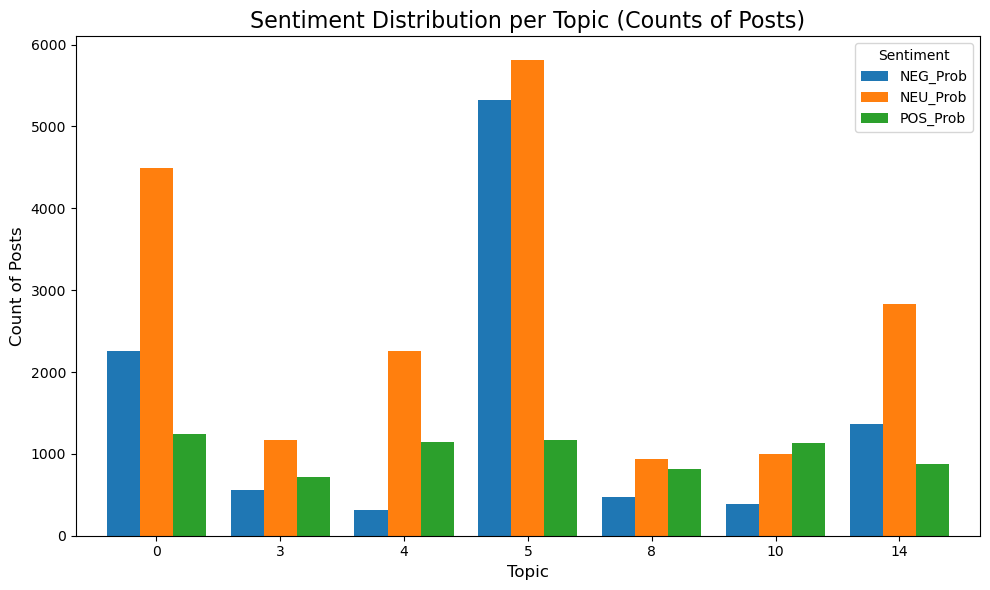

In [98]:
# Step 1: Import required libraries
import pandas as pd
import matplotlib.pyplot as plt
from pysentimiento import create_analyzer

# Step 2: Initialize the sentiment analyzer
analyzer = create_analyzer(task="sentiment", lang="en")

# Step 3: Define a function to extract sentiment probabilities
def get_sentiment_probability(text):
    sentiment_result = analyzer.predict(text)
    return sentiment_result.probas  # returns a dictionary with 'pos', 'neu', 'neg' probabilities

# Step 4: Apply sentiment analysis to each post and store probabilities
df_sampled['Sentiment_Probabilities'] = df_sampled['CleanedText'].apply(get_sentiment_probability)

# Step 5: Expand the sentiment probabilities into separate columns
df_sampled[['POS_Prob', 'NEU_Prob', 'NEG_Prob']] = pd.DataFrame(
    df_sampled['Sentiment_Probabilities'].tolist(),
    index=df_sampled.index
)

# Step 6: Assign sentiment labels based on the maximum probability
df_sampled['Sentiment_Label'] = df_sampled[['POS_Prob', 'NEU_Prob', 'NEG_Prob']].idxmax(axis=1)

# Step 7: Filter to only selected topics of interest
valid_topics = [0, 3, 4, 5, 8, 10, 14]
df_filtered = df_sampled[df_sampled['Topic'].isin(valid_topics)]

# Step 8: Group by Topic and Sentiment_Label, count occurrences
sentiment_count = (
    df_filtered
    .groupby(['Topic', 'Sentiment_Label'])
    .size()
    .unstack(fill_value=0)
    .loc[valid_topics]  # ensures topics are ordered as specified
)

# Step 9: Plot the sentiment distribution
plt.figure(figsize=(10, 6))
sentiment_count.plot(kind='bar', stacked=False, width=0.8, figsize=(10, 6))
plt.title('Sentiment Distribution per Topic (Counts of Posts)', fontsize=16)
plt.xlabel('Topic', fontsize=12)
plt.ylabel('Count of Posts', fontsize=12)
plt.xticks(rotation=0)
plt.legend(title="Sentiment", fontsize=10)
plt.tight_layout()
plt.show()


In [102]:
import pandas as pd
import scipy.stats as stats

# Create contingency table: counts of sentiment per topic (only for selected topics)
contingency_table = pd.crosstab(df_filtered['Topic'], df_filtered['Sentiment_Label'])

# Display the contingency table
print("Contingency Table (Topic vs. Sentiment):")
print(contingency_table)

Contingency Table (Topic vs. Sentiment):
Sentiment_Label  NEG_Prob  NEU_Prob  POS_Prob
Topic                                        
0                    2255      4490      1243
3                     556      1164       717
4                     316      2255      1147
5                    5328      5810      1165
8                     471       938       809
10                    390      1000      1127
14                   1362      2836       877


In [104]:
import pandas as pd
from scipy.stats import chi2_contingency

# Construct the contingency table using only topics of interest
contingency_data = pd.DataFrame({
    'NEG_Prob': [2255, 556, 316, 5328, 471, 390, 1362],
    'NEU_Prob': [4490, 1164, 2255, 5810, 938, 1000, 2836],
    'POS_Prob': [1243, 717, 1147, 1165, 809, 1127, 877]
}, index=[0, 3, 4, 5, 8, 10, 14])  # topic numbers as index

# Perform chi-squared test
chi2, p, dof, expected = chi2_contingency(contingency_data)

# Output the results
print("Chi-square statistic:", chi2)
print("Degrees of freedom:", dof)
print("P-value:", p)

Chi-square statistic: 4122.204433752313
Degrees of freedom: 12
P-value: 0.0


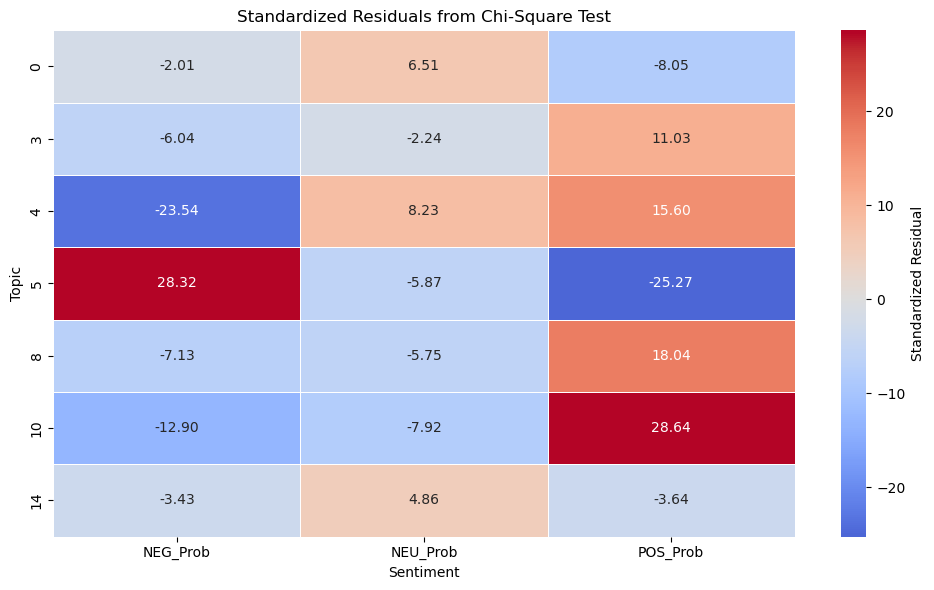

In [106]:
import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency
import seaborn as sns
import matplotlib.pyplot as plt

# Re-create the contingency table using your selected topics
contingency_table = pd.DataFrame({
    'NEG_Prob': [2255, 556, 316, 5328, 471, 390, 1362],
    'NEU_Prob': [4490, 1164, 2255, 5810, 938, 1000, 2836],
    'POS_Prob': [1243, 717, 1147, 1165, 809, 1127, 877]
}, index=[0, 3, 4, 5, 8, 10, 14])  # These are your valid topics

# Step 1: Perform chi-square test to get expected frequencies
chi2, p, dof, expected = chi2_contingency(contingency_table)

# Step 2: Compute standardized residuals
observed = contingency_table.values
std_residuals = (observed - expected) / np.sqrt(expected)

# Step 3: Convert to DataFrame
residuals_df = pd.DataFrame(std_residuals, index=contingency_table.index, columns=contingency_table.columns)

# Step 4: Visualize with heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(residuals_df, annot=True, fmt=".2f", center=0, cmap="coolwarm", linewidths=0.5, cbar_kws={'label': 'Standardized Residual'})
plt.title("Standardized Residuals from Chi-Square Test")
plt.xlabel("Sentiment")
plt.ylabel("Topic")
plt.tight_layout()
plt.show()


In [114]:
!pip install pymannkendall

/opt/anaconda3/lib/python3.12/pty.py:95: DeprecationWarning: This process (pid=50128) is multi-threaded, use of forkpty() may lead to deadlocks in the child.
  pid, fd = os.forkpty()


In [118]:
print(reddit.columns)

Index(['subreddit_id', 'approved_at_utc', 'author_is_blocked', 'comment_type',
       'edited', 'mod_reason_by', 'banned_by', 'ups', 'num_reports',
       'author_flair_type', 'total_awards_received', 'subreddit',
       'author_flair_template_id', 'likes', 'replies', 'user_reports', 'saved',
       'id', 'banned_at_utc', 'mod_reason_title', 'gilded', 'archived',
       'collapsed_reason_code', 'no_follow', 'author', 'can_mod_post',
       'send_replies', 'parent_id', 'score', 'author_fullname',
       'report_reasons', 'removal_reason', 'approved_by', 'all_awardings',
       'body', 'awarders', 'top_awarded_type', 'downs',
       'author_flair_css_class', 'author_patreon_flair', 'collapsed',
       'author_flair_richtext', 'is_submitter', 'body_html', 'gildings',
       'collapsed_reason', 'associated_award', 'stickied', 'author_premium',
       'can_gild', 'link_id', 'unrepliable_reason', 'author_flair_text_color',
       'score_hidden', 'permalink', 'subreddit_type', 'locked', 'name

<Figure size 1000x400 with 0 Axes>

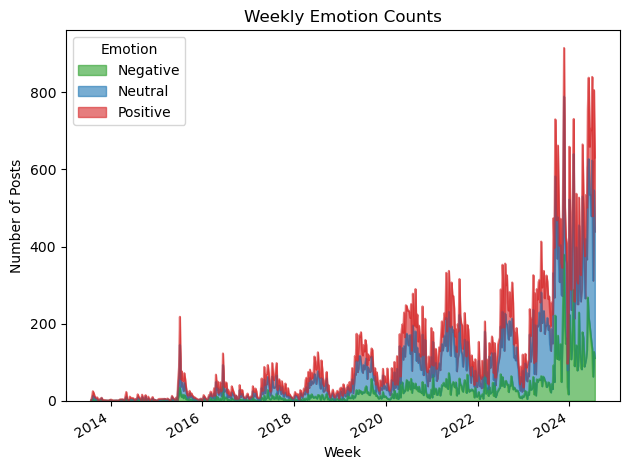

<Figure size 1000x400 with 0 Axes>

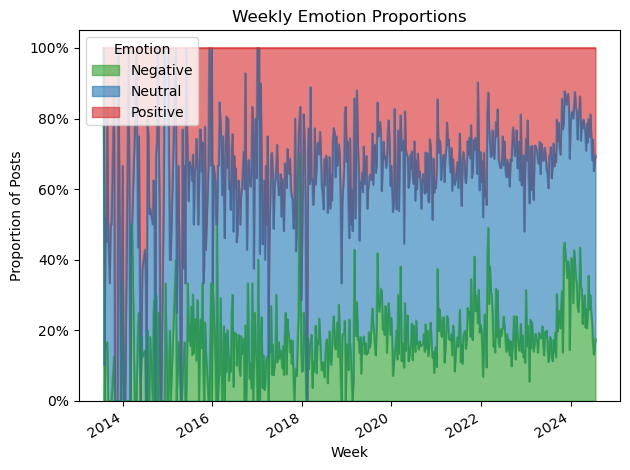

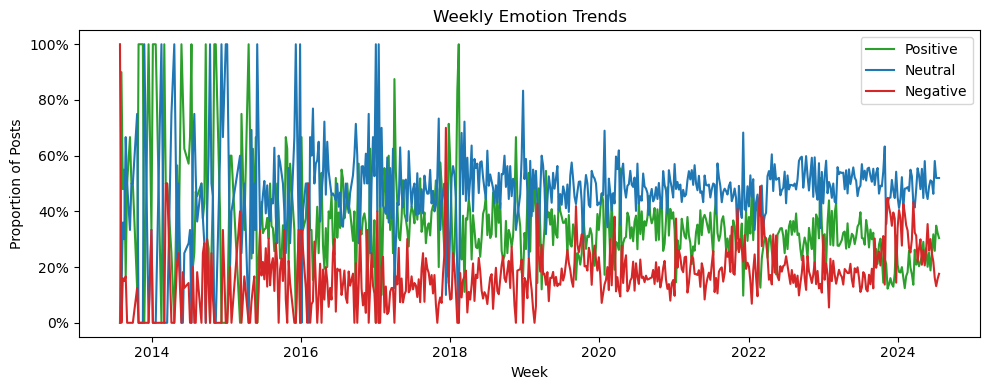


Mann–Kendall Trend Tests for Weekly Sentiment Proportions
----------------------------------------------------------

Positive Sentiment:
  Trend: decreasing
  p-value: 0.0000
  Tau: -0.2439
  Variance: 17155222.67
  H (significant at α=0.05): Yes

Neutral Sentiment:
  Trend: increasing
  p-value: 0.0007
  Tau: 0.0982
  Variance: 17152933.67
  H (significant at α=0.05): Yes

Negative Sentiment:
  Trend: increasing
  p-value: 0.0000
  Tau: 0.2820
  Variance: 17133768.33
  H (significant at α=0.05): Yes


In [122]:
import pandas as pd
import matplotlib.pyplot as plt
import pymannkendall as mk

# ─── PREP: Ensure you have Date + Broad_Emotion ───────────────────────────────
reddit['Date'] = pd.to_datetime(reddit['Date'])

# Create Broad_Emotion based on max of sentiment probabilities
reddit['Broad_Emotion'] = reddit[['Positive', 'Neutral', 'Negative']].idxmax(axis=1)

# ─── BUCKET INTO WEEKS ────────────────────────────────────────────────────────
reddit['Week'] = reddit['Date'].dt.to_period('W').dt.start_time

# ─── AGGREGATE COUNTS BY WEEK × EMOTION ───────────────────────────────────────
weekly_counts = (
    reddit
    .groupby(['Week', 'Broad_Emotion'])
    .size()
    .unstack(fill_value=0)
    .sort_index()
)

# ─── PROPORTIONS PER WEEK ─────────────────────────────────────────────────────
weekly_props = weekly_counts.div(weekly_counts.sum(axis=1), axis=0)

# ─── 1) PLOT RAW COUNTS AS STACKED AREA ───────────────────────────────────────
plt.figure(figsize=(10, 4))
weekly_counts.plot.area(
    color=['tab:green', 'tab:blue', 'tab:red'],
    alpha=0.6
)
plt.title("Weekly Emotion Counts")
plt.ylabel("Number of Posts")
plt.xlabel("Week")
plt.legend(title="Emotion")
plt.tight_layout()
plt.show()

# ─── 2) PLOT PROPORTIONS AS STACKED AREA ──────────────────────────────────────
plt.figure(figsize=(10, 4))
weekly_props.plot.area(
    color=['tab:green', 'tab:blue', 'tab:red'],
    alpha=0.6
)
plt.title("Weekly Emotion Proportions")
plt.ylabel("Proportion of Posts")
plt.xlabel("Week")
plt.gca().yaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
plt.legend(title="Emotion", loc='upper left')
plt.tight_layout()
plt.show()

# ─── 3) LINE PLOT FOR EACH EMOTION ────────────────────────────────────────────
plt.figure(figsize=(10, 4))
for emo, col in zip(['Positive', 'Neutral', 'Negative'],
                    ['tab:green', 'tab:blue', 'tab:red']):
    plt.plot(weekly_props.index, weekly_props[emo], label=emo, color=col)
plt.title("Weekly Emotion Trends")
plt.ylabel("Proportion of Posts")
plt.xlabel("Week")
plt.gca().yaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
plt.legend()
plt.tight_layout()
plt.show()

# ─── 4) MANN–KENDALL TREND TESTS (Robust Version) ─────────────────────────────
print("\nMann–Kendall Trend Tests for Weekly Sentiment Proportions")
print("----------------------------------------------------------")
for emotion in ['Positive', 'Neutral', 'Negative']:
    series = weekly_props[emotion]
    result = mk.original_test(series)
    print(f"\n{emotion} Sentiment:")
    print(f"  Trend: {result.trend}")
    print(f"  p-value: {result.p:.4f}")
    print(f"  Tau: {result.Tau:.4f}")
    # Check and print S and var_s if available
    if hasattr(result, 'S'):
        print(f"  S: {result.S}")
    if hasattr(result, 'var_s'):
        print(f"  Variance: {result.var_s:.2f}")
    print(f"  H (significant at α=0.05): {'Yes' if result.h else 'No'}")


In [166]:
# 1) build the full 18-row DataFrame
full = pd.DataFrame({
    'NEG_Prob': [2255, 671, 721, 556, 316, 5328, 452, 1818, 471, 403, 390, 528, 745, 1115, 1362, 1358, 704, 580],
    'NEU_Prob': [4490, 1106, 1410, 1164, 2255, 5810, 1079,  944,  938, 909, 1000,  954, 1414, 2302, 2836, 2762,  830, 1187],
    'POS_Prob': [1243,  627,  392,  717, 1147, 1165,  843,  401,  809, 488, 1127,  488,  610,  594,  877,  715, 1907,  562]
})

# 2) then subset to only the rows whose index is in your list:
keep = [1, 3, 4, 8, 9, 10, 11]
contingency = full.loc[keep]

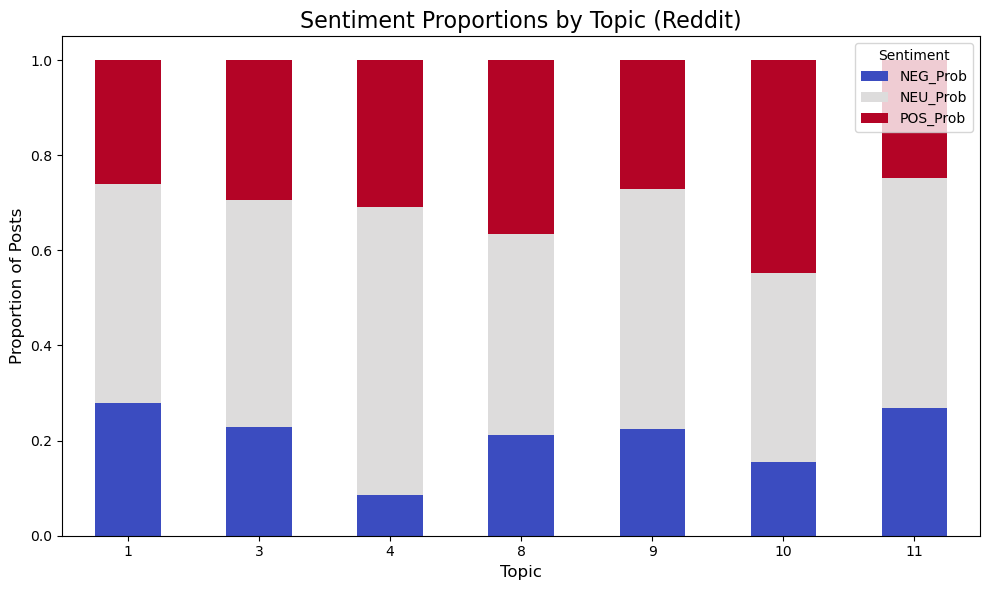

In [168]:
# Convert counts to proportions per topic
proportions = contingency.div(contingency.sum(axis=1), axis=0)

# Plot
proportions.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='coolwarm')

plt.title('Sentiment Proportions by Topic (Reddit)', fontsize=16)
plt.xlabel('Topic', fontsize=12)
plt.ylabel('Proportion of Posts', fontsize=12)
plt.xticks(rotation=0)
plt.legend(title='Sentiment')
plt.tight_layout()
plt.show()


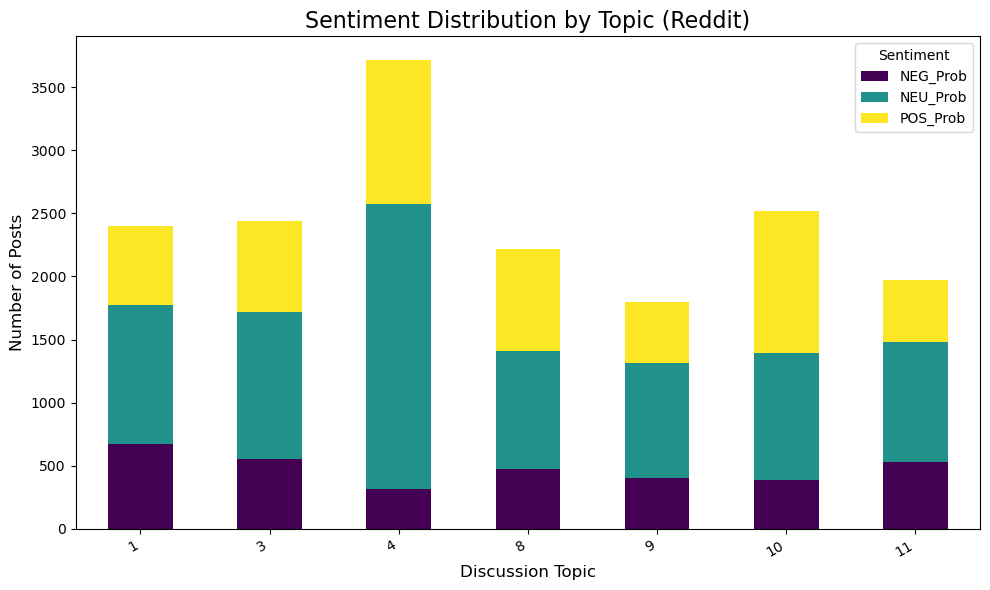

In [170]:
contingency.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='viridis')

plt.title('Sentiment Distribution by Topic (Reddit)', fontsize=16)
plt.xlabel('Discussion Topic', fontsize=12)
plt.ylabel('Number of Posts', fontsize=12)
plt.xticks(rotation=30, ha='right')
plt.legend(title='Sentiment')
plt.tight_layout()
plt.show()

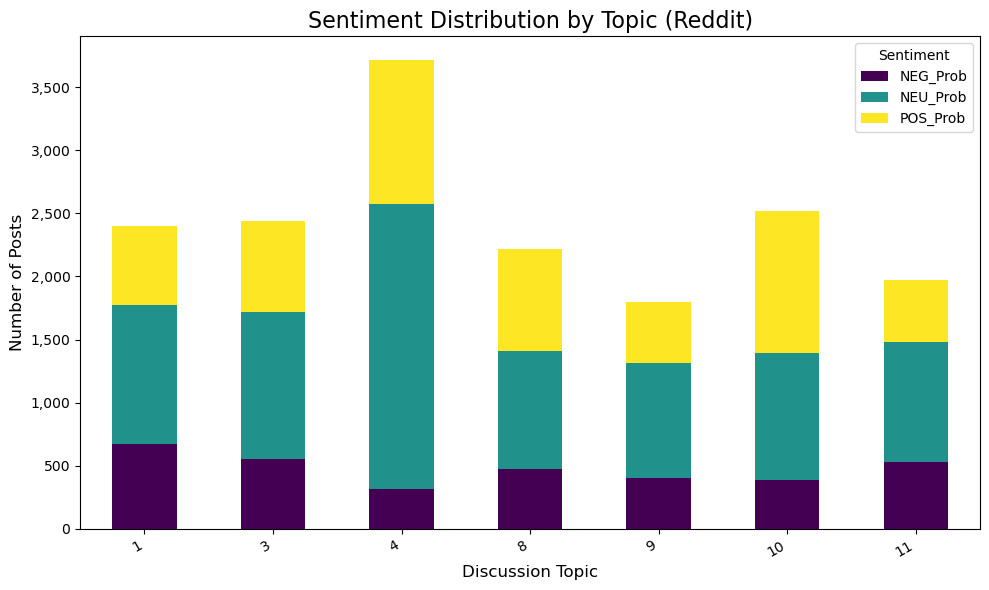

In [172]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Plot
ax = contingency.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='viridis')

# Format y-axis ticks
formatter = FuncFormatter(lambda x, _: f'{int(x):,}')
ax.yaxis.set_major_formatter(formatter)

plt.title('Sentiment Distribution by Topic (Reddit)', fontsize=16)
plt.xlabel('Discussion Topic', fontsize=12)
plt.ylabel('Number of Posts', fontsize=12)
plt.xticks(rotation=30, ha='right')
plt.legend(title='Sentiment')
plt.tight_layout()
plt.show()

/opt/anaconda3/lib/python3.12/site-packages/pandas/core/algorithms.py:522: DeprecationWarning: np.find_common_type is deprecated.  Please use `np.result_type` or `np.promote_types`.
See https://numpy.org/devdocs/release/1.25.0-notes.html and the docs for more information.  (Deprecated NumPy 1.25)
  common = np.find_common_type([values.dtype, comps_array.dtype], [])


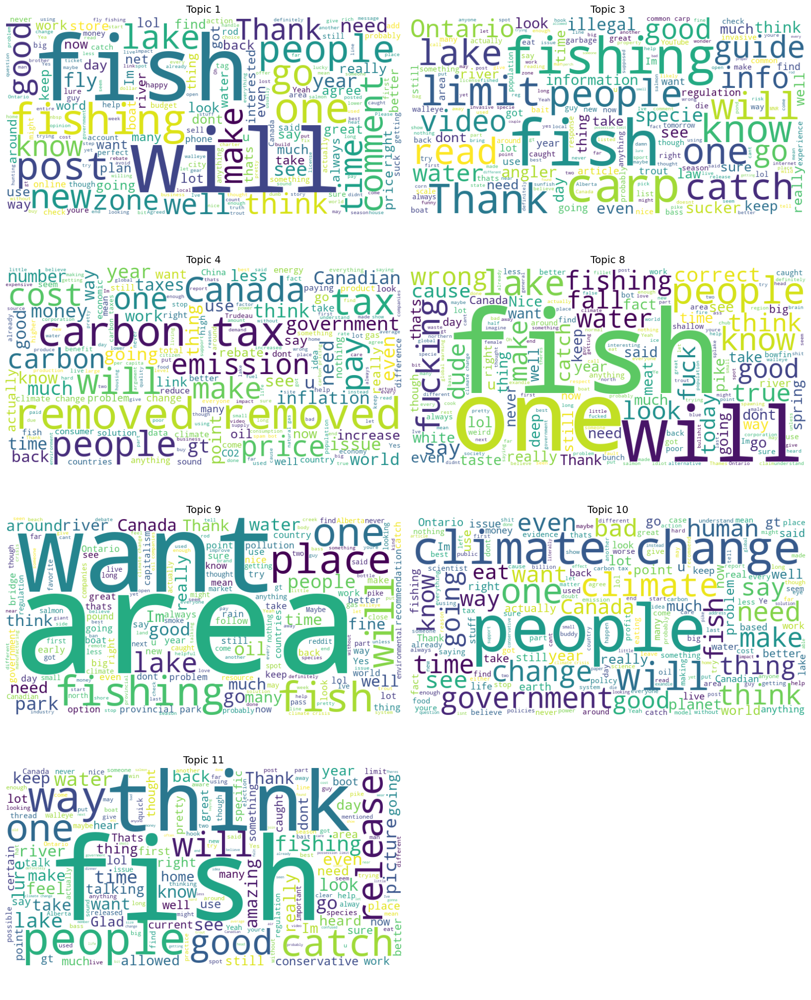

In [180]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Your topics of interest
valid_topics = [1, 3, 4, 8, 9, 10, 11]
df_filtered = df_sampled[df_sampled['Topic'].isin(valid_topics)]

# Grid layout: 2 columns
cols = 2
rows = (len(valid_topics) + cols - 1) // cols

# Make the overall figure wider:
fig, axes = plt.subplots(rows, cols, figsize=(cols * 8, rows * 5))

for idx, topic in enumerate(valid_topics):
    ax = axes.flat[idx]
    corpus = " ".join(df_filtered.loc[df_filtered['Topic']==topic, 'CleanedText'])
    # Increase the cloud's width & height
    wc = WordCloud(
        width=800,     # double from 400
        height=400,    # up from 300
        background_color='white'
    ).generate(corpus)
    ax.imshow(wc, interpolation='bilinear')
    ax.set_title(f"Topic {topic}", fontsize=14)
    ax.axis('off')

# Turn off any unused subplots
for idx in range(len(valid_topics), rows * cols):
    axes.flat[idx].axis('off')

plt.tight_layout()
plt.show()

In [140]:
# # Filter to only Topic 4
# topic4_df = df_sampled[df_sampled['Topic'] == 4]

# # Sort by Negative sentiment probability
# top_neg_posts = topic4_df.sort_values(by='NEG_Prob', ascending=False).head(20)

# # Display the top 20 posts
# for i, row in top_neg_posts.iterrows():
#     print(f"Post {i+1}:\n{row['CleanedText']}\nSentiment Probabilities: NEG={row['NEG_Prob']:.3f}, NEU={row['NEU_Prob']:.3f}, POS={row['POS_Prob']:.3f}\n{'-'*80}")

Post 3293871:
Awesome! The lake is awesome and has plenty of deep reef action. Thanks.
Sentiment Probabilities: NEG=0.993, NEU=0.005, POS=0.002
--------------------------------------------------------------------------------
Post 1424270:
You got me extra excited! Thank you for the tips and encouragement!
Sentiment Probabilities: NEG=0.993, NEU=0.005, POS=0.002
--------------------------------------------------------------------------------
Post 3497013:
I'm also super excited for this subreddit! Shout out to all you anglers in , r, hamilton!
Sentiment Probabilities: NEG=0.993, NEU=0.005, POS=0.002
--------------------------------------------------------------------------------
Post 1216643:
Perfect! Thanks for the tip! Happy Fishing!
Sentiment Probabilities: NEG=0.993, NEU=0.005, POS=0.002
--------------------------------------------------------------------------------
Post 1732519:
Always an awesome day when one graces us with its presence.
Sentiment Probabilities: NEG=0.993, NEU=0.0

/opt/anaconda3/lib/python3.12/site-packages/pandas/core/dtypes/cast.py:1641: DeprecationWarning: np.find_common_type is deprecated.  Please use `np.result_type` or `np.promote_types`.
See https://numpy.org/devdocs/release/1.25.0-notes.html and the docs for more information.  (Deprecated NumPy 1.25)
  return np.find_common_type(types, [])


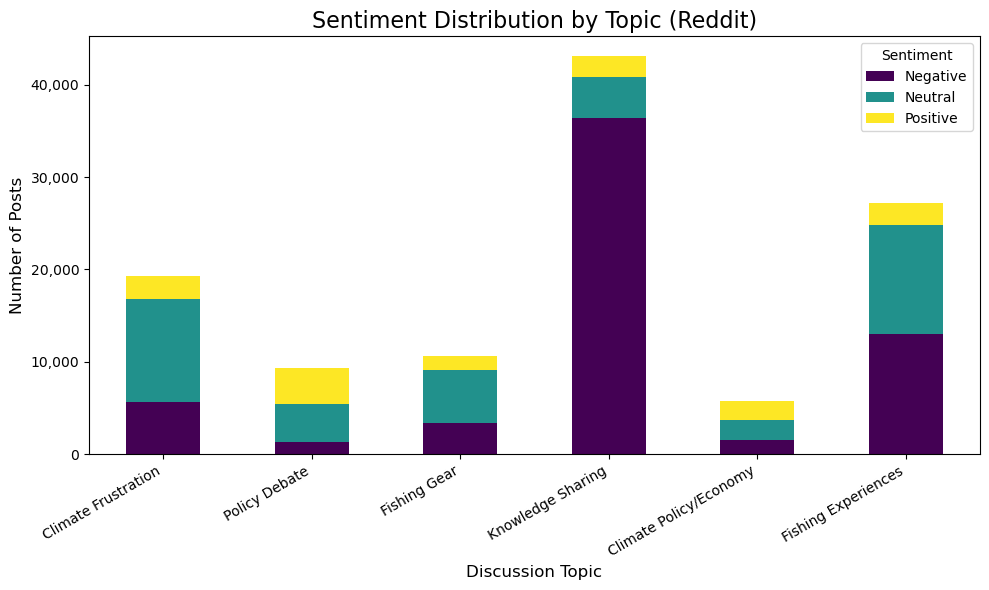

In [148]:
# import matplotlib.pyplot as plt
# from matplotlib.ticker import FuncFormatter

# # Step 1: Remove 'deleted' and 'removed' posts from Topic 4
# cleaned_df = df_sampled[
#     ~((df_sampled['Topic'] == 4) & df_sampled['CleanedText'].str.contains("deleted|removed", case=False, na=False))
# ]

# # Step 2: Recompute the contingency table using the cleaned dataset
# contingency_cleaned = pd.crosstab(cleaned_df['Topic'], cleaned_df['Sentiment_Label'])

# # Optional: Rename columns for readability
# contingency_cleaned = contingency_cleaned.rename(columns={
#     'NEG_Prob': 'Negative',
#     'NEU_Prob': 'Neutral',
#     'POS_Prob': 'Positive'
# })

# # Optional: Add topic labels again if needed
# topic_labels = {
#     0: 'Climate Frustration',
#     1: 'Policy Debate',
#     2: 'Fishing Gear',
#     3: 'Knowledge Sharing',
#     4: 'Climate Policy/Economy',
#     5: 'Fishing Experiences'
# }
# contingency_cleaned.index = contingency_cleaned.index.map(topic_labels)

# # Step 3: Plot
# ax = contingency_cleaned.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='viridis')

# # Format y-axis ticks with commas
# formatter = FuncFormatter(lambda x, _: f'{int(x):,}')
# ax.yaxis.set_major_formatter(formatter)

# plt.title('Sentiment Distribution by Topic (Reddit)', fontsize=16)
# plt.xlabel('Discussion Topic', fontsize=12)
# plt.ylabel('Number of Posts', fontsize=12)
# plt.xticks(rotation=30, ha='right')
# plt.legend(title='Sentiment')
# plt.tight_layout()
# plt.show()

In [182]:
print(reddit.columns.tolist())

['subreddit_id', 'approved_at_utc', 'author_is_blocked', 'comment_type', 'edited', 'mod_reason_by', 'banned_by', 'ups', 'num_reports', 'author_flair_type', 'total_awards_received', 'subreddit', 'author_flair_template_id', 'likes', 'replies', 'user_reports', 'saved', 'id', 'banned_at_utc', 'mod_reason_title', 'gilded', 'archived', 'collapsed_reason_code', 'no_follow', 'author', 'can_mod_post', 'send_replies', 'parent_id', 'score', 'author_fullname', 'report_reasons', 'removal_reason', 'approved_by', 'all_awardings', 'body', 'awarders', 'top_awarded_type', 'downs', 'author_flair_css_class', 'author_patreon_flair', 'collapsed', 'author_flair_richtext', 'is_submitter', 'body_html', 'gildings', 'collapsed_reason', 'associated_award', 'stickied', 'author_premium', 'can_gild', 'link_id', 'unrepliable_reason', 'author_flair_text_color', 'score_hidden', 'permalink', 'subreddit_type', 'locked', 'name', 'created', 'author_flair_text', 'treatment_tags', 'created_utc', 'subreddit_name_prefixed', 'c

In [184]:
# Step 1: Define the emotion columns
emotion_columns = ['Other', 'Anger', 'Disgust', 'Fear', 'Sadness', 'Joy', 'Surprise']

# Step 2: Assign dominant emotion
reddit['Dominant_Emotion'] = reddit[emotion_columns].idxmax(axis=1)

# Step 3: Preview the result
print(reddit['Dominant_Emotion'].value_counts())

Other       52239
Disgust      6711
Joy          6148
Anger        1004
Surprise      794
Fear          612
Sadness       367
Name: Dominant_Emotion, dtype: int64


In [186]:
print(reddit.columns.tolist())

['subreddit_id', 'approved_at_utc', 'author_is_blocked', 'comment_type', 'edited', 'mod_reason_by', 'banned_by', 'ups', 'num_reports', 'author_flair_type', 'total_awards_received', 'subreddit', 'author_flair_template_id', 'likes', 'replies', 'user_reports', 'saved', 'id', 'banned_at_utc', 'mod_reason_title', 'gilded', 'archived', 'collapsed_reason_code', 'no_follow', 'author', 'can_mod_post', 'send_replies', 'parent_id', 'score', 'author_fullname', 'report_reasons', 'removal_reason', 'approved_by', 'all_awardings', 'body', 'awarders', 'top_awarded_type', 'downs', 'author_flair_css_class', 'author_patreon_flair', 'collapsed', 'author_flair_richtext', 'is_submitter', 'body_html', 'gildings', 'collapsed_reason', 'associated_award', 'stickied', 'author_premium', 'can_gild', 'link_id', 'unrepliable_reason', 'author_flair_text_color', 'score_hidden', 'permalink', 'subreddit_type', 'locked', 'name', 'created', 'author_flair_text', 'treatment_tags', 'created_utc', 'subreddit_name_prefixed', 'c

In [188]:
import gensim
from gensim import corpora
from nltk.corpus import stopwords
import nltk
import re

nltk.download('stopwords')
stop_words = stopwords.words('english')

# Tokenization and cleaning
def preprocess(text):
    text = re.sub(r'[^\w\s]', '', str(text).lower())  # lowercase, remove punctuation
    return [word for word in text.split() if word not in stop_words]

# Apply preprocessing
reddit['tokens'] = reddit['CleanedText'].apply(preprocess)


[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/sheffdeen/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [200]:
# Create dictionary and corpus
dictionary = corpora.Dictionary(reddit['tokens'])
corpus = [dictionary.doc2bow(text) for text in reddit['tokens']]

In [202]:
from gensim.models.ldamodel import LdaModel

# Fit the model
lda_model = LdaModel(
    corpus=corpus,
    id2word=dictionary,
    num_topics=18,       # your total number of modeled topics
    random_state=42,
    passes=10
)

In [204]:
def get_dominant_topic(tokens):
    bow    = dictionary.doc2bow(tokens)
    topics = lda_model.get_document_topics(bow)
    # pick the topic with highest probability (or –1 if none)
    return max(topics, key=lambda x: x[1])[0] if topics else -1

reddit['Topic'] = reddit['tokens'].apply(get_dominant_topic)

# --- NEW: filter to only your topics of interest ---
valid_topics = [1, 3, 4, 8, 9, 10, 11]
df_selected  = reddit[reddit['Topic'].isin(valid_topics)].copy()

# now df_selected contains only posts whose assigned Topic ∈ valid_topics
print("Kept", len(df_selected), "posts out of", len(reddit))

/opt/anaconda3/lib/python3.12/site-packages/pandas/core/algorithms.py:522: DeprecationWarning: np.find_common_type is deprecated.  Please use `np.result_type` or `np.promote_types`.
See https://numpy.org/devdocs/release/1.25.0-notes.html and the docs for more information.  (Deprecated NumPy 1.25)
  common = np.find_common_type([values.dtype, comps_array.dtype], [])


Kept 19398 posts out of 67875


In [206]:
emotion_table_fb = pd.crosstab(reddit['Topic'], reddit['Dominant_Emotion'])

from scipy.stats import chi2_contingency
chi2, p, dof, expected = chi2_contingency(emotion_table_fb)

print("Chi-square:", chi2)
print("P-value:", p)

Chi-square: 12468.443736127583
P-value: 0.0


/opt/anaconda3/lib/python3.12/site-packages/pandas/core/algorithms.py:522: DeprecationWarning: np.find_common_type is deprecated.  Please use `np.result_type` or `np.promote_types`.
See https://numpy.org/devdocs/release/1.25.0-notes.html and the docs for more information.  (Deprecated NumPy 1.25)
  common = np.find_common_type([values.dtype, comps_array.dtype], [])


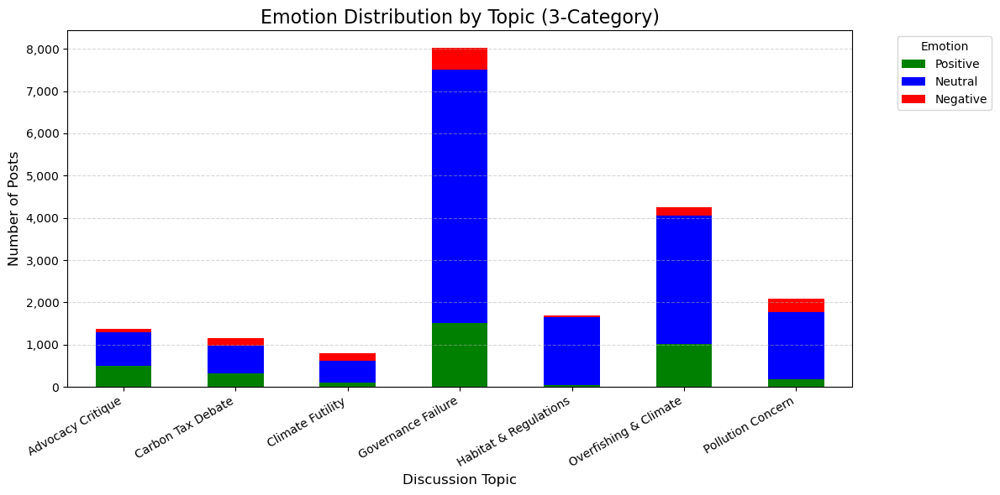

In [214]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import pandas as pd

# Step A: Define your broader emotion mapping
emotion_map = {
    'Joy':      'Positive',
    'Anger':    'Negative',
    'Disgust':  'Negative',
    'Fear':     'Negative',
    'Sadness':  'Negative',
    'Other':    'Neutral',
    'Surprise': 'Neutral'
}

# Step B: Filter to just the topics you care about
valid_topics = [1, 3, 4, 8, 9, 10, 11]
df_filtered = reddit[reddit['Topic'].isin(valid_topics)].copy()

# Step C: Map Dominant_Emotion → Broad_Emotion
df_filtered['Broad_Emotion'] = df_filtered['Dominant_Emotion'].map(emotion_map)

# Step D: Build the new emotion × topic table
emotion_table = pd.crosstab(
    df_filtered['Topic'].map({
        1:  'Overfishing & Climate',
        3:  'Habitat & Regulations',
        4:  'Climate Futility',
        8:  'Pollution Concern',
        9:  'Advocacy Critique',
        10: 'Governance Failure',
        11: 'Carbon Tax Debate',
    }),
    df_filtered['Broad_Emotion']
)[['Positive','Neutral','Negative']]   # ensure consistent column order

# Step E: Plot with custom bright colors
# Grab three bright hues from Matplotlib's Set1 palette:
#bright_colors = plt.get_cmap('Set1').colors[:3]

ax = emotion_table.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6),
    color=['green', 'blue', 'red']         # <<< here is where we override the palette
)

# Format the y-axis with commas
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{int(x):,}'))

plt.title('Emotion Distribution by Topic (3-Category)', fontsize=16)
plt.xlabel('Discussion Topic', fontsize=12)
plt.ylabel('Number of Posts', fontsize=12)
plt.xticks(rotation=30, ha='right')
plt.legend(title='Emotion', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

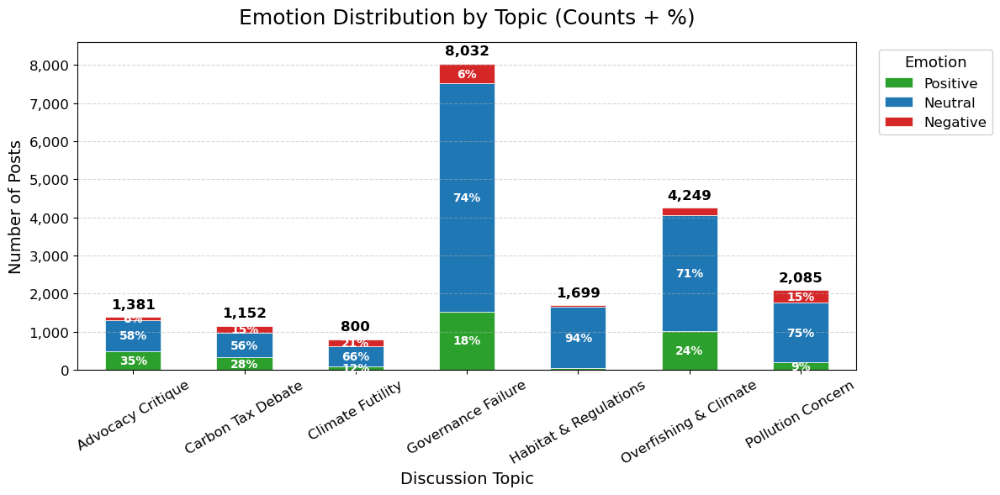

In [224]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import pandas as pd

# … assume emotion_table (counts) is already built as in your last cell …

# Compute row‐wise proportions (each segment’s % of its topic total)
emotion_frac = emotion_table.div(emotion_table.sum(axis=1), axis=0)

# Plot the counts
colors = {'Positive':'tab:green','Neutral':'tab:blue','Negative':'tab:red'}
ax = emotion_table.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6),
    color=[colors[c] for c in emotion_table.columns],
    edgecolor='white',
    linewidth=0.5
)

# Add total labels on top
totals = emotion_table.sum(axis=1)
max_total = totals.max()
ax.set_ylim(0, max_total * 1.07)
for idx, total in enumerate(totals):
    ax.text(
        idx, total + max_total*0.02,   # a little above the bar
        f"{total:,}",
        ha='center', va='bottom',
        fontsize=12, fontweight='bold'
    )

# Annotate each segment with its % (centered)
for i, topic in enumerate(emotion_table.index):
    cum = 0
    for col in emotion_table.columns:
        val = emotion_table.loc[topic, col]
        frac = emotion_frac.loc[topic, col]
        # position = bottom+ half of this segment
        y = cum + val/2
        if frac >= 0.05:  # only label if >=5% to avoid clutter
            ax.text(
                i, y,
                f"{int(frac*100)}%", 
                ha='center', va='center',
                color='white', fontsize=10, fontweight='semibold'
            )
        cum += val

# Tidy up
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{int(x):,}'))
ax.set_title('Emotion Distribution by Topic (Counts + %)', fontsize=18, pad=16)
ax.set_xlabel('Discussion Topic', fontsize=14)
ax.set_ylabel('Number of Posts', fontsize=14)
ax.tick_params(axis='x', labelrotation=30, labelsize=12)
ax.tick_params(axis='y', labelsize=12)
leg = ax.legend(title='Emotion', fontsize=12, title_fontsize=13,
                bbox_to_anchor=(1.02, 1), loc='upper left')
leg.get_frame().set_alpha(0.9)
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [238]:
import re
import pandas as pd

# ─── ASSUMPTION ────────────────────────────────────────────────────────────────
# You already have `reddit` with columns:
#   • Topic_Label    (e.g. 'Climate Futility', ...)
#   • Broad_Emotion  ('Positive', 'Neutral', 'Negative')
#   • CleanedText    (the cleaned post content)
#   • POS_Prob, NEU_Prob, NEG_Prob  (floating‐point confidences)

# ─── STEP A: how many examples per bucket? ──────────────────────────────────────
n_examples = 10

# ─── STEP B: which 4 topics to inspect? ───────────────────────────────────────
inspect_topics = [
    'Climate Futility',
    'Governance Failure',
    'Overfishing & Climate',
    'Pollution Concern',
]

# ─── STEP C: define a small list of “on‐topic” keywords for each ───────────────
# (Use your domain knowledge to refine these!)
topic_keywords = {
    'Climate Futility':      ['futility', 'won’t', 'can’t', 'nonsense', 'pointless', 'reset', '1995'],
    'Governance Failure':    ['government', 'MNR', 'authority', 'policy', 'enforcement', 'regulations'],
    'Overfishing & Climate': ['overfish', 'walleye', 'harvest', 'climate', 'carbon', 'footprint'],
    'Pollution Concern':     ['pollut', 'toxin', 'microplastics', 'ecosystem', 'Arctic', 'damage'],
}

# ─── STEP D: loop and spit out examples ────────────────────────────────────────
for topic in inspect_topics:
    print(f"\n{'='*12} TOPIC: {topic} {'='*12}\n")
    df_topic = reddit[reddit['Topic_Label'] == topic].reset_index(drop=True)
    if df_topic.empty:
        print("  (No posts for this topic)\n")
        continue

    for sentiment, prob_col in [
        ('Positive', 'POS_Prob'),
        ('Neutral',  'NEU_Prob'),
        ('Negative', 'NEG_Prob'),
    ]:
        print(f"--- {sentiment} posts ---")
        df_sent = df_topic[df_topic['Broad_Emotion'] == sentiment].reset_index(drop=True)
        total = len(df_sent)
        print(f"Total {sentiment}: {total}")

        if total == 0:
            print("  (none)\n")
            continue

        if sentiment == 'Neutral':
            # build regex from your keywords
            kws = topic_keywords.get(topic, [])
            pattern = re.compile(r'\b(?:' + '|'.join(map(re.escape, kws)) + r')\b', re.IGNORECASE)

            # filter those containing any keyword
            on_topic = df_sent[df_sent['CleanedText'].str.contains(pattern)].reset_index(drop=True)
            print(f"Matched on-topic neutrals: {len(on_topic)}")

            # take top‐N by confidence
            sel = on_topic.sort_values(prob_col, ascending=False).head(n_examples)
            sel_ids = set(sel.index)

            # fallback if you need more
            if len(sel) < n_examples:
                needed = n_examples - len(sel)
                fallback = (
                    df_sent
                      .drop(sel_ids)
                      .sort_values(prob_col, ascending=False)
                      .head(needed)
                )
                sel = pd.concat([sel, fallback]).reset_index(drop=True)
        else:
            # straightforward top‐N for pos/neg
            sel = df_sent.sort_values(prob_col, ascending=False).head(n_examples).reset_index(drop=True)

        # print them
        for i, txt in enumerate(sel['CleanedText'], 1):
            print(f"{i}. {txt}")
        print()  # spacer


============ TOPIC: Climate Futility ============

--- Positive posts ---
Total Positive: 97
1. Buddies a proud member of the 10-90 club.
2. You look so friggen happy! Well done guy :).
3. This is very inspiring ! Well done to all those young people who have the courage and determination to stand up for their future.
4. Beautiful fish. Well done! Great story too.
5. yes sir it is :) great lodge.
6. Yes you look extremely proud. Congrats.
7. Thanks for sharing!!! Very useful link! Looking forward to making use of it.
8. Well done lads. Amicable ending to this debate. Heres to learning and good fishing.
9. Wow. Some beautys there! Well done!
10. Outstanding boys.

--- Neutral posts ---
Total Neutral: 531
Matched on-topic neutrals: 0
1. Would they have been in the Atlantic or arctic oceans at all? Or just the pacific?
2. $4.50 theyre US$5.49 on their online store.
3. Review in main thread.
4. Review in main thread.
5. Review in main thread.
6. Y'all hear about that 55 incher jerry pulled


============ TOPIC: Climate Futility ============

--- Negative posts (n=172) ---
1. Fuck the conservatives indeed. They are fucking over future.
2. fuck a cormorant. all my homies hate cormorants.
3. No just the old and willfully ignorant. One or two more generations and that shit should die off.
4. He sucks! This country is making me sad. This planet is making me more sad. Sad planet with sad people.
5. Fuck this guy, seriously.
6. What the fuck dude, get out of here with this bullshit.
7. Net fishing? Really? Fuck this guy.
8. Do you know who is introducing them? Report those assholes! Fucking carp are destroying our fishing diversity.
9. fucking stupid assholes. Should've gone over and confronted them.
10. Fuck off scammer!

--- Neutral posts (n=531) ---
1. Would they have been in the Atlantic or arctic oceans at all? Or just the pacific?
2. $4.50 theyre US$5.49 on their online store.
3. Review in main thread.
4. Review in main thread.
5. Review in main thread.
6. Y'all hear about

/var/folders/hv/1wjfjdqn1ws_kws3tmwgk9f00000gn/T/ipykernel_39162/2116427442.py:65: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df_on   = df_sent[df_sent['CleanedText'].str.contains(pattern)]


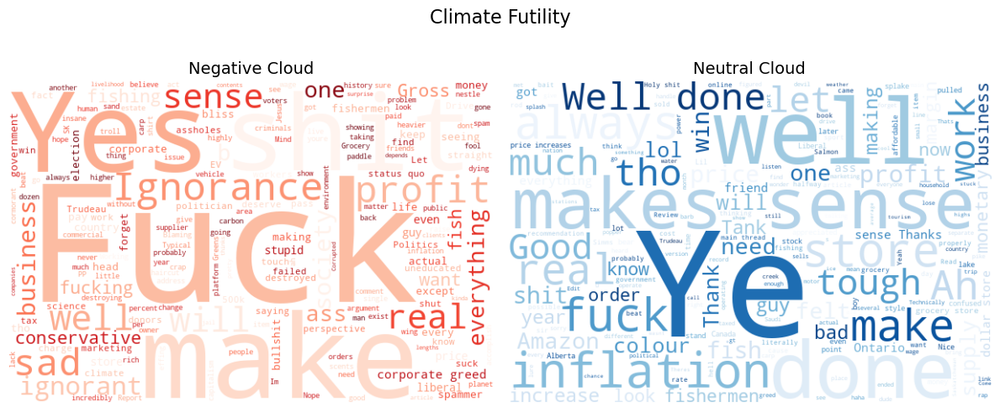


============ TOPIC: Governance Failure ============

--- Negative posts (n=520) ---
1. 7 in 10 Canadian are also morons.
2. Damn your girlfriend is ugly. Looks like a dude. Also you're a moron.
3. none of this is good enough, we're so screwed.
4. Man, these fish suck.
5. DFO, GOVT'CAN'T STAND FOR PEPPLE WHO TRY FEED THEIR FAMILIES , ALL THEY WANT IS TAX DOLLARS!!!!😡😡😡😡.
6. Lazy ass-protesters [xkcd: Hyphen]( --- Beep boop, I'm a bot. - [FAQ](.
7. Idiots like you are how idiots like him are going to end up in power and fucking us all over.
8. Complete garbage, hope these guys get a knock on the door from a conservation officer.
9. I do not like Pierre or JT. The options mostly all suck.
10. This shirt sucks more dick than your mom at work.

--- Neutral posts (n=5991) ---
1. Go get a license and pick up a copy of the regulations at the same time. Pick a place close to your house and read,understand and follow the regulations for that area.
2. If you can get to a tackle shop, pick up a f

/var/folders/hv/1wjfjdqn1ws_kws3tmwgk9f00000gn/T/ipykernel_39162/2116427442.py:65: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df_on   = df_sent[df_sent['CleanedText'].str.contains(pattern)]


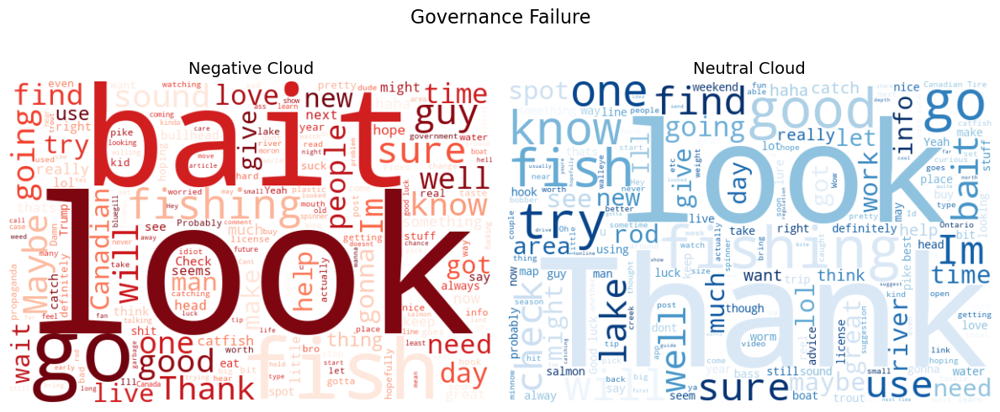


============ TOPIC: Overfishing & Climate ============

--- Negative posts (n=198) ---
1. Bass are disgusting 🤮never eat bass parasite and worm filled fish. Not that hillbilly to ever eat Bass.
2. FISH FUCKER.
3. a Drum. sucker fish. bony, not very good eating at all.
4. Under a house, sick!
5. Big ass blood sucker.
6. trash eating fish. wayyyy to many bones.
7. Scum fish.
8. Yeye loser go eat your perch faggg ahahaha 🖕.
9. yea chain pickerel SUCK to filet bone city every time.
10. Sick fish sick hat.

--- Neutral posts (n=3029) ---
1. Walleye are open in the Detroit River in April?
2. Is 3rd Saturday in May Bass or Walleye?
3. Go to Lac St Anne. Grab some walleye B tags (43cm-50cm) and buy a couple crank baits.
4. Have you tried a bottom bouncer and a walleye rig?
5. I did, i see pics of walleye.
6. Try at the mouth of the Whitemud creek, the storm outlet in Hermitage Park or opposite the river from there by the Epcor spillway and downstream of there. Walleye, gators and, in the begi

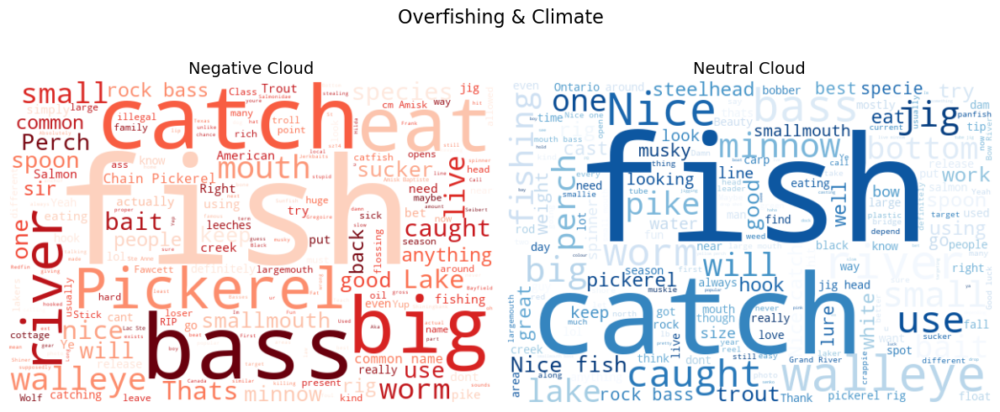


============ TOPIC: Pollution Concern ============

--- Negative posts (n=315) ---
1. What a bunch of fuckin bozos. Disgraceful.
2. So disgusting. What ever happened to decency and integrity? Bunch of greedy liars.
3. Oh piss off with this world is doomed bullshit.
4. What a bunch of losers. Disrupting lives of common people like that.
5. Nobody gives a fuck anymore. You just sound like a douche-bag.
6. FUCK WASPISES THEY NEVER FOLLLOW PROTO.
7. People. What a bunch of bastards.
8. Goby . You kill the piece of shit cunt and kill as many as you can catch.
9. Young earth religious trash detected. Never ever give your opinions on science again.
10. What a bunch of idiots.

--- Neutral posts (n=1582) ---
1. Whats the slot size there? Have heard its mid 20s.
2. I sent an email to their general mail box.
3. I seen your posts on Fishbrain.
4. You ever come out to the kw region at all?
5. Ok is that just west of McKinnon flats?
6. Sunwapta falls in on the icefields parkway. Im talking Kananas

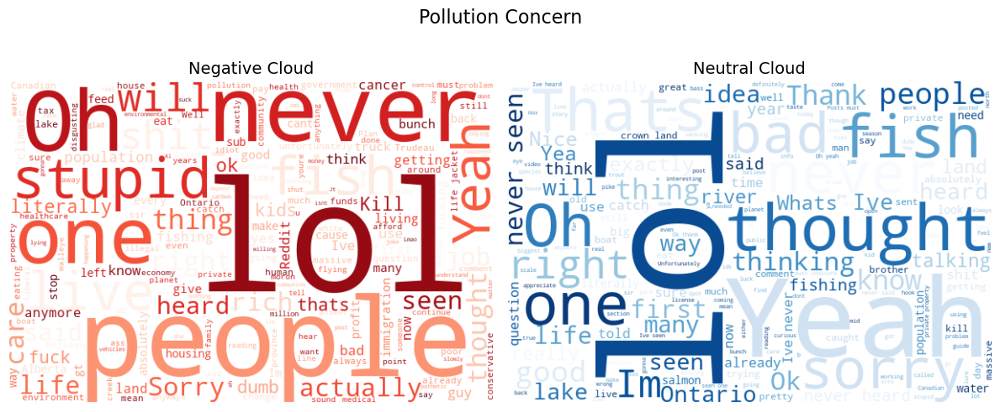

In [246]:
import re
import pandas as pd
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# ─── ASSUMPTION ────────────────────────────────────────────────────────────────
# reddit DataFrame already has:
#   • Topic_Label    (e.g. 'Climate Futility', ...)
#   • Broad_Emotion  ('Positive', 'Neutral', 'Negative')
#   • CleanedText    (the cleaned post content)
#   • POS_Prob, NEU_Prob, NEG_Prob  (confidence scores)

# ─── PARAMETERS ────────────────────────────────────────────────────────────────
inspect_topics = [
    'Climate Futility',
    'Governance Failure',
    'Overfishing & Climate',
    'Pollution Concern',
]
n_examples = 10

# define “on‐topic” keywords for Neutral filtering (optional)
topic_keywords = {
    'Climate Futility':      ['futility', 'won’t', 'can’t', 'pointless', 'reset'],
    'Governance Failure':    ['government', 'policy', 'enforcement', 'regulations'],
    'Overfishing & Climate': ['overfish', 'walleye', 'harvest', 'carbon', 'footprint'],
    'Pollution Concern':     ['pollut', 'microplastics', 'ecosystem', 'Arctic'],
}

# colormaps for wordclouds
wc_cmaps = {
    'Negative': 'Reds',
    'Neutral':  'Blues'
}

# ─── LOOP & PRINT + PLOT WORDCLOUDS ────────────────────────────────────────────
for topic in inspect_topics:
    print(f"\n{'='*12} TOPIC: {topic} {'='*12}\n")
    df_topic = reddit[reddit['Topic_Label'] == topic].reset_index(drop=True)
    if df_topic.empty:
        print("  (No posts for this topic)\n")
        continue

    # set up a 1×2 grid for this topic’s two clouds
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    fig.suptitle(topic, fontsize=16, y=1.02)

    for ax, (sentiment, prob_col) in zip(axes, [
        ('Negative', 'NEG_Prob'),
        ('Neutral',  'NEU_Prob'),
    ]):
        df_sent = df_topic[df_topic['Broad_Emotion'] == sentiment].reset_index(drop=True)
        total = len(df_sent)
        print(f"--- {sentiment} posts (n={total}) ---")

        if total == 0:
            print("  (none)\n")
            ax.axis('off')
            continue

        # for Neutral, optionally filter by on-topic keywords
        if sentiment == 'Neutral':
            kws     = topic_keywords.get(topic, [])
            pattern = re.compile(r'\b(' + '|'.join(map(re.escape, kws)) + r')\b', re.IGNORECASE)
            df_on   = df_sent[df_sent['CleanedText'].str.contains(pattern)]
            sel     = df_on.sort_values(prob_col, ascending=False).head(n_examples)
            if len(sel) < n_examples:
                # fill up with highest‐confidence neutrals
                needed   = n_examples - len(sel)
                fallback = df_sent.drop(sel.index)\
                                  .sort_values(prob_col, ascending=False)\
                                  .head(needed)
                sel      = pd.concat([sel, fallback])
        else:
            # straightforward top‐N for Negative
            sel = df_sent.sort_values(prob_col, ascending=False).head(n_examples)

        # print the examples
        for i, txt in enumerate(sel['CleanedText'], 1):
            print(f"{i}. {txt}")
        print()

        # build and display wordcloud from all sentiment posts
        corpus = " ".join(df_sent['CleanedText'])
        wc = WordCloud(
            width=600, height=400,
            background_color='white',
            colormap=wc_cmaps[sentiment]
        ).generate(corpus)
        ax.imshow(wc, interpolation='bilinear')
        ax.set_title(f"{sentiment} Cloud", fontsize=14)
        ax.axis('off')

    plt.tight_layout()
    plt.show()


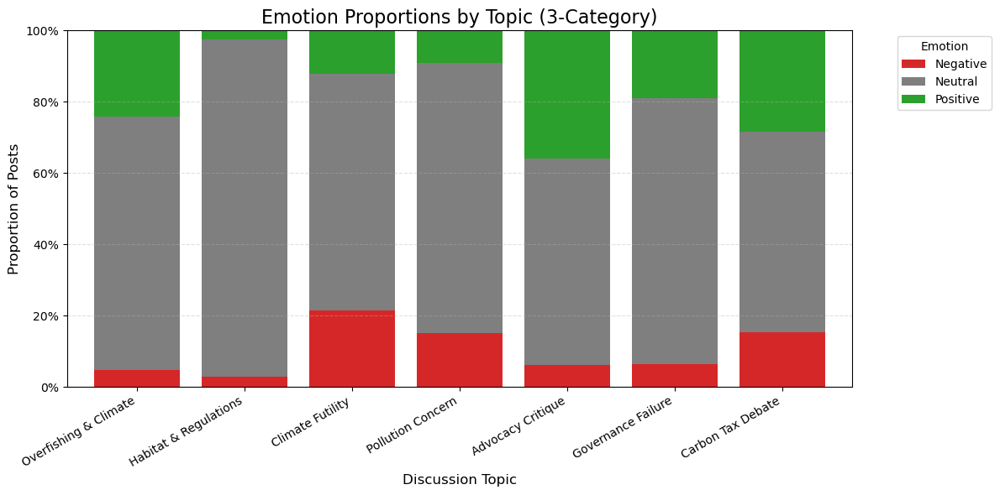

In [254]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Assuming emotion_table_fb is your pd.crosstab of the 7 emotions by numeric Topic ID:
#    index = Topic IDs 0–17, columns = ['Anger','Disgust','Fear','Sadness','Joy','Other','Surprise']

# 1) Select only the topics you care about
valid_topics = [1, 3, 4, 8, 9, 10, 11]
sub = emotion_table_fb.loc[valid_topics]

# 2) Map numeric topic → human label
topic_labels = {
    1:  'Overfishing & Climate',
    3:  'Habitat & Regulations',
    4:  'Climate Futility',
    8:  'Pollution Concern',
    9:  'Advocacy Critique',
    10: 'Governance Failure',
    11: 'Carbon Tax Debate',
}
sub.index = sub.index.map(topic_labels)

# 3) Collapse the 7 emotions into 3 buckets
collapse_map = {
    'Anger':    'Negative',
    'Disgust':  'Negative',
    'Fear':     'Negative',
    'Sadness':  'Negative',
    'Joy':      'Positive',
    'Other':    'Neutral',
    'Surprise': 'Neutral'
}
# rename columns, then sum by the new names
collapsed = sub.rename(columns=collapse_map).groupby(axis=1, level=0).sum()

# 4) Normalize row‐wise to proportions
prop3 = collapsed.div(collapsed.sum(axis=1), axis=0)

# 5) Plot
ax = prop3.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6),
    color=['tab:red','tab:gray','tab:green'],  # Negative / Neutral / Positive
    width=0.8
)

# y-axis to show 0–1
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f'{int(y*100)}%'))

plt.title('Emotion Proportions by Topic (3-Category)', fontsize=16)
plt.xlabel('Discussion Topic', fontsize=12)
plt.ylabel('Proportion of Posts', fontsize=12)
plt.xticks(rotation=30, ha='right')
plt.legend(title='Emotion', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


/opt/anaconda3/lib/python3.12/site-packages/pandas/core/algorithms.py:522: DeprecationWarning: np.find_common_type is deprecated.  Please use `np.result_type` or `np.promote_types`.
See https://numpy.org/devdocs/release/1.25.0-notes.html and the docs for more information.  (Deprecated NumPy 1.25)
  common = np.find_common_type([values.dtype, comps_array.dtype], [])


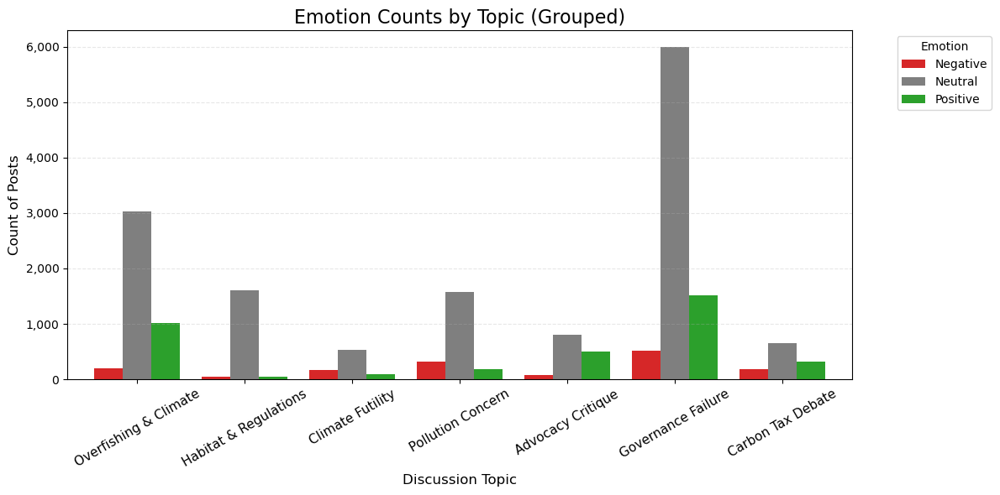

In [256]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# ─── Build your collapsed counts ───────────────────────────────────────────────
topic_labels = {
    1:  'Overfishing & Climate',
    3:  'Habitat & Regulations',
    4:  'Climate Futility',
    8:  'Pollution Concern',
    9:  'Advocacy Critique',
    10: 'Governance Failure',
    11: 'Carbon Tax Debate',
}

# Make sure df_filtered has only the topics you care about and a 'Broad_Emotion' column
valid_topics = list(topic_labels.keys())
df2 = df_filtered[df_filtered['Topic'].isin(valid_topics)].copy()

# Crosstab: rows=Topic ID, cols=Broad_Emotion
collapsed = pd.crosstab(
    df2['Topic'],
    df2['Broad_Emotion']
)[['Negative','Neutral','Positive']]  # enforce desired column order

# ─── Remap index to labels and reorder ─────────────────────────────────────────
collapsed.index = collapsed.index.map(topic_labels)
collapsed = collapsed.loc[
    [
        'Overfishing & Climate',
        'Habitat & Regulations',
        'Climate Futility',
        'Pollution Concern',
        'Advocacy Critique',
        'Governance Failure',
        'Carbon Tax Debate',
    ]
]

# ─── Plot grouped bar chart ────────────────────────────────────────────────────
ax = collapsed.plot(
    kind='bar',
    figsize=(12,6),
    color=['tab:red','tab:gray','tab:green'],  # Negative, Neutral, Positive
    width=0.8,
)

ax.set_title('Emotion Counts by Topic (Grouped)', fontsize=16)
ax.set_xlabel('Discussion Topic', fontsize=12)
ax.set_ylabel('Count of Posts', fontsize=12)
ax.tick_params(axis='x', rotation=30, labelsize=11)
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{int(x):,}'))

plt.legend(title='Emotion', bbox_to_anchor=(1.05,1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()


In [260]:
import re
import pandas as pd

# ─── A) YOUR HUMAN TOPIC LABELS ─────────────────────────────────────────────────
topic_labels = {
    1:  'Overfishing & Climate',
    3:  'Habitat & Regulations',
    4:  'Climate Futility',
    8:  'Pollution Concern',
    9:  'Advocacy Critique',
    10: 'Governance Failure',
    11: 'Carbon Tax Debate',
}

# ─── B) DEFINE SIMPLE “ON-TOPIC” KEYWORDS ───────────────────────────────────────
topic_markers = {
    'Overfishing & Climate': ['overfish','walleye','harvest','climate','carbon','trout','bass'], 
    'Governance Failure':    ['government','policy','regulation','MNR','officer','enforce','fine'],
    'Climate Futility':      ['pointless','futility','reset','losing','mother nature','unicorn'],
    'Pollution Concern':     ['pollut','microplastic','toxin','ecosystem','contamin','oil','spill'],
}

# ─── C) HELPER TO GRAB RELEVANT POSTS ────────────────────────────────────────────
def show_relevant_posts(topic_name, sentiment_label, n=10):
    """
    Print up to n posts for a given topic+sentiment that contain at least one of the 
    topic_markers, ranked by that sentiment's probability.
    """
    # 1) invert topic_labels so we can filter by Topic_Label
    inv_map = {v:k for k,v in topic_labels.items()}
    if topic_name not in inv_map:
        print("Unknown topic:", topic_name)
        return
    topic_id = inv_map[topic_name]
    
    # 2) subset your reddit DataFrame
    df = reddit
    df = df[df['Topic']==topic_id]
    df = df[df['Broad_Emotion']==sentiment_label]
    
    # 3) build regex from markers
    markers = topic_markers.get(topic_name, [])
    if not markers:
        print(f"No markers for {topic_name}")
        return
    pattern = re.compile(r'\b(' + '|'.join(map(re.escape, markers)) + r')\b', re.IGNORECASE)

    # 4) filter only those posts containing a marker
    df_on = df[df['CleanedText'].str.contains(pattern)]
    
    # 5) rank by the appropriate confidence column
    prob_col = {
      'Positive':'POS_Prob',
      'Neutral': 'NEU_Prob',
      'Negative':'NEG_Prob'
    }[sentiment_label]
    df_on = df_on.sort_values(prob_col, ascending=False)
    
    total_on = len(df_on)
    print(f"\n=== {sentiment_label} posts on “{topic_name}” (matched={total_on}) ===\n")
    for i, txt in enumerate(df_on['CleanedText'].head(n), 1):
        print(f"{i}. {txt}\n")
    if total_on==0:
        print("  (no on-topic posts found)\n")

# ─── D) TRY IT OUT FOR YOUR THREE INTERESTING TOPICS ─────────────────────────────
for TOP in ['Governance Failure','Overfishing & Climate','Climate Futility']:
    for EMO in ['Positive','Neutral','Negative']:
        show_relevant_posts(TOP, EMO, n=5)


=== Positive posts on “Governance Failure” (matched=3) ===

1. Hi there! The MNR actually has water level reports and flowcharts on their website. I don't have the exact web link but if you fire up the Google search I'm sure you can locate it. Good luck and have some fun out there!

2. Should be fine. Good luck.

3. Google MNR, and good luck!


=== Neutral posts on “Governance Failure” (matched=58) ===

1. Depends on the officer. Best to have the card or proof you have the card on you such as your phone suggestion.

2. After a quick search Id try here. Queen Of Apostles Renewal Centre (905) 278-5229 I dont know how strictly they enforce parking and I have not tried. You can always hike from Erin mills.

3. I'm pretty sure the MNR has an app now that would show your license?

4. i definitely agree, but a CO is the only one who can handover a fine.

5. Download the alberta relm app. Then you dont have to print off the copy. You can show that to the officer as long as you have service.



/var/folders/hv/1wjfjdqn1ws_kws3tmwgk9f00000gn/T/ipykernel_39162/1832574406.py:49: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df_on = df[df['CleanedText'].str.contains(pattern)]


In [262]:
import pandas as pd

# 1) make sure you have these columns in your reddit DataFrame:
#    • Topic_Label     (e.g. 'Climate Futility', etc.)
#    • Broad_Emotion   ('Positive','Neutral','Negative')
#    • POS_Prob, NEU_Prob, NEG_Prob  (confidence scores)
#    • CleanedText

# 2) define the buckets you care about
inspect_topics = [
    'Climate Futility',
    'Governance Failure',
    'Overfishing & Climate',
    'Pollution Concern',
]

# 3) for each topic & emotion, grab the top-50 by confidence and concatenate
exports = []
for topic in inspect_topics:
    df_topic = reddit[reddit['Topic_Label']==topic]
    for emotion, prob_col in [
        ('Positive','POS_Prob'),
        ('Neutral','NEU_Prob'),
        ('Negative','NEG_Prob'),
    ]:
        df_em = df_topic[df_topic['Broad_Emotion']==emotion]
        top50 = (
            df_em
            .sort_values(by=prob_col, ascending=False)
            .head(50)
            .assign(Topic=topic, Emotion=emotion)
            [['Topic','Emotion','CleanedText',prob_col]]
        )
        exports.append(top50)

candidates = pd.concat(exports, ignore_index=True)

# 4) write them to CSV
candidates.to_csv("manual_curation_candidates.csv", index=False)

print("Wrote", len(candidates), "rows to manual_curation_candidates.csv.")


Wrote 600 rows to manual_curation_candidates.csv.


/var/folders/hv/1wjfjdqn1ws_kws3tmwgk9f00000gn/T/ipykernel_6612/2997123510.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_sampled, x='Topic_Label', y='NEG_Prob', palette='Set2')
/opt/anaconda3/lib/python3.12/site-packages/pandas/core/algorithms.py:522: DeprecationWarning: np.find_common_type is deprecated.  Please use `np.result_type` or `np.promote_types`.
See https://numpy.org/devdocs/release/1.25.0-notes.html and the docs for more information.  (Deprecated NumPy 1.25)
  common = np.find_common_type([values.dtype, comps_array.dtype], [])
/opt/anaconda3/lib/python3.12/site-packages/pandas/core/algorithms.py:522: DeprecationWarning: np.find_common_type is deprecated.  Please use `np.result_type` or `np.promote_types`.
See https://numpy.org/devdocs/release/1.25.0-notes.html and the docs for more information.  (Deprecated 

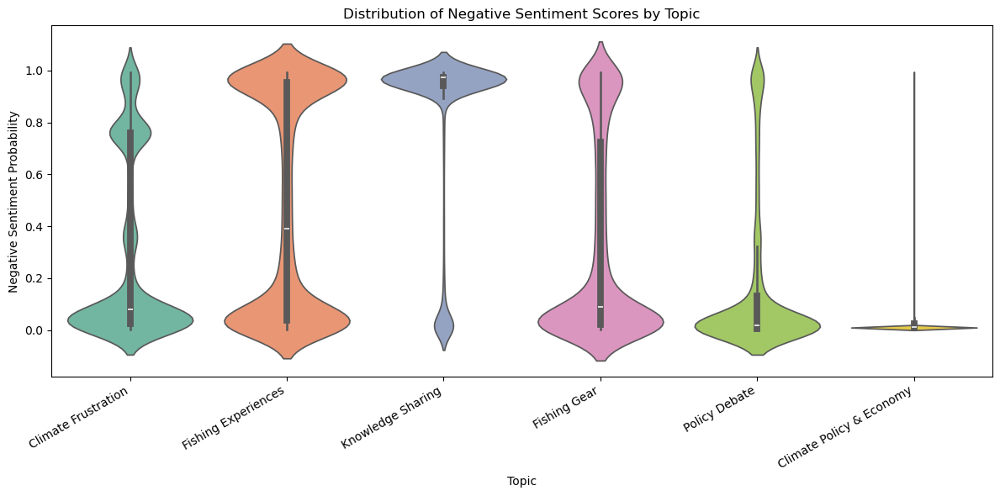

In [192]:
# import seaborn as sns
# import matplotlib.pyplot as plt

# # Optional: Use topic labels
# topic_labels = {
#     0: 'Climate Frustration',
#     1: 'Policy Debate',
#     2: 'Fishing Gear',
#     3: 'Knowledge Sharing',
#     4: 'Climate Policy & Economy',
#     5: 'Fishing Experiences'
# }
# df_sampled['Topic_Label'] = df_sampled['Topic'].map(topic_labels)

# # Violin plot of NEG_Prob per topic
# plt.figure(figsize=(12, 6))
# sns.violinplot(data=df_sampled, x='Topic_Label', y='NEG_Prob', palette='Set2')
# plt.title('Distribution of Negative Sentiment Scores by Topic')
# plt.ylabel('Negative Sentiment Probability')
# plt.xlabel('Topic')
# plt.xticks(rotation=30, ha='right')
# plt.tight_layout()
# plt.show()

In [264]:
from scipy.stats import f_oneway

# 1) Define exactly the topics you want to include
valid_topics = [1, 3, 4, 8, 9, 10, 11]

# 2) Build one array of NEG_Prob for each of those topics
groups = [
    df_sampled.loc[df_sampled['Topic'] == t, 'NEG_Prob']
    for t in valid_topics
]

# 3) Run the one-way ANOVA
anova_result = f_oneway(*groups)

print("ANOVA F-statistic:", anova_result.statistic)
print("P-value:", anova_result.pvalue)

ANOVA F-statistic: 111.48969945285047
P-value: 1.7176692982614732e-138


In [268]:
pip install scikit-posthocs

python(48916) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
/opt/anaconda3/lib/python3.12/pty.py:95: DeprecationWarning: This process (pid=39162) is multi-threaded, use of forkpty() may lead to deadlocks in the child.
  pid, fd = os.forkpty()


Note: you may need to restart the kernel to use updated packages.


In [270]:
# ─── INSTALL (only once) ───────────────────────────────────────────────────────
# pip install scipy scikit-posthocs

# ─── IMPORTS ─────────────────────────────────────────────────────────────────
import pandas as pd
from scipy.stats import kruskal
import scikit_posthocs as sp

# ─── PARAMETERS ───────────────────────────────────────────────────────────────
# List the topics you care about
topics = [1, 3, 4, 8, 9, 10, 11]

# ─── SUBSET YOUR DATA ─────────────────────────────────────────────────────────
# (Assumes df_sampled already exists with columns 'Topic' and 'NEG_Prob')
df = df_sampled[df_sampled['Topic'].isin(topics)].copy()

# ─── 1) KRUSKAL–WALLIS OMNIBUS TEST ────────────────────────────────────────────
# Build a list of NEG_Prob arrays, one per topic
groups = [df.loc[df['Topic'] == t, 'NEG_Prob'].values for t in topics]

# Run the test
stat, p = kruskal(*groups)
print(f"Kruskal–Wallis H = {stat:.3f}, p = {p:.3g}")

# ─── 2) DUNN’S POST-HOC (if omnibus is significant) ───────────────────────────
if p < 0.05:
    print("\nSince p < 0.05, we’ll do Dunn’s pairwise comparisons (Bonferroni‐corrected):")
    dunn = sp.posthoc_dunn(
        df,
        val_col='NEG_Prob',
        group_col='Topic',
        p_adjust='bonferroni'
    )
    # Only show rows/cols for our topics of interest
    dunn = dunn.loc[topics, topics]
    print(dunn)
else:
    print("No significant differences found; no post-hoc needed.")

/opt/anaconda3/lib/python3.12/site-packages/pandas/core/algorithms.py:522: DeprecationWarning: np.find_common_type is deprecated.  Please use `np.result_type` or `np.promote_types`.
See https://numpy.org/devdocs/release/1.25.0-notes.html and the docs for more information.  (Deprecated NumPy 1.25)
  common = np.find_common_type([values.dtype, comps_array.dtype], [])


Kruskal–Wallis H = 461.008, p = 2.1e-96

Since p < 0.05, we’ll do Dunn’s pairwise comparisons (Bonferroni‐corrected):
              1             3             4             8             9   \
1   1.000000e+00  1.079001e-07  5.526272e-51  2.538982e-13  2.194894e-01   
3   1.079001e-07  1.000000e+00  2.039123e-17  9.171933e-01  9.591932e-02   
4   5.526272e-51  2.039123e-17  1.000000e+00  3.727502e-09  2.881099e-27   
8   2.538982e-13  9.171933e-01  3.727502e-09  1.000000e+00  7.163603e-05   
9   2.194894e-01  9.591932e-02  2.881099e-27  7.163603e-05  1.000000e+00   
10  9.963148e-45  1.057736e-15  1.000000e+00  1.622549e-08  8.101430e-25   
11  1.000000e+00  2.554031e-07  4.505091e-46  1.470692e-12  2.010417e-01   

              10            11  
1   9.963148e-45  1.000000e+00  
3   1.057736e-15  2.554031e-07  
4   1.000000e+00  4.505091e-46  
8   1.622549e-08  1.470692e-12  
9   8.101430e-25  2.010417e-01  
10  1.000000e+00  3.662673e-41  
11  3.662673e-41  1.000000e+00  


/var/folders/hv/1wjfjdqn1ws_kws3tmwgk9f00000gn/T/ipykernel_6612/2864725788.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_sampled, x='Topic_Label', y='NEG_Prob', palette='coolwarm')
/opt/anaconda3/lib/python3.12/site-packages/pandas/core/algorithms.py:522: DeprecationWarning: np.find_common_type is deprecated.  Please use `np.result_type` or `np.promote_types`.
See https://numpy.org/devdocs/release/1.25.0-notes.html and the docs for more information.  (Deprecated NumPy 1.25)
  common = np.find_common_type([values.dtype, comps_array.dtype], [])
/opt/anaconda3/lib/python3.12/site-packages/pandas/core/algorithms.py:522: DeprecationWarning: np.find_common_type is deprecated.  Please use `np.result_type` or `np.promote_types`.
See https://numpy.org/devdocs/release/1.25.0-notes.html and the docs for more information.  (Deprecated

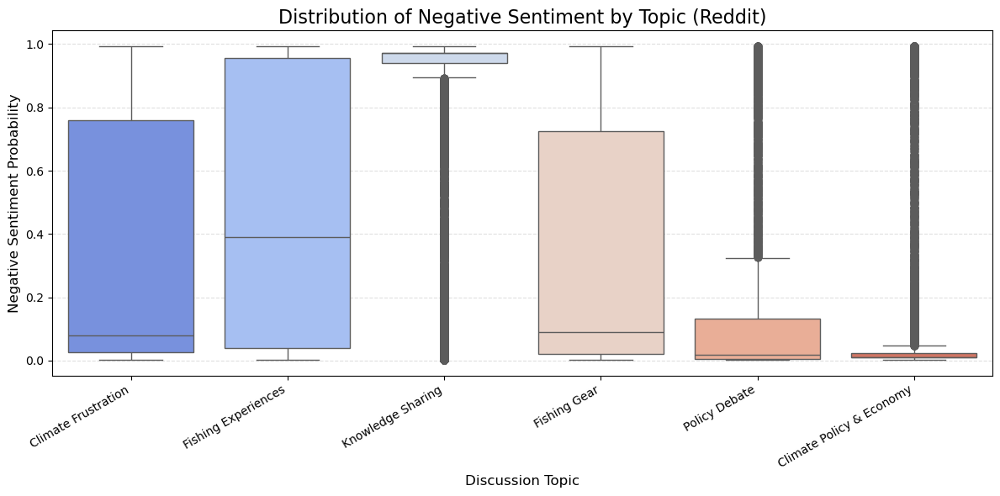

In [198]:
# import seaborn as sns
# import matplotlib.pyplot as plt

# # Optional: Apply readable topic labels again
# topic_labels = {
#     0: 'Climate Frustration',
#     1: 'Policy Debate',
#     2: 'Fishing Gear',
#     3: 'Knowledge Sharing',
#     4: 'Climate Policy & Economy',
#     5: 'Fishing Experiences'
# }
# df_sampled['Topic_Label'] = df_sampled['Topic'].map(topic_labels)

# # Plot boxplot
# plt.figure(figsize=(12, 6))
# sns.boxplot(data=df_sampled, x='Topic_Label', y='NEG_Prob', palette='coolwarm')

# # Labels and formatting
# plt.title('Distribution of Negative Sentiment by Topic (Reddit)', fontsize=16)
# plt.xlabel('Discussion Topic', fontsize=12)
# plt.ylabel('Negative Sentiment Probability', fontsize=12)
# plt.xticks(rotation=30, ha='right')
# plt.grid(axis='y', linestyle='--', alpha=0.4)
# plt.tight_layout()
# plt.show()

Chi-square: 1690.79, p = 0


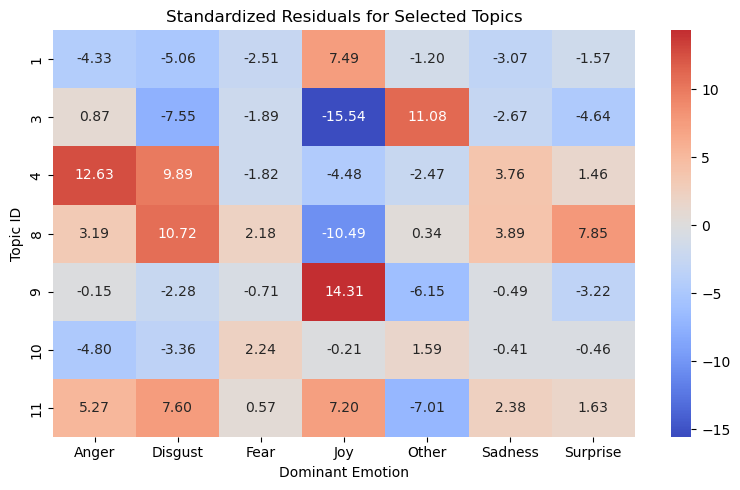

In [274]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

# ─── 1) Build full Topic×Emotion contingency ────────────────────────────────
emotion_ct_full = pd.crosstab(reddit['Topic'], reddit['Dominant_Emotion'])

# ─── 2) Restrict to your topics of interest ─────────────────────────────────
topics_of_interest = [1, 3, 4, 8, 9, 10, 11]
emotion_ct = emotion_ct_full.loc[topics_of_interest]

# ─── 3) Run χ² on the subset ────────────────────────────────────────────────
chi2, p, dof, expected = chi2_contingency(emotion_ct)
print(f"Chi-square: {chi2:.2f}, p = {p:.2g}")

# ─── 4) Compute standardized residuals ─────────────────────────────────────
observed = emotion_ct.values
expected = expected  # already aligned with emotion_ct
resid    = (observed - expected) / np.sqrt(expected)

# ─── 5) Plot heatmap of residuals ──────────────────────────────────────────
plt.figure(figsize=(8, 5))
sns.heatmap(
    resid,
    annot=True, fmt=".2f",
    cmap="coolwarm", center=0,
    xticklabels=emotion_ct.columns,
    yticklabels=emotion_ct.index
)
plt.title("Standardized Residuals for Selected Topics")
plt.xlabel("Dominant Emotion")
plt.ylabel("Topic ID")
plt.tight_layout()
plt.show()

In [276]:
# ─── PREAMBLE ────────────────────────────────────────────────────────────────
# assumes you have a DataFrame `reddit` with columns:
#   • reddit['Topic']          (numeric topic IDs)
#   • reddit['CleanedText']    (preprocessed post text)
#   • reddit['Dominant_Emotion'] ("Anger","Disgust","Joy", etc.)
#   • reddit['POS_Prob'], reddit['NEU_Prob'], reddit['NEG_Prob']

import pandas as pd

# ─── STEP 1: assign human‐readable topic labels ─────────────────────────────
topic_names = {
    1:  'Overfishing & Climate',
    3:  'Habitat & Regulations',
    4:  'Climate Futility',
    8:  'Pollution Concern',
    9:  'Advocacy Critique',
    10: 'Governance Failure',
    11: 'Carbon Tax Debate',
}
reddit['Topic_Label'] = reddit['Topic'].map(topic_names)

# ─── STEP 2: pick your “hotspots” from the residual heatmap ──────────────────
# (the cells with largest positive standardized residuals)
hotspots = [
    ('Climate Futility',  'Anger'),
    ('Pollution Concern', 'Disgust'),
    ('Advocacy Critique', 'Joy'),
]

# map each fine‐grained emotion to its confidence column
prob_col = {
    'Anger':    'NEG_Prob',   # anger lives in the Negative bucket
    'Disgust':  'NEG_Prob',
    'Fear':     'NEG_Prob',
    'Sadness':  'NEG_Prob',
    'Joy':      'POS_Prob',
    'Other':    'NEU_Prob',
    'Surprise': 'NEU_Prob',
}

n_examples = 10

# ─── STEP 3: extract & print top posts for each hotspot ─────────────────────
for topic_label, emotion in hotspots:
    col = prob_col[emotion]
    print(f"\n{'='*12} TOPIC: {topic_label}   EMOTION: {emotion} {'='*12}\n")
    
    # filter to that cell
    df_cell = reddit[
        (reddit['Topic_Label'] == topic_label) &
        (reddit['Dominant_Emotion'] == emotion)
    ].copy()
    
    total = len(df_cell)
    print(f"Total {emotion} posts in “{topic_label}”: {total}\n")
    if total == 0:
        print("  (none found)\n")
        continue
    
    # pick the top‐n by confidence
    topn = (
        df_cell
        .sort_values(by=col, ascending=False)
        .head(n_examples)
        ['CleanedText']
        .tolist()
    )
    
    for i, txt in enumerate(topn, 1):
        print(f"{i}. {txt}")
    print()



============ TOPIC: Climate Futility   EMOTION: Anger ============

Total Anger posts in “Climate Futility”: 47

1. Fuck the conservatives indeed. They are fucking over future.
2. fuck a cormorant. all my homies hate cormorants.
3. Fuck this guy, seriously.
4. What the fuck dude, get out of here with this bullshit.
5. Do you know who is introducing them? Report those assholes! Fucking carp are destroying our fishing diversity.
6. fucking stupid assholes. Should've gone over and confronted them.
7. Fuck off scammer!
8. You didn't even bother with math just went straight to straight confident ignorance, Shut the fuck up you brain dead shill.
9. Fuck nestle too tho. dont dismiss piece of shit nestle.
10. Fuck off with this shit. Spam bot.


============ TOPIC: Pollution Concern   EMOTION: Disgust ============

Total Disgust posts in “Pollution Concern”: 237

1. What a bunch of fuckin bozos. Disgraceful.
2. So disgusting. What ever happened to decency and integrity? Bunch of greedy liars.

<Figure size 1000x400 with 0 Axes>

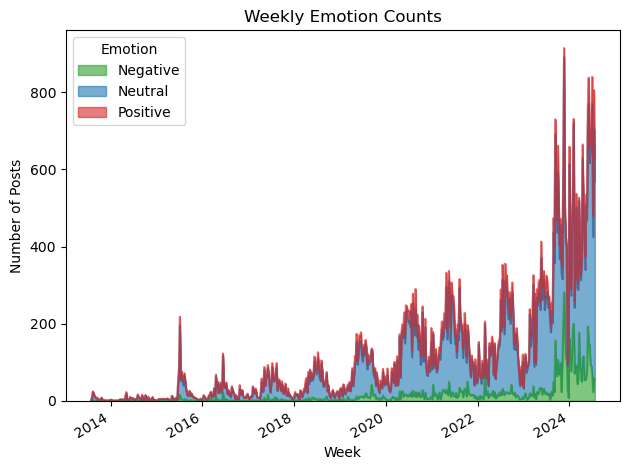

<Figure size 1000x400 with 0 Axes>

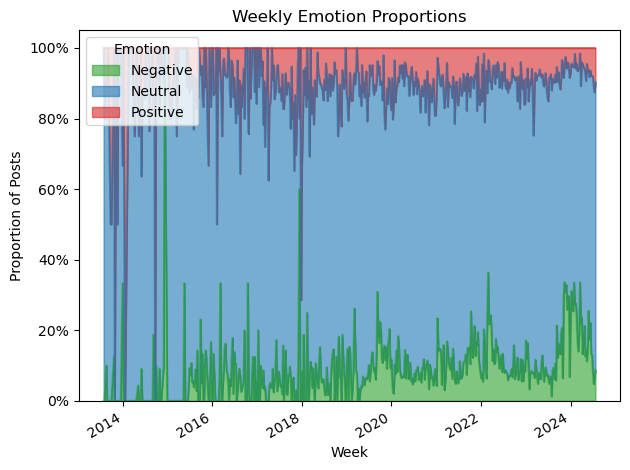

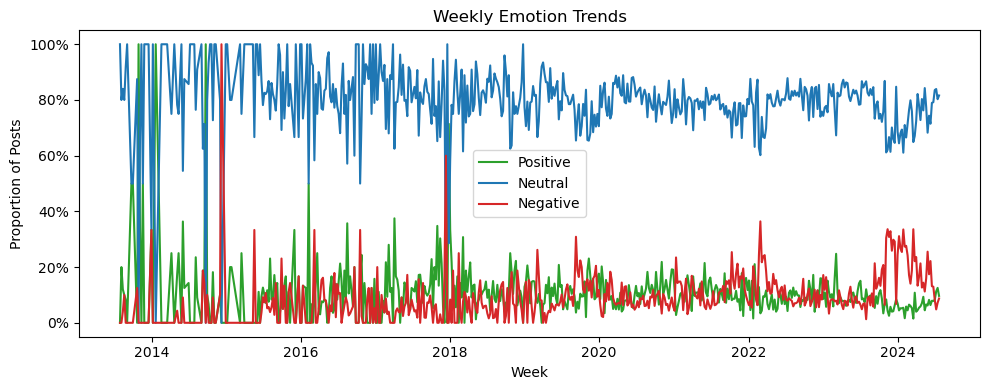

In [278]:
import pandas as pd
import matplotlib.pyplot as plt

# ─── PREP: Ensure you have Date + Broad_Emotion ───────────────────────────────
# reddit['Date'] should already be datetime; if not:
reddit['Date'] = pd.to_datetime(reddit['Date'])

# Suppose you already mapped your seven fine-grained emotions
# into three broad ones, e.g.:
#   reddit['Broad_Emotion'] ∈ {'Positive','Neutral','Negative'}

# ─── BUCKET INTO WEEKS ────────────────────────────────────────────────────────
# Create a “week start” timestamp for each post
reddit['Week'] = reddit['Date'].dt.to_period('W').dt.start_time

# ─── AGGREGATE COUNTS BY WEEK × EMOTION ───────────────────────────────────────
weekly_counts = (
    reddit
    .groupby(['Week','Broad_Emotion'])
    .size()
    .unstack(fill_value=0)
    .sort_index()
)

# You can also get **proportions** per week:
weekly_props = weekly_counts.div(weekly_counts.sum(axis=1), axis=0)

# ─── 1) PLOT RAW COUNTS AS STACKED AREA ─────────────────────────────────────
plt.figure(figsize=(10,4))
weekly_counts.plot.area(
    color=['tab:green','tab:blue','tab:red'],
    alpha=0.6
)
plt.title("Weekly Emotion Counts")
plt.ylabel("Number of Posts")
plt.xlabel("Week")
plt.legend(title="Emotion")
plt.tight_layout()
plt.show()

# ─── 2) PLOT PROPORTIONS AS STACKED AREA ────────────────────────────────────
plt.figure(figsize=(10,4))
weekly_props.plot.area(
    color=['tab:green','tab:blue','tab:red'],
    alpha=0.6
)
plt.title("Weekly Emotion Proportions")
plt.ylabel("Proportion of Posts")
plt.xlabel("Week")
plt.gca().yaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
plt.legend(title="Emotion", loc='upper left')
plt.tight_layout()
plt.show()

# ─── 3) ALTERNATIVE: ONE LINE PER EMOTION ───────────────────────────────────
plt.figure(figsize=(10,4))
for emo, col in zip(['Positive','Neutral','Negative'],
                    ['tab:green','tab:blue','tab:red']):
    plt.plot(weekly_props.index, weekly_props[emo], label=emo, color=col)
plt.title("Weekly Emotion Trends")
plt.ylabel("Proportion of Posts")
plt.xlabel("Week")
plt.gca().yaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
plt.legend()
plt.tight_layout()
plt.show()


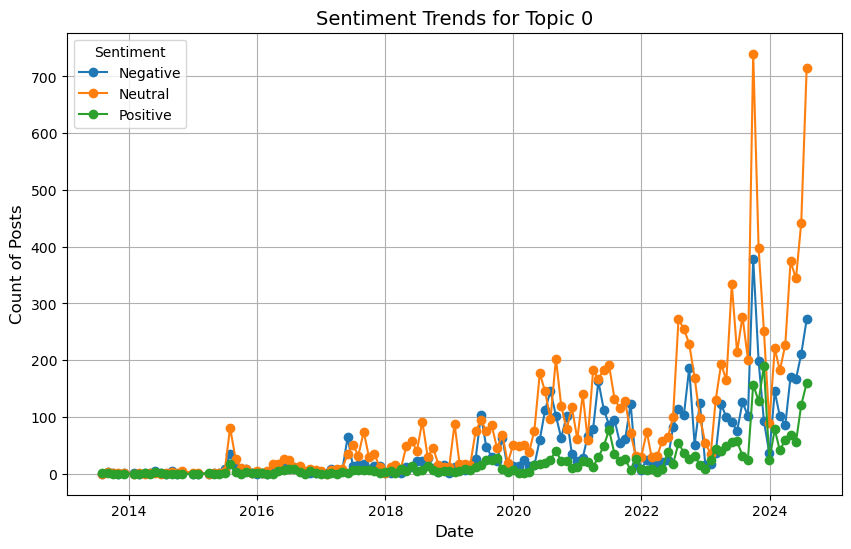

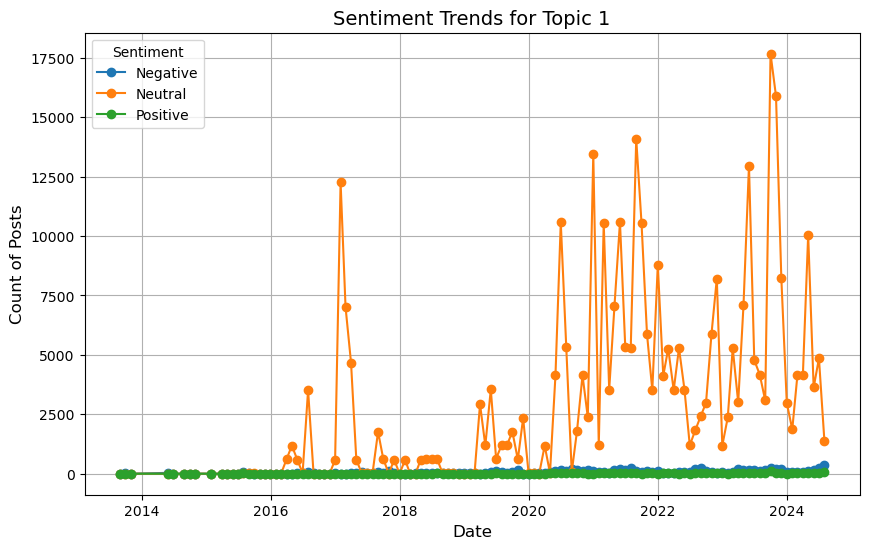

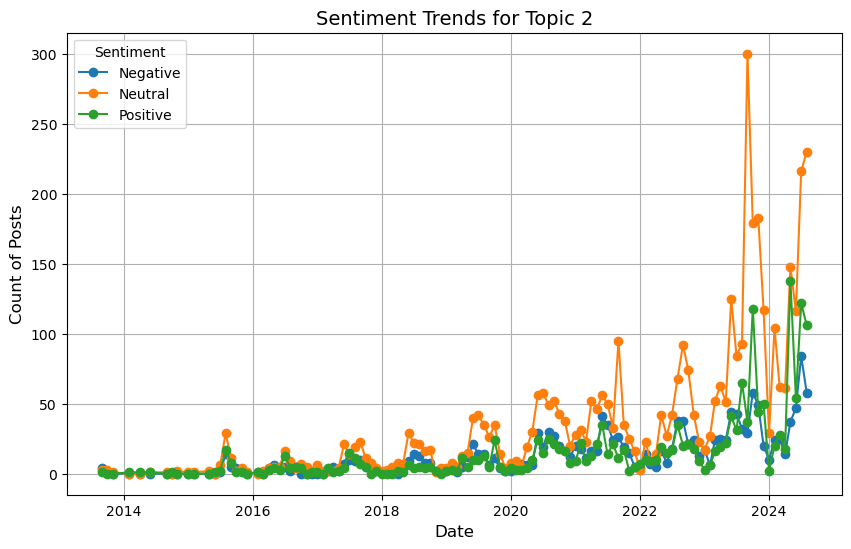

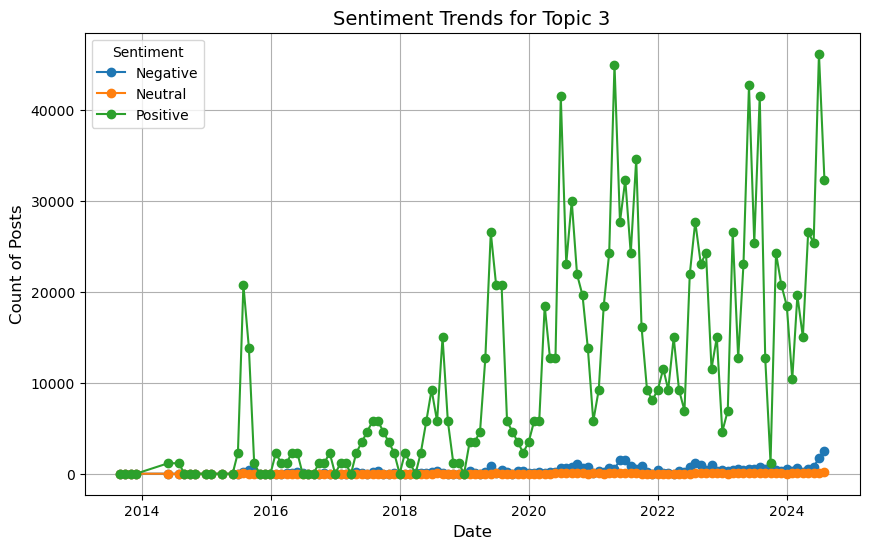

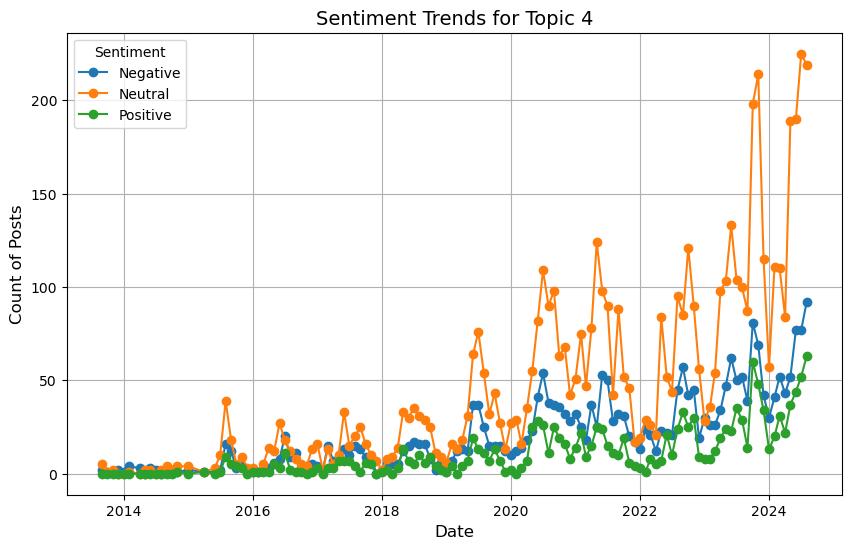

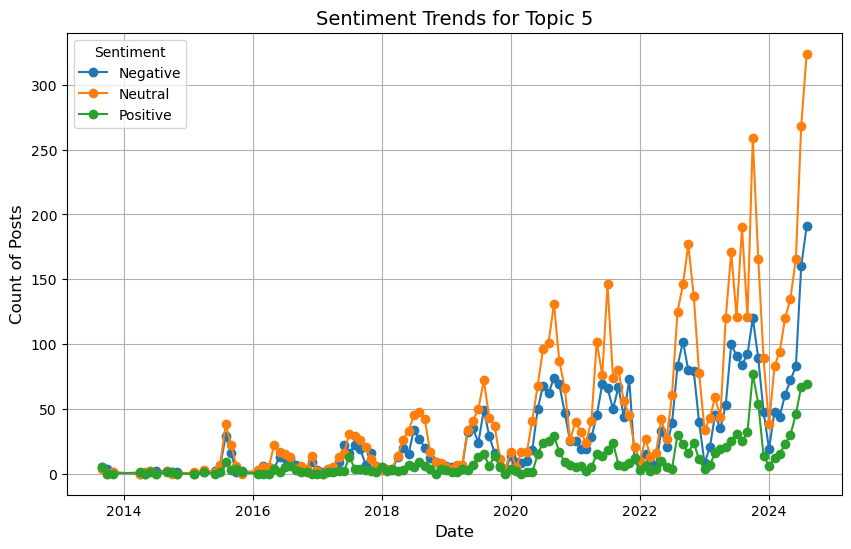

In [76]:
import matplotlib.pyplot as plt

# Loop through unique topics and plot sentiment trends
for topic in sentiment_trends['Topic'].unique():
    topic_data = sentiment_trends[sentiment_trends['Topic'] == topic]
    
    plt.figure(figsize=(10, 6))
    
    # Plot sentiment trends over time
    plt.plot(topic_data['Date'], topic_data.get('NEG_Prob', 0), label='Negative', marker='o')
    plt.plot(topic_data['Date'], topic_data.get('NEU_Prob', 0), label='Neutral', marker='o')
    plt.plot(topic_data['Date'], topic_data.get('POS_Prob', 0), label='Positive', marker='o')
    
    plt.title(f'Sentiment Trends for Topic {topic}', fontsize=14)
    plt.xlabel('Date', fontsize=12)
    plt.ylabel('Count of Posts', fontsize=12)
    plt.legend(title="Sentiment")
    plt.grid(True)
    plt.show()

In [134]:
topic_labels = {
    0: 'Climate Frustration',
    1: 'Policy Debate',
    2: 'Fishing Gear',
    3: 'Knowledge Sharing',
    4: 'Moderation/Economy',
    5: 'Fishing Experiences'
}

contingency.index = contingency.index.map(topic_labels)
proportions.index = proportions.index.map(topic_labels)

In [77]:
import pymannkendall as mk
import pandas as pd

# Group by Date and Topic to aggregate sentiment probabilities
neg_trend_data = df_sampled.groupby([pd.Grouper(freq='M'), 'Topic']).agg({'NEG_Prob': 'mean'}).reset_index()

# Check the aggregated data
print(neg_trend_data.head())

C:\Users\sherif.s\AppData\Local\Temp\ipykernel_12620\1091349697.py:5: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  neg_trend_data = df_sampled.groupby([pd.Grouper(freq='M'), 'Topic']).agg({'NEG_Prob': 'mean'}).reset_index()


        Date  Topic  NEG_Prob
0 2013-07-31      0  0.003875
1 2013-08-31      0  0.376578
2 2013-08-31      1  0.563971
3 2013-08-31      2  0.424644
4 2013-08-31      3  0.667661


In [78]:
# Apply Mann-Kendall test to check trend for each topic
topic_results = {}

for topic in neg_trend_data['Topic'].unique():
    # Filter data for the topic
    topic_data = neg_trend_data[neg_trend_data['Topic'] == topic]
    
    # Apply Mann-Kendall test on NEG_Prob
    mk_result = mk.original_test(topic_data['NEG_Prob'].dropna())
    
    # Store the results
    trend = mk_result.trend
    p_value = mk_result.p
    slope = mk_result.slope
    
    # Print result for each topic
    print(f"Topic {topic}: Trend is {trend} with p-value = {p_value:.5f} and slope = {slope:.5f}")
    
    # Store results in dictionary for further reference
    topic_results[topic] = {'trend': trend, 'p_value': p_value, 'slope': slope}

Topic 0: Trend is no trend with p-value = 0.58409 and slope = -0.00017
Topic 1: Trend is decreasing with p-value = 0.00000 and slope = -0.00217
Topic 2: Trend is no trend with p-value = 0.91892 and slope = 0.00004
Topic 3: Trend is no trend with p-value = 0.11959 and slope = -0.00015
Topic 4: Trend is decreasing with p-value = 0.01062 and slope = -0.00060
Topic 5: Trend is decreasing with p-value = 0.00172 and slope = -0.00081


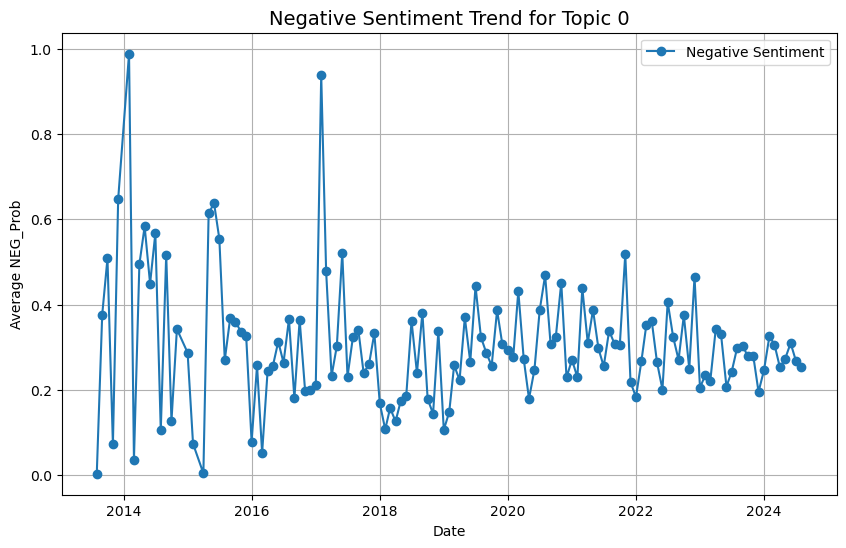

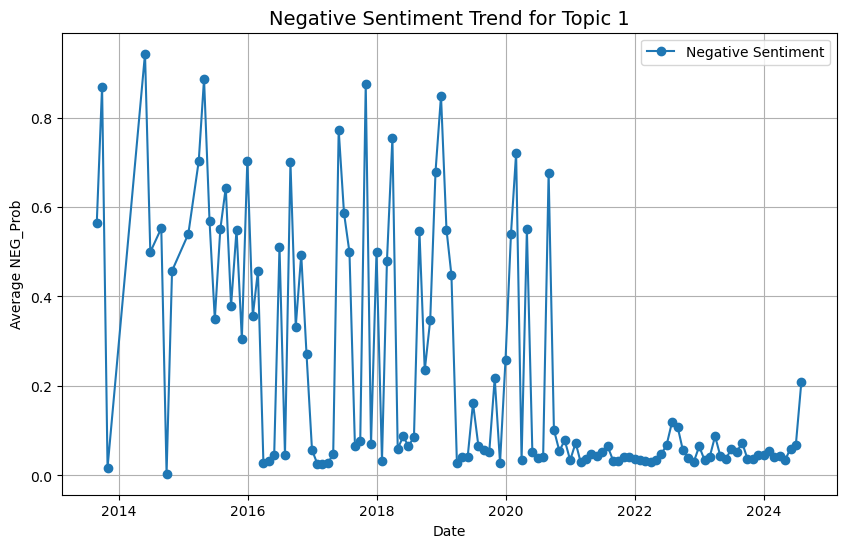

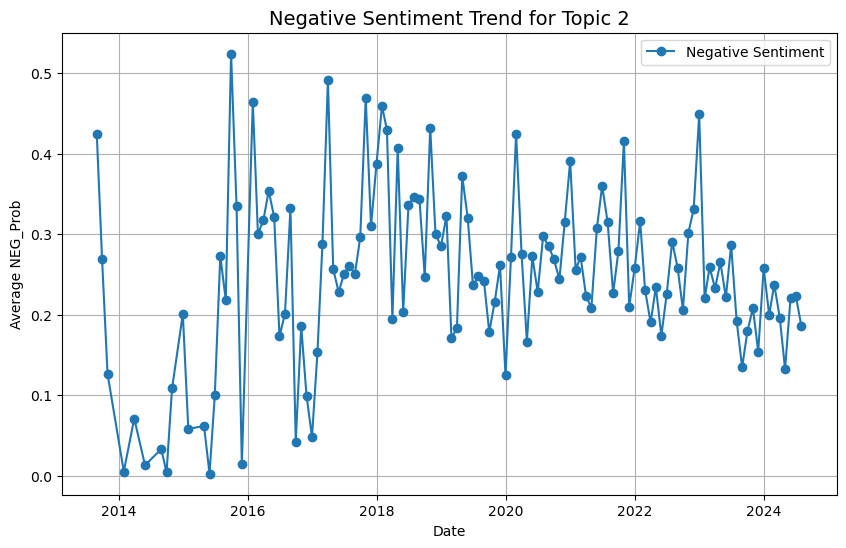

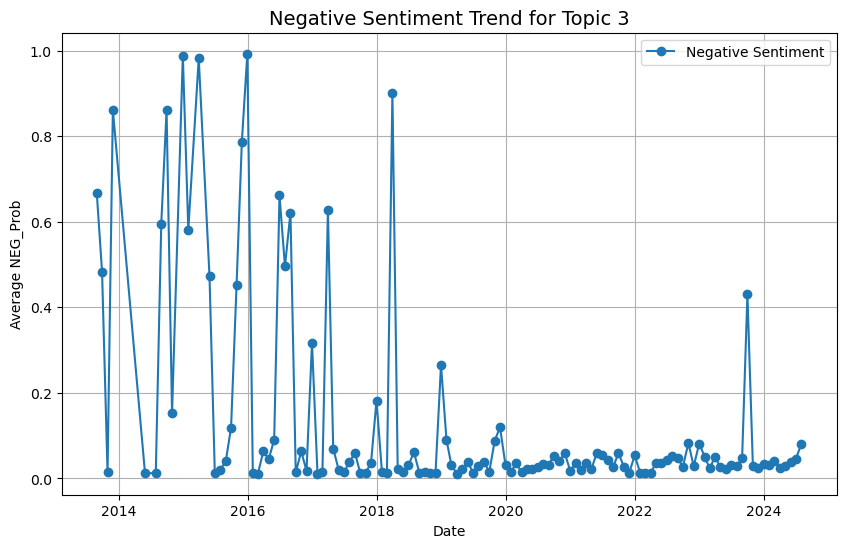

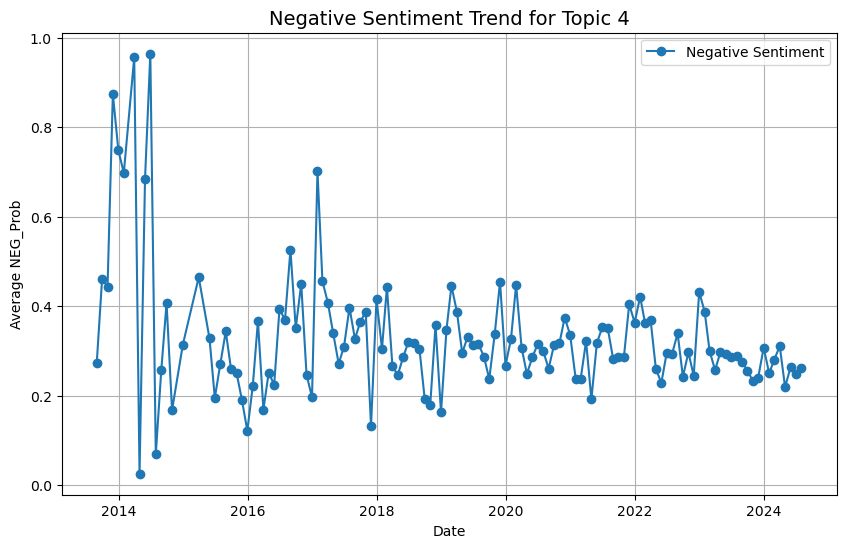

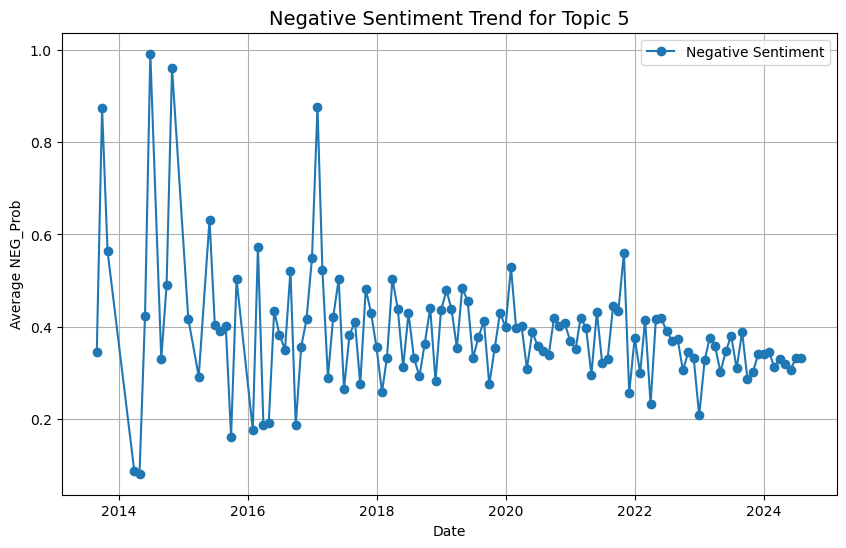

In [79]:
import matplotlib.pyplot as plt

# Visualize trends for each topic
for topic in neg_trend_data['Topic'].unique():
    topic_data = neg_trend_data[neg_trend_data['Topic'] == topic]
    
    plt.figure(figsize=(10, 6))
    plt.plot(topic_data['Date'], topic_data['NEG_Prob'], marker='o', label='Negative Sentiment')
    
    plt.title(f'Negative Sentiment Trend for Topic {topic}', fontsize=14)
    plt.xlabel('Date')
    plt.ylabel('Average NEG_Prob')
    plt.grid(True)
    plt.legend()
    plt.show()

In [80]:
from scipy.stats import linregress
import numpy as np

# Apply Theil-Sen Estimator to check slope for each topic
for topic in neg_trend_data['Topic'].unique():
    # Filter data for the topic
    topic_data = neg_trend_data[neg_trend_data['Topic'] == topic].dropna()
    
    # Get the time index as numeric values (for slope calculation)
    time_numeric = np.arange(len(topic_data))
    
    # Apply linear regression to get slope
    slope, intercept, r_value, p_value, std_err = linregress(time_numeric, topic_data['NEG_Prob'])
    
    # Print results for each topic
    direction = "increasing" if slope > 0 else "decreasing"
    significance = "significant" if p_value < 0.05 else "not significant"
    print(f"Topic {topic}: Theil-Sen Slope is {direction} with slope = {slope:.5f}, p-value = {p_value:.5f}, trend is {significance}.")

Topic 0: Theil-Sen Slope is decreasing with slope = -0.00049, p-value = 0.15944, trend is not significant.
Topic 1: Theil-Sen Slope is decreasing with slope = -0.00426, p-value = 0.00000, trend is significant.
Topic 2: Theil-Sen Slope is increasing with slope = 0.00038, p-value = 0.17624, trend is not significant.
Topic 3: Theil-Sen Slope is decreasing with slope = -0.00325, p-value = 0.00000, trend is significant.
Topic 4: Theil-Sen Slope is decreasing with slope = -0.00114, p-value = 0.00084, trend is significant.
Topic 5: Theil-Sen Slope is decreasing with slope = -0.00101, p-value = 0.00423, trend is significant.


In [81]:
import pymannkendall as mk

# Apply Seasonal Kendall Test to check trend for each topic
for topic in neg_trend_data['Topic'].unique():
    # Filter data for the topic
    topic_data = neg_trend_data[neg_trend_data['Topic'] == topic].dropna()
    
    # Apply Seasonal Kendall Test on NEG_Prob
    seasonal_mk_result = mk.seasonal_test(topic_data['NEG_Prob'].tolist(), period=12)
    
    # Print results for each topic
    print(f"Topic {topic}: Seasonal Kendall Test Result: {seasonal_mk_result.trend} with p-value = {seasonal_mk_result.p:.5f}")

Topic 0: Seasonal Kendall Test Result: no trend with p-value = 0.56628
Topic 1: Seasonal Kendall Test Result: decreasing with p-value = 0.00001
Topic 2: Seasonal Kendall Test Result: no trend with p-value = 0.74363
Topic 3: Seasonal Kendall Test Result: no trend with p-value = 0.35795
Topic 4: Seasonal Kendall Test Result: decreasing with p-value = 0.00261
Topic 5: Seasonal Kendall Test Result: decreasing with p-value = 0.00867


In [82]:
from statsmodels.tsa.stattools import adfuller

# Apply ADF Test to check stationarity for each topic
for topic in neg_trend_data['Topic'].unique():
    # Filter data for the topic
    topic_data = neg_trend_data[neg_trend_data['Topic'] == topic]['NEG_Prob'].dropna()
    
    # Apply ADF Test
    adf_result = adfuller(topic_data)
    
    # Extract the p-value from the test
    p_value = adf_result[1]
    is_stationary = "Stationary" if p_value < 0.05 else "Non-stationary"
    
    # Print results
    print(f"Topic {topic}: ADF Test Result: {is_stationary} with p-value = {p_value:.5f}")

Topic 0: ADF Test Result: Stationary with p-value = 0.00000
Topic 1: ADF Test Result: Stationary with p-value = 0.00011
Topic 2: ADF Test Result: Stationary with p-value = 0.00000
Topic 3: ADF Test Result: Stationary with p-value = 0.00010
Topic 4: ADF Test Result: Stationary with p-value = 0.00000
Topic 5: ADF Test Result: Stationary with p-value = 0.00000


In [83]:
from scipy.stats import spearmanr

# Apply Spearman's Rank Correlation for each topic
for topic in neg_trend_data['Topic'].unique():
    # Filter data for the topic
    topic_data = neg_trend_data[neg_trend_data['Topic'] == topic].dropna()
    
    # Apply Spearman's correlation between time and NEG_Prob
    correlation, p_value = spearmanr(np.arange(len(topic_data)), topic_data['NEG_Prob'])
    
    # Print results for each topic
    direction = "positive" if correlation > 0 else "negative"
    significance = "significant" if p_value < 0.05 else "not significant"
    print(f"Topic {topic}: Spearman's Rank Correlation is {direction} with correlation = {correlation:.5f}, p-value = {p_value:.5f}, trend is {significance}.")


Topic 0: Spearman's Rank Correlation is negative with correlation = -0.05574, p-value = 0.52877, trend is not significant.
Topic 1: Spearman's Rank Correlation is negative with correlation = -0.45101, p-value = 0.00000, trend is significant.
Topic 2: Spearman's Rank Correlation is positive with correlation = 0.04960, p-value = 0.58747, trend is not significant.
Topic 3: Spearman's Rank Correlation is negative with correlation = -0.16272, p-value = 0.07214, trend is not significant.
Topic 4: Spearman's Rank Correlation is negative with correlation = -0.20126, p-value = 0.02328, trend is significant.
Topic 5: Spearman's Rank Correlation is negative with correlation = -0.25731, p-value = 0.00438, trend is significant.


In [204]:
import pandas as pd

# Load the data
reddit = pd.read_csv('//Users//sheffdeen//Downloads//Chapter4-Zahra//Reddit//FinalDataReddit.csv')
pd.set_option('display.max_columns', None)

# Preview the data
print(reddit.columns)
reddit.head()

/opt/anaconda3/lib/python3.12/site-packages/pandas/io/parsers/c_parser_wrapper.py:373: DeprecationWarning: np.find_common_type is deprecated.  Please use `np.result_type` or `np.promote_types`.
See https://numpy.org/devdocs/release/1.25.0-notes.html and the docs for more information.  (Deprecated NumPy 1.25)
  common_type = np.find_common_type(
/opt/anaconda3/lib/python3.12/site-packages/pandas/io/parsers/c_parser_wrapper.py:373: DeprecationWarning: np.find_common_type is deprecated.  Please use `np.result_type` or `np.promote_types`.
See https://numpy.org/devdocs/release/1.25.0-notes.html and the docs for more information.  (Deprecated NumPy 1.25)
  common_type = np.find_common_type(
/opt/anaconda3/lib/python3.12/site-packages/pandas/io/parsers/c_parser_wrapper.py:373: DeprecationWarning: np.find_common_type is deprecated.  Please use `np.result_type` or `np.promote_types`.
See https://numpy.org/devdocs/release/1.25.0-notes.html and the docs for more information.  (Deprecated NumPy 1.

Index(['subreddit_id', 'approved_at_utc', 'author_is_blocked', 'comment_type',
       'edited', 'mod_reason_by', 'banned_by', 'ups', 'num_reports',
       'author_flair_type', 'total_awards_received', 'subreddit',
       'author_flair_template_id', 'likes', 'replies', 'user_reports', 'saved',
       'id', 'banned_at_utc', 'mod_reason_title', 'gilded', 'archived',
       'collapsed_reason_code', 'no_follow', 'author', 'can_mod_post',
       'send_replies', 'parent_id', 'score', 'author_fullname',
       'report_reasons', 'removal_reason', 'approved_by', 'all_awardings',
       'body', 'awarders', 'top_awarded_type', 'downs',
       'author_flair_css_class', 'author_patreon_flair', 'collapsed',
       'author_flair_richtext', 'is_submitter', 'body_html', 'gildings',
       'collapsed_reason', 'associated_award', 'stickied', 'author_premium',
       'can_gild', 'link_id', 'unrepliable_reason', 'author_flair_text_color',
       'score_hidden', 'permalink', 'subreddit_type', 'locked', 'name

,subreddit_id,approved_at_utc,author_is_blocked,comment_type,edited,mod_reason_by,banned_by,ups,num_reports,author_flair_type,total_awards_received,subreddit,author_flair_template_id,likes,replies,user_reports,saved,id,banned_at_utc,mod_reason_title,gilded,archived,collapsed_reason_code,no_follow,author,can_mod_post,send_replies,parent_id,score,author_fullname,report_reasons,removal_reason,approved_by,all_awardings,body,awarders,top_awarded_type,downs,author_flair_css_class,author_patreon_flair,collapsed,author_flair_richtext,is_submitter,body_html,gildings,collapsed_reason,associated_award,stickied,author_premium,can_gild,link_id,unrepliable_reason,author_flair_text_color,score_hidden,permalink,subreddit_type,locked,name,created,author_flair_text,treatment_tags,created_utc,subreddit_name_prefixed,controversiality,author_flair_background_color,collapsed_because_crowd_control,mod_reports,mod_note,distinguished,date,author_created_utc,retrieved_on,retrieved_utc,quarantined,steward_reports,editable,author_cakeday,updated_utc,body_sha1,nest_level,utc_datetime_str,rte_mode,edited_on,media_metadata,CleanedText,Date,Week,Sentiment,Positive,Neutral,Negative,Emotion,Other,Anger,Disgust,Fear,Sadness,Joy,Surprise
0,t5_37mg1,NaN,False,NaN,False,NaN,NaN,1.0,NaN,text,0.0,FishingSaskatchewan,NaN,NaN,NaN,[],False,l8y2bin,NaN,NaN,0,False,NaN,True,colem5000,False,True,t3_14xpkwc,1,t2_2pn8ch5x,NaN,NaN,NaN,[],Bottom bounce at the mouth of the lake.,[],NaN,0.0,NaN,False,False,[],False,"&lt;div class=""md""&gt;&lt;p&gt;Bottom bounce a...",{},NaN,NaN,False,False,False,t3_14xpkwc,NaN,NaN,False,/r/FishingSaskatchewan/comments/14xpkwc/tobin_...,restricted,False,t1_l8y2bin,1.718591e+09,NaN,[],2024-06-17 02:18:41,r/FishingSaskatchewan,0,NaN,NaN,[],NaN,NaN,2024-06-16 22:18:41,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Bottom bounce at the mouth of the lake.,2024-06-17,2024-06-17,NEU,0.034740,0.956538,0.008721,others,0.976141,0.002050,0.005775,0.003888,0.001354,0.007159,0.003632
1,t5_37mg1,NaN,False,NaN,False,NaN,NaN,1.0,NaN,text,0.0,FishingSaskatchewan,NaN,NaN,NaN,[],False,l6x69af,NaN,NaN,0,False,NaN,True,dycker1978,False,True,t3_148izsi,1,t2_14ciqw,NaN,NaN,NaN,[],"Buffalo Pound has a provincial park on, that i...",[],NaN,0.0,NaN,False,False,[],False,"&lt;div class=""md""&gt;&lt;p&gt;Buffalo Pound h...",{},NaN,NaN,False,False,False,t3_148izsi,NaN,NaN,False,/r/FishingSaskatchewan/comments/148izsi/where_...,restricted,False,t1_l6x69af,1.717428e+09,NaN,[],2024-06-03 15:13:43,r/FishingSaskatchewan,0,NaN,NaN,[],NaN,NaN,2024-06-03 11:13:43,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"Buffalo Pound has a provincial park on, that i...",2024-06-03,2024-06-03,POS,0.725779,0.271237,0.002984,others,0.976320,0.001198,0.002544,0.002754,0.001711,0.012905,0.002568
2,t5_37mg1,NaN,False,NaN,False,NaN,NaN,1.0,NaN,text,0.0,FishingSaskatchewan,NaN,NaN,NaN,[],False,kdvyfdh,NaN,NaN,0,False,NaN,True,chihorse,False,True,t1_kdtk9p2,1,t2_axgk3t1n,NaN,NaN,NaN,[],Thanks!!,[],NaN,0.0,NaN,False,False,[],True,"&lt;div class=""md""&gt;&lt;p&gt;Thanks!!&lt;/p&...",{},NaN,NaN,False,False,False,t3_158m7cq,NaN,NaN,False,/r/FishingSaskatchewan/comments/158m7cq/fishin...,restricted,False,t1_kdvyfdh,1.702905e+09,NaN,[],2023-12-18 13:16:41,r/FishingSaskatchewan,0,NaN,NaN,[],NaN,NaN,2023-12-18 08:16:41,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Thanks!!,2023-12-18,2023-12-18,POS,0.988689,0.009532,0.001779,joy,0.076444,0.003595,0.001692,0.001114,0.001468,0.913222,0.002465
3,t5_37mg1,NaN,False,NaN,False,NaN,NaN,1.0,NaN,text,0.0,FishingSaskatchewan,NaN,NaN,NaN,[],False,kdtk9p2,NaN,NaN,0,False,NaN,True,Dull_General_6825,False,True,t3_158m7cq,1,t2_46xt0m46,NaN,NaN,NaN,[],There is definitely shore access at Zelma. I s...,[],NaN,0.0,NaN,False,False,[],False,"&lt;div class=""md""&gt;&lt;p&gt;There is defini...",{},NaN,NaN,False,False,False,t3_158m7cq,NaN,NaN,False,/r/FishingSaskatchewan/comments/158m7cq/fishin...,restricted,False,t1_kdtk9p2,1.702856e+09,NaN,[],2023-1

In [208]:
# Convert string to datetime (without unit)
reddit['created_utc'] = pd.to_datetime(reddit['created_utc'], errors='coerce')

# Drop rows with invalid/missing dates (if any)
reddit = reddit.dropna(subset=['created_utc'])

# Check the range of the timeline
start_date = reddit['created_utc'].min()
end_date = reddit['created_utc'].max()

print(f"Reddit data ranges from {start_date} to {end_date}")

Reddit data ranges from 2013-07-31 20:31:54 to 2024-07-28 21:03:04


In [212]:
import sys
print(sys.version)

3.12.4 | packaged by Anaconda, Inc. | (main, Jun 18 2024, 10:07:17) [Clang 14.0.6 ]


In [214]:
import pandas as pd
print(pd.__version__)

1.5.3


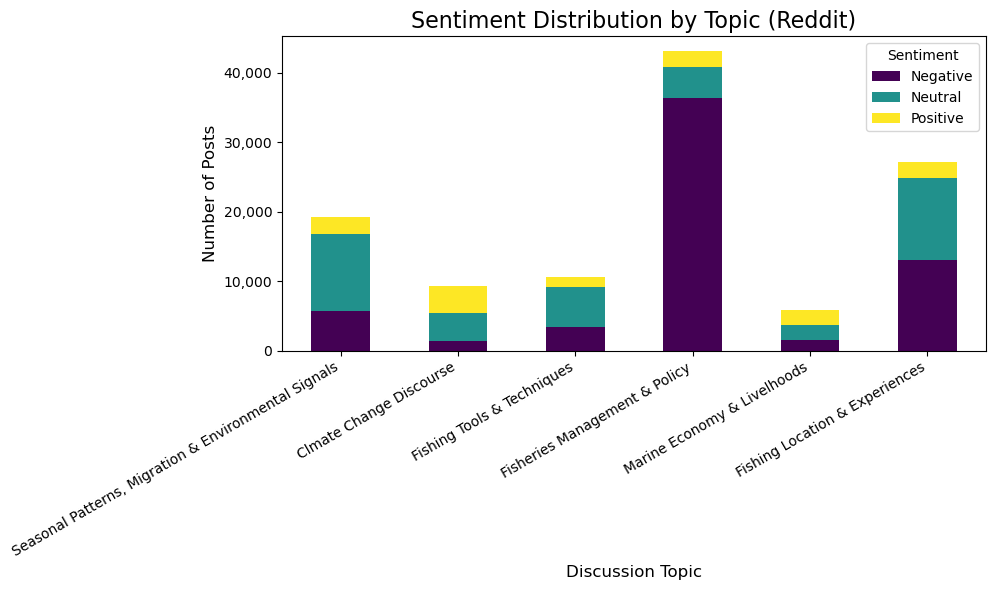

In [216]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Step 1: Remove 'deleted' and 'removed' posts from Topic 4
cleaned_df = df_sampled[
    ~((df_sampled['Topic'] == 4) & df_sampled['CleanedText'].str.contains("deleted|removed", case=False, na=False))
]

# Step 2: Recompute the contingency table using the cleaned dataset
contingency_cleaned = pd.crosstab(cleaned_df['Topic'], cleaned_df['Sentiment_Label'])

# Optional: Rename columns for readability
contingency_cleaned = contingency_cleaned.rename(columns={
    'NEG_Prob': 'Negative',
    'NEU_Prob': 'Neutral',
    'POS_Prob': 'Positive'
})

# Optional: Add topic labels again if needed
topic_labels = {
    0: 'Seasonal Patterns, Migration & Environmental Signals',
    1: 'Clmate Change Discourse',
    2: 'Fishing Tools & Techniques',
    3: 'Fisheries Management & Policy',
    4: 'Marine Economy & Livelhoods',
    5: 'Fishing Location & Experiences'
}
contingency_cleaned.index = contingency_cleaned.index.map(topic_labels)

# Step 3: Plot
ax = contingency_cleaned.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='viridis')

# Format y-axis ticks with commas
formatter = FuncFormatter(lambda x, _: f'{int(x):,}')
ax.yaxis.set_major_formatter(formatter)

plt.title('Sentiment Distribution by Topic (Reddit)', fontsize=16)
plt.xlabel('Discussion Topic', fontsize=12)
plt.ylabel('Number of Posts', fontsize=12)
plt.xticks(rotation=30, ha='right')
plt.legend(title='Sentiment')
plt.tight_layout()
plt.show()

In [222]:
# Step 1: Define the emotion columns
emotion_columns = ['Other', 'Anger', 'Disgust', 'Fear', 'Sadness', 'Joy', 'Surprise']

# Step 2: Assign dominant emotion
reddit['Dominant_Emotion'] = reddit[emotion_columns].idxmax(axis=1)

# Step 3: Preview the result
print(reddit['Dominant_Emotion'].value_counts())

Other       52414
Disgust      6711
Joy          6148
Anger        1004
Surprise      794
Fear          612
Sadness       367
Name: Dominant_Emotion, dtype: int64


In [224]:
print(reddit.columns.tolist())

['subreddit_id', 'approved_at_utc', 'author_is_blocked', 'comment_type', 'edited', 'mod_reason_by', 'banned_by', 'ups', 'num_reports', 'author_flair_type', 'total_awards_received', 'subreddit', 'author_flair_template_id', 'likes', 'replies', 'user_reports', 'saved', 'id', 'banned_at_utc', 'mod_reason_title', 'gilded', 'archived', 'collapsed_reason_code', 'no_follow', 'author', 'can_mod_post', 'send_replies', 'parent_id', 'score', 'author_fullname', 'report_reasons', 'removal_reason', 'approved_by', 'all_awardings', 'body', 'awarders', 'top_awarded_type', 'downs', 'author_flair_css_class', 'author_patreon_flair', 'collapsed', 'author_flair_richtext', 'is_submitter', 'body_html', 'gildings', 'collapsed_reason', 'associated_award', 'stickied', 'author_premium', 'can_gild', 'link_id', 'unrepliable_reason', 'author_flair_text_color', 'score_hidden', 'permalink', 'subreddit_type', 'locked', 'name', 'created', 'author_flair_text', 'treatment_tags', 'created_utc', 'subreddit_name_prefixed', 'c

In [226]:
import gensim
from gensim import corpora
from nltk.corpus import stopwords
import nltk
import re

nltk.download('stopwords')
stop_words = stopwords.words('english')

# Tokenization and cleaning
def preprocess(text):
    text = re.sub(r'[^\w\s]', '', str(text).lower())  # lowercase, remove punctuation
    return [word for word in text.split() if word not in stop_words]

# Apply preprocessing
reddit['tokens'] = reddit['CleanedText'].apply(preprocess)

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/sheffdeen/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [228]:
# Create dictionary and corpus
dictionary = corpora.Dictionary(reddit['tokens'])
corpus = [dictionary.doc2bow(text) for text in reddit['tokens']]

In [230]:
from gensim.models.ldamodel import LdaModel

# Fit the model
lda_model = LdaModel(corpus=corpus, id2word=dictionary, num_topics=6, random_state=42, passes=10)

In [232]:
# Function to get dominant topic for each post
def get_dominant_topic(doc):
    bow = dictionary.doc2bow(doc)
    topics = lda_model.get_document_topics(bow)
    return sorted(topics, key=lambda x: x[1], reverse=True)[0][0] if topics else -1

# Assign topic
reddit['Topic'] = reddit['tokens'].apply(get_dominant_topic)

In [234]:
emotion_table_fb = pd.crosstab(reddit['Topic'], reddit['Dominant_Emotion'])

from scipy.stats import chi2_contingency
chi2, p, dof, expected = chi2_contingency(emotion_table_fb)

print("Chi-square:", chi2)
print("P-value:", p)

Chi-square: 7396.670791331304
P-value: 0.0


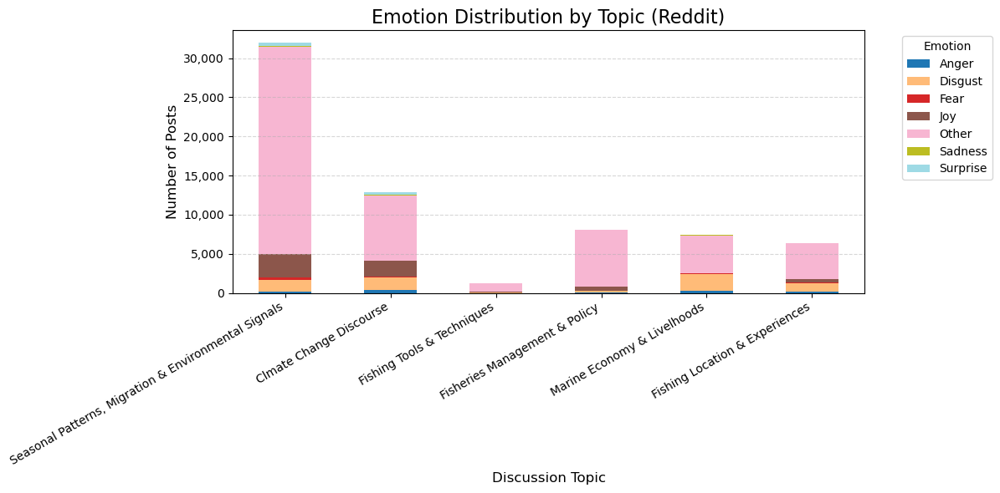

In [236]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import seaborn as sns
import pandas as pd

# Step 1: Create the contingency table again (emotion counts per topic)
emotion_table_redd = pd.crosstab(reddit['Topic'], reddit['Dominant_Emotion'])

# Step 2: Rename topic numbers with clearer labels (optional)
topic_labels_redd = {
    0: 'Seasonal Patterns, Migration & Environmental Signals',
    1: 'Clmate Change Discourse',
    2: 'Fishing Tools & Techniques',
    3: 'Fisheries Management & Policy',
    4: 'Marine Economy & Livelhoods',
    5: 'Fishing Location & Experiences'
}
emotion_table_redd.index = emotion_table_fb.index.map(topic_labels_redd)

# Step 3: Plot
ax = emotion_table_redd.plot(kind='bar', stacked=True, figsize=(12, 6), colormap='tab20')

# Step 4: Format y-axis
formatter = FuncFormatter(lambda x, _: f'{int(x):,}')
ax.yaxis.set_major_formatter(formatter)

# Step 5: Labels
plt.title('Emotion Distribution by Topic (Reddit)', fontsize=16)
plt.xlabel('Discussion Topic', fontsize=12)
plt.ylabel('Number of Posts', fontsize=12)
plt.xticks(rotation=30, ha='right')
plt.legend(title='Emotion', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()


In [250]:
# Filter for posts where the dominant topic is Topic 0
topic_0_posts = df_sampled[df_sampled['Topic'] == 0]

# Sort by confidence (probability) descending
top_topic_0_posts = topic_0_posts.sort_values(by='Confidence', ascending=False)

# Print top N posts with highest probability for Topic 0
print("🔹 Top posts most confidently assigned to Topic 0:")
print(top_topic_0_posts['CleanedText'].head(30).tolist())  # Change head(10) to however many you want

🔹 Top posts most confidently assigned to Topic 0:
["We predicted warmer weather - we're seeing warmer weather. We predicted melting glaciers - we're seeing melting glaciers. We predicted stronger storms- we're seeing stronger storms. We predicted devastating droughts - we're seeing devastating droughts. We predicted deadly heat waves - we're seeing deadly heat waves. We predicted rising sea levels - we're seeing rising sea levels. fkn moron.", 'It all depends on the weather conditions and water conditions. There can be salmon as early as July if it has rained lots, and if the weather is fairly cool. As of right now, there are salmon running in port hope.', "Even if that's the case, a few baseboard heaters that might turn on a few times a year aren't exactly a deal breaker. You're still using less energy because the more efficient heat pump is doing the vast majority of the heating.", 'We service all the mines up by wollaston year round. And also deliver to points north. You can drive u

In [252]:
# Filter for posts where the dominant topic is Topic 1
topic_1_posts = df_sampled[df_sampled['Topic'] == 1]

# Sort by confidence (probability) descending
top_topic_1_posts = topic_1_posts.sort_values(by='Confidence', ascending=False)

# Print top N posts with highest probability for Topic 1
print("🔹 Top posts most confidently assigned to Topic 1:")
print(top_topic_1_posts['CleanedText'].head(30).tolist())  # Change head(10) to however many you want

🔹 Top posts most confidently assigned to Topic 1:
['Planting trees is criticized because they dont sequester much carbon when theyre young. It takes at least twenty years for them to grow into something that has an appreciable affect. I still think its worthwhile but only in addition to cutting our emissions enormously as a harm reduction measure after weve sorted ourselves out. It doesnt work in isolation.', 'SK, AB average citizens make money back on carbon rebates and the people that dont are exactly the type of people that need to incentivized the most. Stop spouting headlines, the data doesnt back up your claims.', "So, if I understand correctly, you have zero data. The Bank of Canada, not tiff, but The Bank of Canada does have data, and their data is independently corroborated by a U of C economist. But they're all wrong. You can't prove it, you can't come anywhere close to even beginning to make a cogent argument against their results. But they're just wrong? Do you sort of star

In [254]:
# Filter for posts where the dominant topic is Topic 0
topic_2_posts = df_sampled[df_sampled['Topic'] == 2]

# Sort by confidence (probability) descending
top_topic_2_posts = topic_2_posts.sort_values(by='Confidence', ascending=False)

# Print top N posts with highest probability for Topic 2
print("🔹 Top posts most confidently assigned to Topic 2")
print(top_topic_2_posts['CleanedText'].head(30).tolist())  # Change head(10) to however many you want

🔹 Top posts most confidently assigned to Topic 2
['1. 6 5 ft medium fast rod worm harness 2. 6 5 ft medium fast rod worm harness 3. 6 5 ft medium fast rod worm harness 4. 6 5 ft medium fast rod worm harness.', 'I found large nuts from bolts work well. If you use a leader attached to a swivel, you can use a lighter line attached to swivel so that the weight line breaks before the leader will, if you get a snag.', "Braided line has more sensitivity, as well as zero stretch. Fluorocarbon has no stretch aswell. But a little less sensitivity. You don't NEED a leader unless fishing in ultra clear water. Gotta learn to tie a uni knot for the leader.", "I use it for drop shot, Ned rig and tubes. Wacky rig is a good one too as you've already mentioned. Anything with an exposed light wire hook.", 'Id upsize the rod and reel i try not to play sturgeon too hard so ive got a 50lb rod, 50lb braid, and a baitcaster that does 24 lbs before i thumb down.', 'Forgot to put. and;x200B; I want the both to 

In [256]:
# Filter for posts where the dominant topic is Topic 0
topic_3_posts = df_sampled[df_sampled['Topic'] == 3]

# Sort by confidence (probability) descending
top_topic_3_posts = topic_3_posts.sort_values(by='Confidence', ascending=False)

# Print top N posts with highest probability for Topic 3
print("🔹 Top posts most confidently assigned to Topic 3")
print(top_topic_3_posts['CleanedText'].head(30).tolist())  # Change head(10) to however many you want

🔹 Top posts most confidently assigned to Topic 3
['I was under the impression youre not supposed to release carp. Prussian carp for sure, but I just went through the angling guide and theres a lack of information and limits on common carp.', 'I had no idea these were in Ontario waters Are they proper sport fish or more garbage-y carp, sheephead type things?', 'Fish Creek is not listed as a tributary for the Bow River, nor is it listed as a creek or stream in the regulations. Default ES1 regulations apply.', 'Good to know! Got this one to get started into the sport, and if things go well Ill definitely be looking into some different outfits. Thanks for your replies in this thread!', 'Thats exactly what Ive been leaning towards. Im still new to the electronics side of fishing, so this is a helpful recommendation. Thank you. What swayed you towards the Helix 5 versus other models, brands?', 'Is there a more detailed breakdown of this contest? Like favourite and subscribe what? I get subsc

In [258]:
# Filter for posts where the dominant topic is Topic 0
topic_4_posts = df_sampled[df_sampled['Topic'] == 4]

# Sort by confidence (probability) descending
top_topic_4_posts = topic_4_posts.sort_values(by='Confidence', ascending=False)

# Print top N posts with highest probability for Topic 4
print("🔹 Top posts most confidently assigned to Topic 4")
print(top_topic_4_posts['CleanedText'].head(30).tolist())  # Change head(10) to however many you want

🔹 Top posts most confidently assigned to Topic 4
["You're still operating under the conception that an increase of the supply of money is the same thing as inflation. An increase in the supply of money in an economy can cause inflation, but it isn't inflation. They are different things.", 'No they are not. One is inflation, one is increasing prices. Inflation is always monetary. Prices can increase without inflation and inflation can happen without price increases.', 'Not really. Despite higher instances of evasion, and avoidance (and avoision), tax revenues still increase when taxes are raised. So, no, not a compelling reason not to raise taxes.', 'I am not here to defend any party, I just care if a policy is good or bad. Any government can do that regardless if you like them or not. For instance, I think the conservatives have the best housing plan.', "The harper government sold the world the idea that Canada's economy should be linked to oil. That was really good when oil prices wer

In [260]:
# Filter for posts where the dominant topic is Topic 0
topic_5_posts = df_sampled[df_sampled['Topic'] == 5]

# Sort by confidence (probability) descending
top_topic_5_posts = topic_5_posts.sort_values(by='Confidence', ascending=False)

# Print top N posts with highest probability for Topic 5
print("🔹 Top posts most confidently assigned to Topic 5")
print(top_topic_5_posts['CleanedText'].head(30).tolist())  # Change head(10) to however many you want

🔹 Top posts most confidently assigned to Topic 5
["The canal in Port Dalhousie is a good spot but it's definitely not for family during the salmon run and trout season. When it's busy the people there are a bit brash to say the least. You can drop them off at the marina, a cafe, or the beach and there'd be something for your family to do while you fish the canal. The summer is a lot more chill.", "It's a shallow lake, it gets weedy. Was weedy 40yrs ago, still weedy. There are parts of the lake that don't have weeds, fish those at 11pm with big stickbaits and you up your odds of catching the elusive Rice Lake Pickeral.", "So much of fishing is being in the right place at the right time. You can be doing everything absolutely perfectly, but if there's no fish there obviously you won't catch anything. Don't be hard on yourself if you're getting skunked, it's all part of fishing and the days with no fish makes the days you do get fish so much sweeter. Good luck out there!", 'When you pull 

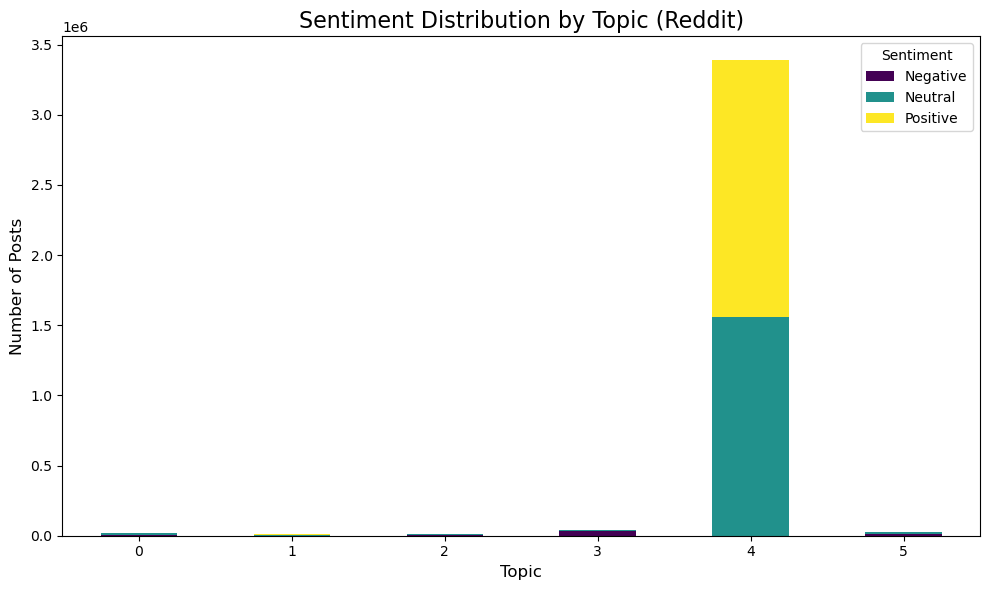

In [130]:
import matplotlib.pyplot as plt

# Rename columns for clarity
contingency.columns = ['Negative', 'Neutral', 'Positive']

# Plot
contingency.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='viridis')

plt.title('Sentiment Distribution by Topic (Reddit)', fontsize=16)
plt.xlabel('Topic', fontsize=12)
plt.ylabel('Number of Posts', fontsize=12)
plt.xticks(rotation=0)
plt.legend(title='Sentiment')
plt.tight_layout()
plt.show()